#LNPHub cross-study delivery analysis

This notebook analyzes which ionizable-lipid chemical features and formulation factors are repeatedly associated with high delivery across independent LNPHub screening contexts.
Important safeguards:

raw delivery values are never pooled directly across studies;

delivery performance is rank-normalized within comparable screening contexts;

repeated LNP measurements within a screen are collapsed to one screen_id x lnp_id row;

cross-study evidence is summarized from screen-level effects using random-effects meta-analysis;

source data are exported for every panel.

In [1]:
# Cell 0 - Install packages in Colab
# Runtime > Run all will install these once per Colab runtime.
!pip -q install umap-learn rdkit pillow openpyxl xlsxwriter
!pip install pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 52.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 73.5 MB/s eta 0:00:00


#Cell 1 — Imports and reproducibility

In [2]:
from pathlib import Path
from collections import OrderedDict
import json
import math
import re
import warnings

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as patches
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

import seaborn as sns
from scipy import stats

from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
import umap

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
RDLogger.DisableLog("rdApp.*")

try:
    display
except NameError:
    def display(obj):
        print(obj.to_string(index=False) if hasattr(obj, "to_string") else obj)

DPI = 600
MIN_SCREEN_SIZE = 30
MIN_CLASS_SUPPORT_PER_SCREEN = 5
MIN_META_SCREENS = 5
MIN_HEADN_UNIQUE_LIPIDS = 10
MIN_HEADN_SCREENS = 3

CSV_PATH = Path("lnphub_master_v2.0.0.csv")
OUTPUT_ROOT = Path("/content/cross_study_analysis")

DIRS = {
    "notebook": OUTPUT_ROOT / "notebook",
    "main_figures": OUTPUT_ROOT / "main_figures",
    "supplementary_figures": OUTPUT_ROOT / "supplementary_figures",
    "panels": OUTPUT_ROOT / "panels",
    "source_data": OUTPUT_ROOT / "source_data",
    "tables": OUTPUT_ROOT / "tables",
    "statistics": OUTPUT_ROOT / "statistics",
    "logs": OUTPUT_ROOT / "logs",
}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#111827",
    "axes.linewidth": 0.7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.bbox": "tight",
    "savefig.facecolor": "white",
})

COLORS = {
    "ink": "#111827",
    "muted": "#6B7280",
    "grid": "#E5E7EB",
    "blue": "#0072B2",
    "teal": "#009E73",
    "orange": "#D55E00",
    "purple": "#6D5BD0",
    "rose": "#CC79A7",
    "sky": "#56B4E9",
    "gray": "#9CA3AF",
    "light": "#F8FAFC",
}

GROUP_COLORS = OrderedDict([
    ("Amino lipid", "#0072B2"),
    ("Lipidoid", "#009E73"),
    ("Dendritic lipid", "#6D5BD0"),
    ("Branched lipid", "#D55E00"),
    ("Heterocyclic lipid", "#CC79A7"),
    ("Phospholipid / biomimetic lipid", "#56B4E9"),
    ("Aromatic / rigid-scaffold lipid", "#A6761D"),
    ("Other biodegradable / specialty lipid", "#4B5563"),
    ("Other / named lipid", "#9CA3AF"),
])

def fmt_int(x):
    if pd.isna(x):
        return "NA"
    return f"{int(round(float(x))):,}"

def clean_label(x):
    if pd.isna(x) or str(x).strip() == "":
        return "Not reported"
    return str(x).replace("_", " ")

def non_missing_mask(s):
    if s.dtype == object or str(s.dtype).startswith("string"):
        text = s.astype(str).str.strip()
        return s.notna() & text.ne("") & ~text.str.lower().isin(["nan", "none", "na", "n/a", "not reported"])
    return s.notna()

def present_cols(data, cols):
    return [c for c in cols if c in data.columns]

def row_has_any(data, cols):
    cols = present_cols(data, cols)
    if not cols:
        return pd.Series(False, index=data.index)
    out = pd.Series(False, index=data.index)
    for col in cols:
        out = out | non_missing_mask(data[col])
    return out

def save_source(data, name):
    path = DIRS["source_data"] / f"{name}.csv"
    data.to_csv(path, index=False)
    print(f"source data -> {path}")
    return path

def save_table(data, name):
    csv_path = DIRS["tables"] / f"{name}.csv"
    xlsx_path = DIRS["tables"] / f"{name}.xlsx"
    data.to_csv(csv_path, index=False)
    try:
        data.to_excel(xlsx_path, index=False)
    except Exception as exc:
        print(f"Could not write XLSX for {name}: {exc}")
    print(f"table -> {csv_path}")
    return csv_path

def save_figure(fig, name, folder):
    paths = []
    for ext in ["pdf", "svg", "png"]:
        path = folder / f"{name}.{ext}"
        fig.savefig(path, dpi=DPI if ext == "png" else None, bbox_inches="tight", pad_inches=0.01)
        paths.append(path)
    print("saved:")
    for path in paths:
        print(" ", path)
    return paths

def add_panel_label(ax, label, x=-0.08, y=1.04):
    ax.text(
        x, y, label, transform=ax.transAxes, ha="left", va="bottom",
        fontsize=11, fontweight="bold", color=COLORS["ink"]
    )

def bh_fdr(p_values):
    p = np.asarray(p_values, dtype=float)
    q = np.full_like(p, np.nan, dtype=float)
    valid = np.isfinite(p)
    if valid.sum() == 0:
        return q
    pv = p[valid]
    order = np.argsort(pv)
    ranks = np.arange(1, len(pv) + 1)
    q_sorted = pv[order] * len(pv) / ranks
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]
    q_valid = np.empty_like(pv)
    q_valid[order] = np.minimum(q_sorted, 1.0)
    q[valid] = q_valid
    return q

def random_effects_meta(effect, variance):
    effect = np.asarray(effect, dtype=float)
    variance = np.asarray(variance, dtype=float)
    keep = np.isfinite(effect) & np.isfinite(variance) & (variance > 0)
    effect = effect[keep]
    variance = variance[keep]
    k = len(effect)
    if k == 0:
        return dict(k=0, pooled=np.nan, ci_low=np.nan, ci_high=np.nan, se=np.nan, p=np.nan, tau2=np.nan, i2=np.nan)
    if k == 1:
        se = float(np.sqrt(variance[0]))
        z = float(effect[0] / se) if se > 0 else np.nan
        p = float(2 * stats.norm.sf(abs(z))) if np.isfinite(z) else np.nan
        return dict(k=1, pooled=float(effect[0]), ci_low=float(effect[0] - 1.96 * se), ci_high=float(effect[0] + 1.96 * se), se=se, p=p, tau2=0.0, i2=0.0)

    w = 1 / variance
    fixed = np.sum(w * effect) / np.sum(w)
    q = np.sum(w * (effect - fixed) ** 2)
    df_q = k - 1
    c = np.sum(w) - np.sum(w ** 2) / np.sum(w)
    tau2 = max(0.0, (q - df_q) / c) if c > 0 else 0.0
    wr = 1 / (variance + tau2)
    pooled = np.sum(wr * effect) / np.sum(wr)
    se = np.sqrt(1 / np.sum(wr))
    ci_low = pooled - 1.96 * se
    ci_high = pooled + 1.96 * se
    z = pooled / se if se > 0 else np.nan
    p = 2 * stats.norm.sf(abs(z)) if np.isfinite(z) else np.nan
    i2 = max(0.0, (q - df_q) / q) * 100 if q > 0 else 0.0
    return dict(k=k, pooled=float(pooled), ci_low=float(ci_low), ci_high=float(ci_high), se=float(se), p=float(p), tau2=float(tau2), i2=float(i2))

def fisher_z_from_r(r):
    r = np.clip(float(r), -0.999999, 0.999999)
    return np.arctanh(r)

def r_from_fisher_z(z):
    return np.tanh(z)

def spearman_screen_effect(data, feature, flag_col="top10_flag", min_each=2):
    d = data[[feature, flag_col]].copy()
    d[feature] = pd.to_numeric(d[feature], errors="coerce")
    d = d.dropna()
    if len(d) < 6 or d[feature].nunique() < 2 or d[flag_col].nunique() < 2:
        return None
    n_top = int(d[flag_col].sum())
    n_non = int(len(d) - n_top)
    if n_top < min_each or n_non < min_each:
        return None
    rho, p = stats.spearmanr(d[feature], d[flag_col])
    if not np.isfinite(rho):
        return None
    variance = 1 / max(len(d) - 3, 1)
    return {
        "effect_r": float(rho),
        "effect_z": fisher_z_from_r(rho),
        "variance_z": float(variance),
        "p_screen": float(p) if np.isfinite(p) else np.nan,
        "n": int(len(d)),
        "n_top": n_top,
        "n_non_top": n_non,
    }

def meta_analyze_continuous_effects(data, features, flag_col="top10_flag", min_screens=MIN_META_SCREENS):
    screen_rows = []
    for feature in present_cols(data, features):
        for screen_id, sdf in data.groupby("screen_id"):
            eff = spearman_screen_effect(sdf, feature, flag_col=flag_col)
            if eff is None:
                continue
            screen_rows.append({
                "feature": feature,
                "screen_id": screen_id,
                "study_id": sdf["study_id"].iloc[0],
                "experimental_setting": sdf["experimental_setting"].iloc[0],
                "cargo_type": sdf["cargo_type"].iloc[0],
                **eff,
            })
    screen_effects = pd.DataFrame(screen_rows)
    meta_rows = []
    if not screen_effects.empty:
        for feature, fdf in screen_effects.groupby("feature"):
            # Keep one effect per study-screen. The screen is the replication unit.
            meta = random_effects_meta(fdf["effect_z"], fdf["variance_z"])
            meta_rows.append({
                "feature": feature,
                "n_screens": int(meta["k"]),
                "pooled_z": meta["pooled"],
                "pooled_effect": r_from_fisher_z(meta["pooled"]) if np.isfinite(meta["pooled"]) else np.nan,
                "ci_low": r_from_fisher_z(meta["ci_low"]) if np.isfinite(meta["ci_low"]) else np.nan,
                "ci_high": r_from_fisher_z(meta["ci_high"]) if np.isfinite(meta["ci_high"]) else np.nan,
                "p_value": meta["p"],
                "tau2": meta["tau2"],
                "i2": meta["i2"],
                "directional_consistency": np.nan,
            })
    meta_df = pd.DataFrame(meta_rows)
    if not meta_df.empty:
        meta_df["q_value"] = bh_fdr(meta_df["p_value"])
        consistency = []
        for _, row in meta_df.iterrows():
            fdf = screen_effects[screen_effects["feature"] == row["feature"]]
            pooled_sign = np.sign(row["pooled_effect"])
            if pooled_sign == 0 or not np.isfinite(pooled_sign):
                consistency.append(np.nan)
            else:
                consistency.append(float((np.sign(fdf["effect_r"]) == pooled_sign).mean()))
        meta_df["directional_consistency"] = consistency
        meta_df["passes_support"] = meta_df["n_screens"] >= min_screens
        meta_df["passes_robustness_rule"] = (
            (meta_df["n_screens"] >= min_screens)
            & (meta_df["q_value"] < 0.05)
            & (meta_df["directional_consistency"] >= 0.70)
        )
        meta_df = meta_df.sort_values("pooled_effect", ascending=True).reset_index(drop=True)
    return screen_effects, meta_df

def categorical_screen_or(data, feature, level, flag_col="top10_flag", min_total=5):
    d = data[[feature, flag_col]].copy()
    d = d.dropna()
    d = d[d[feature].astype(str).str.strip().ne("")]
    if d.empty:
        return None
    present = d[feature].astype(str) == str(level)
    total_present = int(present.sum())
    if total_present < min_total:
        return None
    top = d[flag_col].astype(bool)
    a = int((present & top).sum())
    b = int((present & ~top).sum())
    c = int((~present & top).sum())
    dd = int((~present & ~top).sum())
    if (a + c) == 0 or (b + dd) == 0:
        return None
    log_or = math.log(((a + 0.5) * (dd + 0.5)) / ((b + 0.5) * (c + 0.5)))
    var = 1/(a + 0.5) + 1/(b + 0.5) + 1/(c + 0.5) + 1/(dd + 0.5)
    return {
        "log_or": float(log_or),
        "variance": float(var),
        "n": int(len(d)),
        "n_with_feature": total_present,
        "top_with_feature": a,
        "non_top_with_feature": b,
        "top_without_feature": c,
        "non_top_without_feature": dd,
    }

def meta_analyze_categorical(data, features, flag_col="top10_flag", min_total=5):
    screen_rows = []
    for feature in present_cols(data, features):
        levels = sorted([x for x in data[feature].dropna().astype(str).unique() if x.strip() != ""])
        for level in levels:
            for screen_id, sdf in data.groupby("screen_id"):
                eff = categorical_screen_or(sdf, feature, level, flag_col=flag_col, min_total=min_total)
                if eff is None:
                    continue
                screen_rows.append({
                    "feature": feature,
                    "level": level,
                    "factor": f"{feature}: {level}",
                    "screen_id": screen_id,
                    "study_id": sdf["study_id"].iloc[0],
                    "experimental_setting": sdf["experimental_setting"].iloc[0],
                    "cargo_type": sdf["cargo_type"].iloc[0],
                    **eff,
                })
    screen_effects = pd.DataFrame(screen_rows)
    meta_rows = []
    if not screen_effects.empty:
        for factor, fdf in screen_effects.groupby("factor"):
            meta = random_effects_meta(fdf["log_or"], fdf["variance"])
            feature = fdf["feature"].iloc[0]
            level = fdf["level"].iloc[0]
            pooled = meta["pooled"]
            meta_rows.append({
                "feature": feature,
                "level": level,
                "factor": factor,
                "n_screens": int(meta["k"]),
                "pooled_log_or": pooled,
                "pooled_or": float(np.exp(pooled)) if np.isfinite(pooled) else np.nan,
                "ci_low_or": float(np.exp(meta["ci_low"])) if np.isfinite(meta["ci_low"]) else np.nan,
                "ci_high_or": float(np.exp(meta["ci_high"])) if np.isfinite(meta["ci_high"]) else np.nan,
                "p_value": meta["p"],
                "tau2": meta["tau2"],
                "i2": meta["i2"],
            })
    meta_df = pd.DataFrame(meta_rows)
    if not meta_df.empty:
        meta_df["q_value"] = bh_fdr(meta_df["p_value"])
        consistency = []
        for _, row in meta_df.iterrows():
            fdf = screen_effects[screen_effects["factor"] == row["factor"]]
            pooled_sign = np.sign(row["pooled_log_or"])
            consistency.append(float((np.sign(fdf["log_or"]) == pooled_sign).mean()) if pooled_sign != 0 else np.nan)
        meta_df["directional_consistency"] = consistency
        meta_df["passes_robustness_rule"] = (
            (meta_df["n_screens"] >= MIN_META_SCREENS)
            & (meta_df["q_value"] < 0.05)
            & (meta_df["directional_consistency"] >= 0.70)
        )
        meta_df = meta_df.sort_values("pooled_log_or", ascending=True).reset_index(drop=True)
    return screen_effects, meta_df

def pretty_feature_name(x):
    mapping = {
        "heavy_atoms": "Heavy atoms",
        "rings": "Rings",
        "aromatic_rings": "Aromatic rings",
        "rotatable_bonds": "Rotatable bonds",
        "van_der_waals_molecular_volume": "VDW molecular volume",
        "topological_polar_surface_area": "TPSA",
        "hydrogen_bond_donors": "H-bond donors",
        "hydrogen_bond_acceptors": "H-bond acceptors",
        "logp": "logP",
        "molar_refractivity": "Molar refractivity",
        "fraction_sp3_carbons": "Fraction sp3 carbons",
        "sp3_carbons": "sp3 carbons",
        "nitrogen_count": "Nitrogen count",
        "molecular_weight": "Molecular weight",
        "il_mol_ratio": "Ionizable lipid mol%",
        "helper_lipid_mol_ratio": "Helper lipid mol%",
        "cholesterol_mol_ratio": "Cholesterol mol%",
        "peg_lipid_mol_ratio": "PEG lipid mol%",
        "particle_size_nm": "Particle size",
        "pdi": "PDI",
        "zeta_potential_mv": "Zeta potential",
        "encapsulation_efficiency_percent": "Encapsulation efficiency",
        "measured_pka": "pKa",
    }
    return mapping.get(x, clean_label(x))

print("Output root:", OUTPUT_ROOT)

Output root: /content/cross_study_analysis


#Cell 2 — Load final LNPHub dataset

In [ ]:
df_raw = pd.read_csv(CSV_PATH, low_memory=False)
df = df_raw.copy()

print("Loaded final LNPHub CSV:")
print(" path:", CSV_PATH)
print(" rows:", fmt_int(len(df)))
print(" columns:", fmt_int(len(df.columns)))
print("Original CSV was read only; all analysis uses dataframe copies.")

Loaded final LNPHub CSV:
 path: lnphub_master_v2.0.0.csv
 rows: 23,682
 columns: 99
Original CSV was read only; all analysis uses dataframe copies.


#Cell 3 — Dataset audit and delivery-column detection

In [ ]:

delivery_col = "delivery" if "delivery" in df.columns else "delivery_value" if "delivery_value" in df.columns else None
delivery_metric_col = "delivery_metric" if "delivery_metric" in df.columns else "delivery_value_method" if "delivery_value_method" in df.columns else None
zeta_col = "zeta_potential_mv" if "zeta_potential_mv" in df.columns else None
zeta_meta_col = "zeta_potential_metric" if "zeta_potential_metric" in df.columns else "zeta_potential_method" if "zeta_potential_method" in df.columns else None

if delivery_col is None:
    raise ValueError("No delivery column detected.")

audit = {
    "rows": len(df),
    "studies": df["study_id"].nunique(dropna=True),
    "unique_lnps": df["lnp_id"].nunique(dropna=True),
    "unique_ionizable_lipid_structures": df["il_smiles"].nunique(dropna=True),
    "delivery_column": delivery_col,
    "delivery_metric_column": delivery_metric_col,
    "zeta_potential_column": zeta_col,
    "zeta_potential_metadata_column": zeta_meta_col,
}

print("Dataset audit")
for k, v in audit.items():
    print(f"{k}: {v if isinstance(v, str) or v is None else fmt_int(v)}")

print("\nAvailable columns")
for c in df.columns:
    print(" -", c)

print("\nDelivery metric categories")
if delivery_metric_col:
    print(df[delivery_metric_col].fillna("Not reported").value_counts().to_string())

print("\nExperimental setting categories")
print(df["experimental_setting"].fillna("Not reported").value_counts().to_string())

print("\nCargo type categories")
print(df["cargo_type"].fillna("Not reported").value_counts().to_string())

study_audit = (
    df.groupby("study_id", dropna=False)
    .agg(
        records=("record_id", "count"),
        delivery_records=(delivery_col, lambda s: int(non_missing_mask(s).sum())),
        unique_lnps=("lnp_id", pd.Series.nunique),
        unique_ionizable_lipids=("il_smiles", pd.Series.nunique),
    )
    .reset_index()
    .sort_values("records", ascending=False)
)

save_source(pd.DataFrame([audit]), "dataset_audit_summary")
save_source(study_audit, "dataset_audit_by_study")
display(study_audit.head(60))

Dataset audit
rows: 23,682
studies: 60
unique_lnps: 21,197
unique_ionizable_lipid_structures: 14,993
delivery_column: delivery
delivery_metric_column: delivery_metric
zeta_potential_column: zeta_potential_mv
zeta_potential_metadata_column: zeta_potential_metric

Available columns
 - record_id
 - study_id
 - publication_link
 - lnp_id
 - il_id
 - il_smiles
 - il_class
 - reaction_type
 - il_architecture_type
 - il_head_smiles
 - il_head_class
 - il_head_architecture
 - il_linker_smiles
 - il_linker_class
 - il_tail_count
 - il_tail1_id
 - il_tail1_smiles
 - il_tail1_class
 - il_tail2_id
 - il_tail2_smiles
 - il_tail2_class
 - il_tail3_id
 - il_tail3_smiles
 - il_tail3_class
 - il_tail4_id
 - il_tail4_smiles
 - il_tail4_class
 - il_tail5_id
 - il_tail5_smiles
 - il_tail5_class
 - il_tail6_id
 - il_tail6_smiles
 - il_tail6_class
 - helper_lipid_name
 - helper_lipid_smiles
 - helper_lipid_mol_ratio
 - cholesterol_name
 - cholesterol_smiles
 - cholesterol_mol_ratio
 - peg_lipid_name
 - peg_

,study_id,records,delivery_records,unique_lnps,unique_ionizable_lipids
51,LNPhub_YX_2024,2400,2400,2400,1200
16,LNPhub_JW_2024,1745,1745,1683,233
20,LNPhub_KZ_2016,1538,1538,1536,1470
19,LNPhub_KW_2014,1198,1182,1175,1150
24,LNPhub_LM_2019,1128,1128,1080,1080
55,LNPhub_YZ_2022,1080,1080,1080,1
56,LNPhub_YZ_2024,1080,1080,1080,1
8,LNPhub_FG_2026,1043,1042,1021,960
26,LNPhub_LX_2024,846,180,250,180
3,LNPhub_BL_2023,773,773,759,711


# Cell 4 — Define eligible screening contexts

In [ ]:


# Cell 4 — Define eligible screening contexts

context_fields = [
    "study_id",
    "experimental_setting",
    "cargo_type",
    "biological_model",
    "biological_target",
    "route_of_administration",
]
if delivery_metric_col:
    context_fields.append(delivery_metric_col)

# Use the same threshold for both unique LNPs and unique ionizable lipids.
MIN_UNIQUE_IL_PER_SCREEN = MIN_SCREEN_SIZE

work = df.copy()
work[delivery_col] = pd.to_numeric(work[delivery_col], errors="coerce")
work = work.dropna(subset=[delivery_col, "study_id", "lnp_id", "il_smiles"]).copy()

for col in context_fields:
    if col in work.columns:
        work[col] = work[col].fillna("Not reported").astype(str).replace({"": "Not reported"})

screen_parts = [c for c in context_fields if c in work.columns]
work["screen_id"] = work[screen_parts].agg(" | ".join, axis=1)

screen_context_rows = []
for study_id, sdf in work.groupby("study_id", dropna=False):
    row = {"study_id": study_id}
    for field in screen_parts:
        row[f"{field}_levels_within_study"] = int(sdf[field].nunique(dropna=False))
    screen_context_rows.append(row)

screen_definition_table = pd.DataFrame(screen_context_rows)

screen_sizes_all = (
    work.groupby("screen_id", dropna=False)
    .agg(
        study_id=("study_id", "first"),
        records=("record_id", "count"),
        unique_lnps=("lnp_id", pd.Series.nunique),
        unique_ionizable_lipids=("il_smiles", pd.Series.nunique),
        experimental_setting=("experimental_setting", "first"),
        cargo_type=("cargo_type", "first"),
        biological_model=("biological_model", "first"),
        biological_target=("biological_target", "first"),
        route_of_administration=("route_of_administration", "first"),
        delivery_metric=(delivery_metric_col, "first") if delivery_metric_col else ("study_id", "first"),
    )
    .reset_index()
    .sort_values(["unique_lnps", "unique_ionizable_lipids"], ascending=False)
)

sensitivity_screen_rows = []
for threshold in [8, 10, 15, 20]:
    eligible_mask = (
        (screen_sizes_all["unique_lnps"] >= threshold)
        & (screen_sizes_all["unique_ionizable_lipids"] >= threshold)
    )
    eligible_ids = screen_sizes_all.loc[eligible_mask, "screen_id"]
    eligible_work = work[work["screen_id"].isin(eligible_ids)]

    sensitivity_screen_rows.append({
        "min_unique_lnps_per_screen": threshold,
        "min_unique_ionizable_lipids_per_screen": threshold,
        "eligible_screens": int(len(eligible_ids)),
        "eligible_studies": int(eligible_work["study_id"].nunique()),
        "delivery_records_retained": int(len(eligible_work)),
        "unique_lnps_retained": int(eligible_work["lnp_id"].nunique()),
        "unique_il_smiles_retained": int(eligible_work["il_smiles"].nunique()),
    })

screen_threshold_sensitivity = pd.DataFrame(sensitivity_screen_rows)

eligible_screen_mask = (
    (screen_sizes_all["unique_lnps"] >= MIN_SCREEN_SIZE)
    & (screen_sizes_all["unique_ionizable_lipids"] >= MIN_UNIQUE_IL_PER_SCREEN)
)
eligible_screen_ids = screen_sizes_all.loc[eligible_screen_mask, "screen_id"]

eligible_rows = work[work["screen_id"].isin(eligible_screen_ids)].copy()
eligible_screen_sizes = screen_sizes_all[
    screen_sizes_all["screen_id"].isin(eligible_screen_ids)
].copy()

save_source(screen_definition_table, "screen_context_field_variation_by_study")
save_source(screen_sizes_all, "all_screen_context_sizes")
save_source(screen_threshold_sensitivity, "screen_threshold_sensitivity")
save_source(eligible_screen_sizes, "eligible_screen_context_sizes")

print("Context fields used:", screen_parts)
print("Main minimum unique LNPs per screen:", MIN_SCREEN_SIZE)
print("Main minimum unique ionizable lipids per screen:", MIN_UNIQUE_IL_PER_SCREEN)
print(screen_threshold_sensitivity.to_string(index=False))

pd.set_option("display.max_rows", None)

display(eligible_screen_sizes.sort_values("experimental_setting"))


source data -> /content/cross_study_analysis/source_data/screen_context_field_variation_by_study.csv
source data -> /content/cross_study_analysis/source_data/all_screen_context_sizes.csv
source data -> /content/cross_study_analysis/source_data/screen_threshold_sensitivity.csv
source data -> /content/cross_study_analysis/source_data/eligible_screen_context_sizes.csv
Context fields used: ['study_id', 'experimental_setting', 'cargo_type', 'biological_model', 'biological_target', 'route_of_administration', 'delivery_metric']
Main minimum unique LNPs per screen: 30
 min_unique_lnps_per_screen  eligible_screens  eligible_studies  delivery_records_retained  unique_lnps_retained  unique_il_smiles_retained
                          8                92                53                      21094                 20050                      14075
                         10                91                53                      21085                 20049                      14075
             

,screen_id,study_id,records,unique_lnps,unique_ionizable_lipids,experimental_setting,cargo_type,biological_model,biological_target,route_of_administration,delivery_metric
43,LNPhub_JW_2024 | in_vitro | mRNA | A549 | lung...,LNPhub_JW_2024,1644,1585,161,in_vitro,mRNA,A549,lung_epithelium,Not reported,expression
104,LNPhub_ZL_2022 | in_vitro | mRNA | HEK293T | N...,LNPhub_ZL_2022,144,144,144,in_vitro,mRNA,HEK293T,Not reported,Not reported,expression
37,LNPhub_JK_2026 | in_vitro | mRNA | DC2.4 | den...,LNPhub_JK_2026,139,136,68,in_vitro,mRNA,DC2.4,dendritic_cells,Not reported,expression
97,LNPhub_YY_2023 | in_vitro | mRNA | IGROV1 | No...,LNPhub_YY_2023,119,119,119,in_vitro,mRNA,IGROV1,Not reported,Not reported,expression_discretized
82,LNPhub_XH_2024c | in_vitro | mRNA | HepG2 | No...,LNPhub_XH_2024c,124,100,100,in_vitro,mRNA,HepG2,Not reported,Not reported,expression
100,LNPhub_ZC_2023 | in_vitro | mRNA | IGROV1 | No...,LNPhub_ZC_2023,100,100,100,in_vitro,mRNA,IGROV1,Not reported,Not reported,expression_discretized
17,LNPhub_CW_2025 | in_vitro | mRNA | HaCaT | ker...,LNPhub_CW_2025,100,100,100,in_vitro,mRNA,HaCaT,keratinocytes,Not reported,expression
68,LNPhub_SL_2020 | in_vitro | mRNA | IGROV1 | No...,LNPhub_SL_2020,91,91,63,in_vitro,mRNA,IGROV1,Not reported,Not reported,expression_discretized
80,LNPhub_XH_2024b | in_vitro | mRNA | HepG2 | No...,LNPhub_XH_2024b,90,90,90,in_vitro,mRNA,HepG2,Not reported,Not reported,expression
42,LNPhub_JM_2016 | in_vitro | siRNA | HeLa | Not...,LNPhub_JM_2016,72,72,72,in_vitro,siRNA,HeLa,Not reported,Not reported,expression_discretized


In [ ]:
zz = eligible_screen_sizes.sort_values("experimental_setting")
zz.to_csv("screens.csv", index=False)

In [ ]:
len(eligible_screen_sizes)

61

# Cell 5 — Construct within-screen delivery ranks





In [ ]:
# Cell 5 — Construct within-screen delivery ranks

il_class_group_map = {
    "amino lipid": "Amino lipid",
    "biodegradable amino lipid": "Amino lipid",
    "biodegradable lipid": "Amino lipid",
    "zwitterionic amino lipid": "Amino lipid",
    "amino lipidoid": "Lipidoid",
    "biodegradable lipidoid": "Lipidoid",
    "siloxane-based lipidoid": "Lipidoid",
    "multitailed lipidoid": "Lipidoid",
    "dendrimeric lipid": "Dendritic lipid",
    "biodegradable dendrimeric lipid": "Dendritic lipid",
    "biodegradable dendron-like lipid": "Dendritic lipid",
    "branched lipid": "Branched lipid",
    "biodegradable branched lipid": "Branched lipid",
    "biodegradable branched lipidoid": "Branched lipid",
    "heterocyclic lipid": "Heterocyclic lipid",
    "thiosuccinimide lipid": "Heterocyclic lipid",
    "thiolactone-based biodegradable lipid": "Heterocyclic lipid",
    "phospholipid": "Phospholipid / biomimetic lipid",
    "biomimetic lipid": "Phospholipid / biomimetic lipid",
    "aromatic lipid": "Aromatic / rigid-scaffold lipid",
    "paracyclophane-based lipid": "Aromatic / rigid-scaffold lipid",
    "1,2-diester lipid": "Other biodegradable / specialty lipid",
    "HEPES-derived biodegradable lipid": "Other biodegradable / specialty lipid",
    "amidine-incorporated degradable lipid": "Other biodegradable / specialty lipid",
    "lipoic acid-derived degradable lipid": "Other biodegradable / specialty lipid",
    "aminophosphonate-derived lipid": "Other biodegradable / specialty lipid",
    "vitamin B5-derived lipid": "Other biodegradable / specialty lipid",
    "OF-02": "Other / named lipid",
    "DLin-MC3-DMA": "Other / named lipid",
}

chemical_cols = present_cols(eligible_rows, [
    "il_id", "il_smiles", "il_class", "reaction_type", "il_architecture_type",
    "il_head_class", "il_head_architecture", "il_linker_class",
    "il_tail_count", "heavy_atoms", "rings", "aromatic_rings", "rotatable_bonds",
    "van_der_waals_molecular_volume", "topological_polar_surface_area",
    "hydrogen_bond_donors", "hydrogen_bond_acceptors", "logp", "molar_refractivity",
    "fraction_sp3_carbons", "sp3_carbons", "nitrogen_count", "molecular_weight",
    "has_ester", "has_carbonate", "has_disulfide",
])
formulation_cols = present_cols(eligible_rows, [
    "il_mol_ratio", "helper_lipid_mol_ratio", "cholesterol_mol_ratio", "peg_lipid_mol_ratio",
    "il_to_nucleic_acid_mass_ratio", "il_to_nucleic_acid_charge_ratio", "total_lipid_to_cargo_ratio",
])
physchem_cols = present_cols(eligible_rows, [
    "particle_size_nm", "pdi", "zeta_potential_mv", "encapsulation_efficiency_percent", "measured_pka",
])
context_keep_cols = present_cols(eligible_rows, [
    "study_id", "screen_id", "experimental_setting", "cargo_type", "biological_model",
    "biological_target", "route_of_administration", delivery_metric_col,
])

aggregation = {
    delivery_col: "first",
    "record_id": "count",
}
for col in context_keep_cols:
    if col not in ["screen_id"]:
        aggregation[col] = "first"
for col in chemical_cols + formulation_cols + physchem_cols:
    if col not in aggregation:
        if pd.api.types.is_numeric_dtype(eligible_rows[col]):
            aggregation[col] = "median"
        else:
            aggregation[col] = lambda s: s.dropna().iloc[0] if len(s.dropna()) else np.nan

screen_lnp_table = (
    eligible_rows
    .groupby(["screen_id", "lnp_id"], dropna=False)
    .agg(aggregation)
    .reset_index()
    .rename(columns={delivery_col: "delivery", "record_id": "n_source_records"})
)

if "il_class_group" not in screen_lnp_table.columns:
    screen_lnp_table["il_class_group"] = (
        screen_lnp_table["il_class"].astype(str).str.strip().map(il_class_group_map)
    )

unmapped = sorted(
    screen_lnp_table.loc[
        non_missing_mask(screen_lnp_table["il_class"]) & screen_lnp_table["il_class_group"].isna(),
        "il_class"
    ].dropna().astype(str).unique()
)
print("Unmapped il_class values:")
print(unmapped if unmapped else "None")

screen_lnp_table["delivery_rank"] = (
    screen_lnp_table.groupby("screen_id")["delivery"]
    .rank(method="average", ascending=True)
)
screen_sizes_for_rank = screen_lnp_table.groupby("screen_id")["delivery"].transform("size")
screen_lnp_table["delivery_percentile"] = np.where(
    screen_sizes_for_rank > 1,
    (screen_lnp_table["delivery_rank"] - 1) / (screen_sizes_for_rank - 1),
    1.0,
)

rank_qc = (
    screen_lnp_table.groupby("screen_id")
    .agg(
        formulations=("lnp_id", "nunique"),
        min_percentile=("delivery_percentile", "min"),
        max_percentile=("delivery_percentile", "max"),
        unique_delivery_values=("delivery", pd.Series.nunique),
        repeated_lnp_rows=("n_source_records", lambda s: int((s > 1).sum())),
    )
    .reset_index()
)

save_source(screen_lnp_table, "screen_lnp_table")
save_table(screen_lnp_table, "screen_lnp_table")
save_source(rank_qc, "within_screen_rank_qc")

print("screen x LNP rows:", fmt_int(len(screen_lnp_table)))
print("eligible screens:", fmt_int(screen_lnp_table["screen_id"].nunique()))
print("eligible studies:", fmt_int(screen_lnp_table["study_id"].nunique()))
print("rows with repeated source records:", fmt_int((screen_lnp_table["n_source_records"] > 1).sum()))
display(rank_qc)

Unmapped il_class values:
None
source data -> /content/cross_study_analysis/source_data/screen_lnp_table.csv
table -> /content/cross_study_analysis/tables/screen_lnp_table.csv
source data -> /content/cross_study_analysis/source_data/within_screen_rank_qc.csv
screen x LNP rows: 20,284
eligible screens: 61
eligible studies: 46
rows with repeated source records: 114


,screen_id,formulations,min_percentile,max_percentile,unique_delivery_values,repeated_lnp_rows
0,LNPhub_AA_2008 | in_vitro | siRNA | HeLa | Not...,497,0.419355,0.995968,5,0
1,LNPhub_AJ_2023 | in_vitro | mRNA | A549 | lung...,44,0.000000,1.000000,31,0
2,LNPhub_AJ_2023 | in_vitro | mRNA | Not reporte...,360,0.000000,1.000000,247,0
3,LNPhub_AP_2025 | in_vivo | mRNA | Mouse_BALBc ...,91,0.000000,1.000000,87,0
4,LNPhub_BL_2023 | in_vitro | mRNA | A549 | Not ...,720,0.000000,1.000000,714,0
5,LNPhub_BL_2023 | in_vivo | mRNA | Mouse_C57BL/...,35,0.000000,1.000000,34,8
6,LNPhub_BL_2023b | in_vivo | mRNA | Mouse_C57BL...,480,0.034447,0.973904,4,0
7,LNPhub_BL_2024 | in_vitro | mRNA | HeLa | Not ...,560,0.006261,1.000000,230,0
8,LNPhub_BL_2024 | in_vivo | mRNA | Mouse_C57BL/...,51,0.180000,1.000000,25,0
9,LNPhub_CW_2025 | in_vitro | mRNA | HaCaT | ker...,100,0.000000,1.000000,65,0


In [ ]:
display(
    screen_lnp_table[
        screen_lnp_table["n_source_records"] > 1
    ][
        [
            "study_id",
            "screen_id",
            "lnp_id",
            "n_source_records",
            "delivery"
        ]
    ].sort_values(
        ["study_id", "screen_id", "n_source_records"],
        ascending=[True, True, False]
    )
)

,study_id,screen_id,lnp_id,n_source_records,delivery
1714,LNPhub_BL_2023,LNPhub_BL_2023 | in_vivo | mRNA | Mouse_C57BL/...,LNPhub_BL_2023_LNP_000063,5,-1.150311
1724,LNPhub_BL_2023,LNPhub_BL_2023 | in_vivo | mRNA | Mouse_C57BL/...,LNPhub_BL_2023_LNP_000205,4,1.636142
1712,LNPhub_BL_2023,LNPhub_BL_2023 | in_vivo | mRNA | Mouse_C57BL/...,LNPhub_BL_2023_LNP_000005,3,3.131377
1715,LNPhub_BL_2023,LNPhub_BL_2023 | in_vivo | mRNA | Mouse_C57BL/...,LNPhub_BL_2023_LNP_000077,2,0.609440
1716,LNPhub_BL_2023,LNPhub_BL_2023 | in_vivo | mRNA | Mouse_C57BL/...,LNPhub_BL_2023_LNP_000080,2,-1.141943
1717,LNPhub_BL_2023,LNPhub_BL_2023 | in_vivo | mRNA | Mouse_C57BL/...,LNPhub_BL_2023_LNP_000081,2,-0.146057
1726,LNPhub_BL_2023,LNPhub_BL_2023 | in_vivo | mRNA | Mouse_C57BL/...,LNPhub_BL_2023_LNP_000377,2,-1.358655
1729,LNPhub_BL_2023,LNPhub_BL_2023 | in_vivo | mRNA | Mouse_C57BL/...,LNPhub_BL_2023_LNP_000400,2,0.828743
2971,LNPhub_FG_2026,LNPhub_FG_2026 | in_vitro | mRNA | BEAS-2B | b...,LNPhub_FG_2026_LNP_000044,2,1230.855857
2974,LNPhub_FG_2026,LNPhub_FG_2026 | in_vitro | mRNA | BEAS-2B | b...,LNPhub_FG_2026_LNP_000047,2,1362.621623


# Cell 6 — Define top performers




In [ ]:
# Cell 6 — Define top performers


def top_cutoff(s, frac):
    cutoff_rank = max(1, math.ceil(len(s) * frac))
    return s.sort_values(ascending=False).iloc[cutoff_rank - 1]

def bottom_cutoff(s, frac):
    cutoff_rank = max(1, math.ceil(len(s) * frac))
    return s.sort_values(ascending=True).iloc[cutoff_rank - 1]

for frac, name in [(0.05, "top5_flag"), (0.10, "top10_flag"), (0.20, "top20_flag")]:
    cutoffs = screen_lnp_table.groupby("screen_id")["delivery"].transform(lambda s, f=frac: top_cutoff(s, f))
    screen_lnp_table[name] = screen_lnp_table["delivery"] >= cutoffs

bottom_cutoffs = screen_lnp_table.groupby("screen_id")["delivery"].transform(lambda s: bottom_cutoff(s, 0.10))
screen_lnp_table["bottom10_flag"] = screen_lnp_table["delivery"] <= bottom_cutoffs

top_flag_qc = (
    screen_lnp_table.groupby("screen_id")
    .agg(
        formulations=("lnp_id", "nunique"),
        top5=("top5_flag", "sum"),
        top10=("top10_flag", "sum"),
        top20=("top20_flag", "sum"),
        bottom10=("bottom10_flag", "sum"),
        top10_fraction=("top10_flag", "mean"),
    )
    .reset_index()
)

save_source(screen_lnp_table, "screen_lnp_table_with_top_flags")
save_source(top_flag_qc, "top_performer_flag_qc")

print("Top 10% formulations retained including ties:", fmt_int(screen_lnp_table["top10_flag"].sum()))
display(top_flag_qc.head(20))

source data -> /content/cross_study_analysis/source_data/screen_lnp_table_with_top_flags.csv
source data -> /content/cross_study_analysis/source_data/top_performer_flag_qc.csv
Top 10% formulations retained including ties: 3,152


,screen_id,formulations,top5,top10,top20,bottom10,top10_fraction
0,LNPhub_AA_2008 | in_vitro | siRNA | HeLa | Not...,497,25,80,497,417,0.160966
1,LNPhub_AJ_2023 | in_vitro | mRNA | A549 | lung...,44,3,5,9,6,0.113636
2,LNPhub_AJ_2023 | in_vitro | mRNA | Not reporte...,360,18,38,73,37,0.105556
3,LNPhub_AP_2025 | in_vivo | mRNA | Mouse_BALBc ...,91,5,11,19,10,0.120879
4,LNPhub_BL_2023 | in_vitro | mRNA | A549 | Not ...,720,36,72,144,72,0.100000
5,LNPhub_BL_2023 | in_vivo | mRNA | Mouse_C57BL/...,35,2,4,7,4,0.114286
6,LNPhub_BL_2023b | in_vivo | mRNA | Mouse_C57BL...,480,26,67,446,413,0.139583
7,LNPhub_BL_2024 | in_vitro | mRNA | HeLa | Not ...,560,28,56,112,124,0.100000
8,LNPhub_BL_2024 | in_vivo | mRNA | Mouse_C57BL/...,51,3,6,11,19,0.117647
9,LNPhub_CW_2025 | in_vitro | mRNA | HaCaT | ker...,100,5,10,21,13,0.100000


In [ ]:

# Cell 7 — Summary of eligible screens and feature coverage


eligible_summary = {
    "eligible_studies": screen_lnp_table["study_id"].nunique(),
    "eligible_screens": screen_lnp_table["screen_id"].nunique(),
    "screen_lnp_rows": len(screen_lnp_table),
    "unique_lnps": screen_lnp_table["lnp_id"].nunique(),
    "unique_il_smiles": screen_lnp_table["il_smiles"].nunique(),
    "top10_formulations": int(screen_lnp_table["top10_flag"].sum()),
}
print("Eligible analysis summary")
for k, v in eligible_summary.items():
    print(k, fmt_int(v))

feature_cols = chemical_cols + formulation_cols + physchem_cols + ["il_class_group"]
feature_coverage = []
for col in present_cols(screen_lnp_table, feature_cols):
    feature_coverage.append({
        "feature": col,
        "non_missing_screen_lnp_rows": int(non_missing_mask(screen_lnp_table[col]).sum()),
        "percent_non_missing": float(non_missing_mask(screen_lnp_table[col]).mean() * 100),
        "screens_with_value": int(screen_lnp_table.loc[non_missing_mask(screen_lnp_table[col]), "screen_id"].nunique()),
        "studies_with_value": int(screen_lnp_table.loc[non_missing_mask(screen_lnp_table[col]), "study_id"].nunique()),
    })
feature_coverage = pd.DataFrame(feature_coverage).sort_values("screens_with_value", ascending=False)

save_source(pd.DataFrame([eligible_summary]), "eligible_analysis_summary")
save_source(feature_coverage, "feature_coverage_summary")
display(feature_coverage)


Eligible analysis summary
eligible_studies 46
eligible_screens 61
screen_lnp_rows 20,284
unique_lnps 19,852
unique_il_smiles 13,988
top10_formulations 3,152
source data -> /content/cross_study_analysis/source_data/eligible_analysis_summary.csv
source data -> /content/cross_study_analysis/source_data/feature_coverage_summary.csv


,feature,non_missing_screen_lnp_rows,percent_non_missing,screens_with_value,studies_with_value
0,il_id,20284,100.000000,61,46
1,il_smiles,20284,100.000000,61,46
2,il_class,20284,100.000000,61,46
4,il_architecture_type,20284,100.000000,61,46
6,il_head_architecture,20284,100.000000,61,46
9,heavy_atoms,20284,100.000000,61,46
10,rings,20284,100.000000,61,46
38,il_class_group,20284,100.000000,61,46
20,sp3_carbons,20284,100.000000,61,46
12,rotatable_bonds,20284,100.000000,61,46


saved:
  /content/cross_study_analysis/panels/Fig3a_cross_study_framework.pdf
  /content/cross_study_analysis/panels/Fig3a_cross_study_framework.svg
  /content/cross_study_analysis/panels/Fig3a_cross_study_framework.png


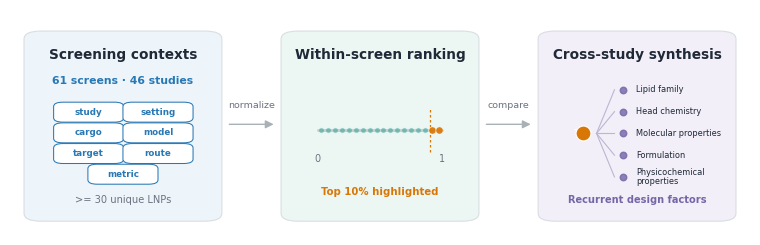

In [ ]:
# ============================================================
# Cell 8 — Fig. 3a: Compact cross-study framework
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch


# ------------------------------------------------------------
# Summary values from the real analysis
# ------------------------------------------------------------

n_screens = screen_lnp_table["screen_id"].nunique()
n_studies = screen_lnp_table["study_id"].nunique()
n_top10 = int(screen_lnp_table["top10_flag"].sum())


# ------------------------------------------------------------
# Colors
# ------------------------------------------------------------

INK = "#1F2937"
MUTED = "#6B7280"

BLUE = "#2878B5"
GREEN = "#2A9D8F"
ORANGE = "#D97706"
PURPLE = "#7566A8"

LIGHT_BLUE = "#EDF5FA"
LIGHT_GREEN = "#ECF7F4"
LIGHT_PURPLE = "#F2EFF8"

BORDER = "#D9DEE3"
GRID = "#E5E7EB"


# ------------------------------------------------------------
# Canvas
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7.4, 2.25))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Tight printed margins
ax.set_xlim(0.025, 0.975)
ax.set_ylim(0.205, 0.825)
ax.axis("off")


# ============================================================
# Helper functions
# ============================================================

def box(x, y, w, h, facecolor):
    p = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.012,rounding_size=0.022",
        facecolor=facecolor,
        edgecolor=BORDER,
        linewidth=0.8,
    )
    ax.add_patch(p)


def chip(x, y, w, h, label, color):
    p = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.006,rounding_size=0.012",
        facecolor="white",
        edgecolor=color,
        linewidth=0.75,
    )
    ax.add_patch(p)

    ax.text(
        x + w / 2,
        y + h / 2,
        label,
        fontsize=6.35,
        color=color,
        fontweight="bold",
        ha="center",
        va="center",
    )


def arrow(x1, x2, y=0.51):
    a = FancyArrowPatch(
        (x1, y),
        (x2, y),
        arrowstyle="-|>",
        mutation_scale=12,
        linewidth=1.0,
        color="#A9B1B8",
    )
    ax.add_patch(a)


# ============================================================
# Geometry
# ============================================================

y0 = 0.255
h = 0.50

x1 = 0.055
w1 = 0.23

x2 = 0.385
w2 = 0.23

x3 = 0.715
w3 = 0.23


# ============================================================
# 1. SCREENING CONTEXTS
# ============================================================

box(x1, y0, w1, h, LIGHT_BLUE)

ax.text(
    x1 + w1 / 2,
    0.690,
    "Screening contexts",
    fontsize=9.8,
    fontweight="bold",
    color=INK,
    ha="center",
)

ax.text(
    x1 + w1 / 2,
    0.620,
    f"{n_screens} screens · {n_studies} studies",
    fontsize=7.8,
    color=BLUE,
    fontweight="bold",
    ha="center",
)


# Context-field chips, no cryptic letters
chip_w = 0.078
chip_h = 0.043

chip_rows = [
    (x1 + 0.032, 0.522, "study"),
    (x1 + 0.121, 0.522, "setting"),
    (x1 + 0.032, 0.465, "cargo"),
    (x1 + 0.121, 0.465, "model"),
    (x1 + 0.032, 0.408, "target"),
    (x1 + 0.121, 0.408, "route"),
    (x1 + 0.076, 0.351, "metric"),
]

for xx, yy, label in chip_rows:
    chip(xx, yy, chip_w, chip_h, label, BLUE)


ax.text(
    x1 + w1 / 2,
    0.292,
    f">= {MIN_SCREEN_SIZE} unique LNPs",
    fontsize=7.1,
    color=MUTED,
    ha="center",
)


# ============================================================
# Arrow 1
# ============================================================

arrow(x1 + w1 + 0.018, x2 - 0.018)

ax.text(
    0.335,
    0.555,
    "normalize",
    fontsize=6.8,
    color=MUTED,
    ha="center",
)


# ============================================================
# 2. WITHIN-SCREEN RANKING
# ============================================================

box(x2, y0, w2, h, LIGHT_GREEN)

ax.text(
    x2 + w2 / 2,
    0.690,
    "Within-screen ranking",
    fontsize=9.8,
    fontweight="bold",
    color=INK,
    ha="center",
)


# Percentile axis, visually centered
axis_x0 = x2 + 0.035
axis_x1 = x2 + w2 - 0.035
axis_y = 0.495

ax.plot(
    [axis_x0, axis_x1],
    [axis_y, axis_y],
    color="#BFC8CC",
    lw=2,
    solid_capstyle="round",
)


pts = np.linspace(0.03, 0.97, 18)

for p in pts:
    col = ORANGE if p >= 0.90 else GREEN
    size = 27 if p >= 0.90 else 15

    ax.scatter(
        axis_x0 + p * (axis_x1 - axis_x0),
        axis_y,
        s=size,
        color=col,
        alpha=0.92 if p >= 0.90 else 0.48,
        edgecolor="white",
        linewidth=0.35,
        zorder=3,
    )


threshold_x = axis_x0 + 0.90 * (axis_x1 - axis_x0)

ax.plot(
    [threshold_x, threshold_x],
    [axis_y - 0.060, axis_y + 0.060],
    linestyle=(0, (2, 2)),
    color=ORANGE,
    lw=0.9,
)

ax.text(axis_x0, 0.405, "0", fontsize=6.9, color=MUTED, ha="center")
ax.text(axis_x1, 0.405, "1", fontsize=6.9, color=MUTED, ha="center")

ax.text(
    x2 + w2 / 2,
    0.315,
    "Top 10% highlighted",
    fontsize=7.3,
    color=ORANGE,
    fontweight="bold",
    ha="center",
)


# ============================================================
# Arrow 2
# ============================================================

arrow(x2 + w2 + 0.018, x3 - 0.018)

ax.text(
    0.665,
    0.555,
    "compare",
    fontsize=6.8,
    color=MUTED,
    ha="center",
)


# ============================================================
# 3. CROSS-STUDY SYNTHESIS
# ============================================================

box(x3, y0, w3, h, LIGHT_PURPLE)

ax.text(
    x3 + w3 / 2,
    0.690,
    "Cross-study synthesis",
    fontsize=9.8,
    fontweight="bold",
    color=INK,
    ha="center",
)


# central top performer node, shifted left
top_x = x3 + 0.045
top_y = 0.485

ax.scatter(
    top_x,
    top_y,
    s=115,
    color=ORANGE,
    edgecolor="white",
    linewidth=0.8,
    zorder=4,
)

ax.text(
    top_x,
    top_y,
    "TOP",
    fontsize=5.7,
    fontweight="bold",
    color="white",
    ha="center",
    va="center",
)


# Compact, better-spaced synthesis branches
factor_y = [0.605, 0.545, 0.485, 0.425, 0.365]

factors = [
    "Lipid family",
    "Head chemistry",
    "Molecular properties",
    "Formulation",
"Physicochemical\nproperties",
    ]

for yy, label in zip(factor_y, factors):
    ax.plot(
        [top_x + 0.018, x3 + 0.086],
        [top_y, yy],
        color="#BDB6D2",
        lw=0.8,
    )

    ax.scatter(
        x3 + 0.097,
        yy,
        s=22,
        color=PURPLE,
        alpha=0.82,
    )

    ax.text(
        x3 + 0.114,
        yy,
        label,
        fontsize=5.95,
        color=INK,
        ha="left",
        va="center",
            linespacing=0.88,

    )


ax.text(
    x3 + w3 / 2,
    0.292,
    "Recurrent design factors",
    fontsize=7.1,
    color=PURPLE,
    fontweight="bold",
    ha="center",
)


# ============================================================
# Save
# ============================================================

fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

save_figure(
    fig,
    "Fig3a_cross_study_framework",
    DIRS["panels"]
)

plt.show()

# Cell 9 — Fig. 3b: Study x lipid-family enrichment map


source data -> /content/cross_study_analysis/source_data/Fig3b_class_enrichment_source.csv
saved:
  /content/cross_study_analysis/panels/Fig3b_class_enrichment_heatmap.pdf
  /content/cross_study_analysis/panels/Fig3b_class_enrichment_heatmap.svg
  /content/cross_study_analysis/panels/Fig3b_class_enrichment_heatmap.png


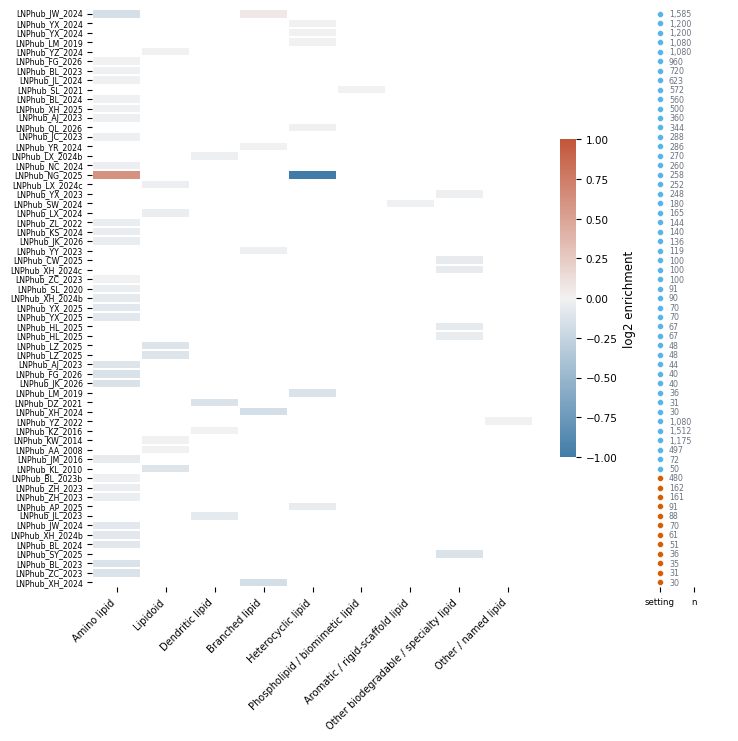

In [ ]:
# ============================================================
# Cell 9 — Fig. 3b: Study x lipid-family enrichment map
# ============================================================

enrich_rows = []

for screen_id, sdf in screen_lnp_table.groupby("screen_id"):
    sdf = sdf.dropna(subset=["il_class_group"]).copy()

    if sdf.empty:
        continue

    n_all = len(sdf)
    top = sdf[sdf["top10_flag"]].copy()
    n_top = len(top)

    if n_top == 0:
        continue

    for group in GROUP_COLORS:
        n_class = int((sdf["il_class_group"] == group).sum())

        if n_class < MIN_CLASS_SUPPORT_PER_SCREEN:
            continue

        n_top_class = int((top["il_class_group"] == group).sum())

        p_top = (n_top_class + 0.5) / (n_top + 1.0)
        p_all = (n_class + 0.5) / (n_all + 1.0)

        enrich_rows.append({
            "screen_id": screen_id,
            "study_id": sdf["study_id"].iloc[0],
            "experimental_setting": sdf["experimental_setting"].iloc[0],
            "cargo_type": sdf["cargo_type"].iloc[0],
            "biological_model": sdf["biological_model"].iloc[0],
            "n_formulations": n_all,
            "n_top": n_top,
            "il_class_group": group,
            "n_class": n_class,
            "n_top_class": n_top_class,
            "log2_enrichment": float(np.log2(p_top / p_all)),
        })


class_enrichment = pd.DataFrame(enrich_rows)
save_source(class_enrichment, "Fig3b_class_enrichment_source")


screen_order = (
    eligible_screen_sizes.set_index("screen_id")
    .loc[sorted(class_enrichment["screen_id"].unique())]
    .sort_values(
        ["experimental_setting", "cargo_type", "unique_lnps"],
        ascending=[True, True, False]
    )
    .index
    .tolist()
)

col_order = [
    c for c in GROUP_COLORS
    if c in class_enrichment["il_class_group"].unique()
]

matrix = (
    class_enrichment
    .pivot(
        index="screen_id",
        columns="il_class_group",
        values="log2_enrichment"
    )
    .reindex(index=screen_order, columns=col_order)
)


fig = plt.figure(figsize=(7.4, max(4.8, 0.105 * len(matrix) + 1.25)))

gs = gridspec.GridSpec(
    1,
    2,
    width_ratios=[8.6, 1.2],
    wspace=0.03
)

ax = fig.add_subplot(gs[0, 0])

# Remove this if you do not want panel label b.
#add_panel_label(ax, "b", x=-0.11, y=1.015)


vmax = (
    np.nanpercentile(np.abs(matrix.values), 97)
    if np.isfinite(matrix.values).any()
    else 1
)

vmax = max(1, float(vmax))


sns.heatmap(
    matrix,
    ax=ax,
    cmap=sns.diverging_palette(240, 20, as_cmap=True),
    center=0,
    vmin=-vmax,
    vmax=vmax,
    linewidths=0.18,
    linecolor="white",
    cbar_kws={
        "label": "log2 enrichment",
        "shrink": 0.55,
    },
)


ax.set_xlabel("")
ax.set_ylabel("")

ax.set_xticklabels(
    [clean_label(c) for c in matrix.columns],
    rotation=45,
    ha="right",
    fontsize=7.1
)

# Full study IDs are retained here.
ax.set_yticks(np.arange(len(matrix.index)) + 0.5)
ax.set_yticklabels(
    [s.split(" | ")[0] for s in matrix.index],
    fontsize=5.6
)


ax_side = fig.add_subplot(gs[0, 1], sharey=ax)

side = (
    eligible_screen_sizes
    .set_index("screen_id")
    .reindex(matrix.index)
)

setting_colors = {
    "in_vitro": "#56B4E9",
    "in_vivo": "#D55E00",
    "ex_vivo": "#009E73",
    "Not reported": "#9CA3AF",
}


for i, (_, row) in enumerate(side.iterrows()):
    y0 = i + 0.5

    ax_side.scatter(
        0.1,
        y0,
        s=18,
        color=setting_colors.get(row["experimental_setting"], "#9CA3AF"),
        edgecolor="white",
        linewidth=0.3
    )

    ax_side.text(
        0.22,
        y0,
        f"{int(row['unique_lnps']):,}",
        va="center",
        ha="left",
        fontsize=5.7,
        color=COLORS["muted"]
    )


ax_side.set_xlim(0, 1)

ax_side.set_xticks([0.1, 0.55])
ax_side.set_xticklabels(
    ["setting", "n"],
    fontsize=6.2,
    rotation=0
)

ax_side.tick_params(
    axis="y",
    left=False,
    labelleft=False
)

for spine in ax_side.spines.values():
    spine.set_visible(False)


fig.subplots_adjust(
    left=0.12,
    right=0.98,
    top=0.985,
    bottom=0.23
)

save_figure(
    fig,
    "Fig3b_class_enrichment_heatmap",
    DIRS["panels"]
)

plt.show()

Unique IL SMILES: 13,988
RDKit parsed: 13,988
RDKit failed: 0
RDKit parsed (%): 100.00%
No invalid IL SMILES detected.
Existing descriptor consistency check: conflicts detected before median aggregation.


,il_smiles,descriptor,n_records,n_unique_values,min_value,max_value,example_values
3,CCCCC/C=C\CCC(=O)OC(C/C=C\CCCCCCCCOC(=O)CCN(CC...,heavy_atoms,19,2,78.0000,80.0000,78; 80
4,CCCCCCCC/C=C\CCCCCCCC(=O)OC(C/C=C\CCCCCCCCOC(=...,heavy_atoms,25,2,95.0000,97.0000,95; 97
7,CCCCC/C=C\CCC(=O)OC(C/C=C\CCCCCCCCOC(=O)CCN(CC...,logp,19,2,18.4486,18.7378,18.4486; 18.7378
8,CCCCCCCC/C=C\CCCCCCCC(=O)OC(C/C=C\CCCCCCCCOC(=...,logp,25,2,25.0803,25.3695,25.0803; 25.3695
9,CCCCCCCCC(CCCCCC)C(=O)OCCCCCC(NC(CC1CCCCC1)C(=...,logp,41,2,15.4386,15.4386,15.4386; 15.4386
0,CCCCC/C=C\CCC(=O)OC(C/C=C\CCCCCCCCOC(=O)CCN(CC...,molecular_weight,19,2,1097.7460,1127.8160,1097.746; 1127.816
1,CCCCCCCC/C=C\CCCCCCCC(=O)OC(C/C=C\CCCCCCCCOC(=...,molecular_weight,25,2,1336.2050,1366.2750,1336.205; 1366.275
2,CCCCCCCCC(CCCCCC)C(=O)OCCCCCC(NC(CC1CCCCC1)C(=...,molecular_weight,41,2,1300.0040,1300.0040,1300.004; 1300.004
5,CCCCC/C=C\CCC(=O)OC(C/C=C\CCCCCCCCOC(=O)CCN(CC...,topological_polar_surface_area,19,2,105.2000,111.6800,105.2; 111.68
6,CCCCCCCC/C=C\CCCCCCCC(=O)OC(C/C=C\CCCCCCCCOC(=...,topological_polar_surface_area,25,2,105.2000,111.6800,105.2; 111.68


source data -> /content/cross_study_analysis/source_data/existing_descriptor_conflicts.csv
source data -> /content/cross_study_analysis/source_data/extra_descriptor_qc.csv

Extra descriptor QC


,descriptor,non_missing,percent_non_missing,n_unique,min,median,max,near_zero_variance
30,aliphatic_heterocycles,13988,100.000000,7,0.000000,0.000000,6.000000,False
25,aliphatic_rings,13988,100.000000,7,0.000000,0.000000,6.000000,False
32,amide_bonds,13988,100.000000,9,0.000000,0.000000,9.000000,False
29,aromatic_heterocycles,13988,100.000000,3,0.000000,0.000000,2.000000,False
27,aromatic_rings_rdkit,13988,100.000000,7,0.000000,0.000000,6.000000,False
16,balaban_j,13988,100.000000,12434,0.751019,3.138122,9.953811,False
15,bertz_complexity,13988,100.000000,11551,137.249221,866.222713,6157.438596,False
0,carbon_count,13988,100.000000,181,10.000000,44.000000,248.000000,False
8,carbon_fraction,13988,100.000000,1112,0.555556,0.846154,0.976744,False
18,chi0,13988,100.000000,5227,10.648418,38.106144,203.578906,False


Near-zero-variance descriptors excluded from meta-analysis: ['positive_formal_charge_count']
Merge QC passed
source data -> /content/cross_study_analysis/source_data/unique_il_descriptors.csv

Molecular descriptors used in extended meta-analysis:
 - heavy_atoms
 - rings
 - aromatic_rings
 - rotatable_bonds
 - van_der_waals_molecular_volume
 - topological_polar_surface_area
 - hydrogen_bond_donors
 - hydrogen_bond_acceptors
 - logp
 - molar_refractivity
 - fraction_sp3_carbons
 - sp3_carbons
 - nitrogen_count
 - molecular_weight
 - carbon_count
 - oxygen_count
 - nitrogen_count_rdkit
 - sulfur_count
 - phosphorus_count
 - halogen_count
 - heteroatom_count
 - heteroatom_fraction
 - carbon_fraction
 - oxygen_fraction
 - nitrogen_fraction
 - nitrogen_to_oxygen_ratio
 - heteroatom_to_carbon_ratio
 - exact_molecular_weight
 - labute_asa
 - tpsa_per_mw
 - tpsa_per_heavy_atom
 - logp_per_100_mw
 - bertz_complexity
 - balaban_j
 - hall_kier_alpha
 - chi0
 - chi1
 - chi0n
 - chi1n
 - kappa1
 - k

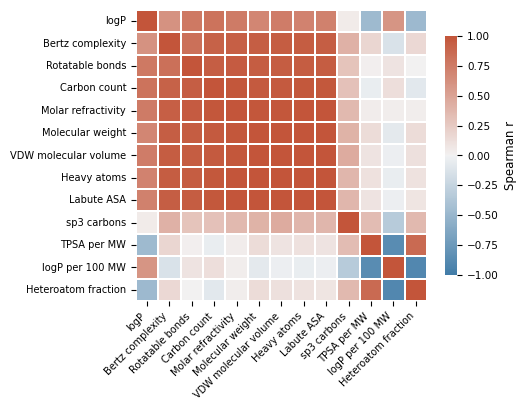


Main Fig. 3c descriptor-selection table


,descriptor,effect,CI,FDR,significant,studies,screens,retained_main,reason
34,H-bond acceptors,0.103,0.050 to 0.155,<0.001,True,42,53,True,Requested main-panel descriptor: H-bond accept...
21,H-bond donors,0.026,-0.030 to 0.081,0.417,False,39,51,True,Requested main-panel descriptor: H-bond donors.
20,Aliphatic heterocycles,0.020,-0.021 to 0.061,0.393,False,37,46,True,Requested main-panel descriptor: aliphatic het...
4,Aromatic heterocycles,-0.063,-0.104 to -0.022,0.005,True,17,23,True,Requested main-panel descriptor: aromatic hete...
12,Aromatic rings,-0.026,-0.076 to 0.025,0.388,False,25,33,True,Requested main-panel descriptor: aromatic rings.
29,Double bonds,0.091,0.042 to 0.140,<0.001,True,41,53,True,Requested main-panel descriptor: double bonds.
7,Heteroatom fraction,-0.061,-0.104 to -0.017,0.010,True,42,54,True,Requested main-panel descriptor: heteroatom fr...
25,Carbon fraction,0.061,0.017 to 0.104,0.010,True,42,54,True,Requested main-panel descriptor: carbon fraction.
10,N:O ratio,-0.029,-0.067 to 0.008,0.173,False,42,54,True,Requested main-panel descriptor: N:O ratio.
51,Rotatable bonds,0.145,0.100 to 0.190,<0.001,True,42,54,True,Requested main-panel descriptor: rotatable bonds.


source data -> /content/cross_study_analysis/source_data/Fig3c_descriptor_meta_analysis_main_selection.csv
source data -> /content/cross_study_analysis/source_data/Fig3c_descriptor_meta_analysis_main_source.csv
saved:
  /content/cross_study_analysis/panels/Fig3c_descriptor_meta_analysis_main.pdf
  /content/cross_study_analysis/panels/Fig3c_descriptor_meta_analysis_main.svg
  /content/cross_study_analysis/panels/Fig3c_descriptor_meta_analysis_main.png


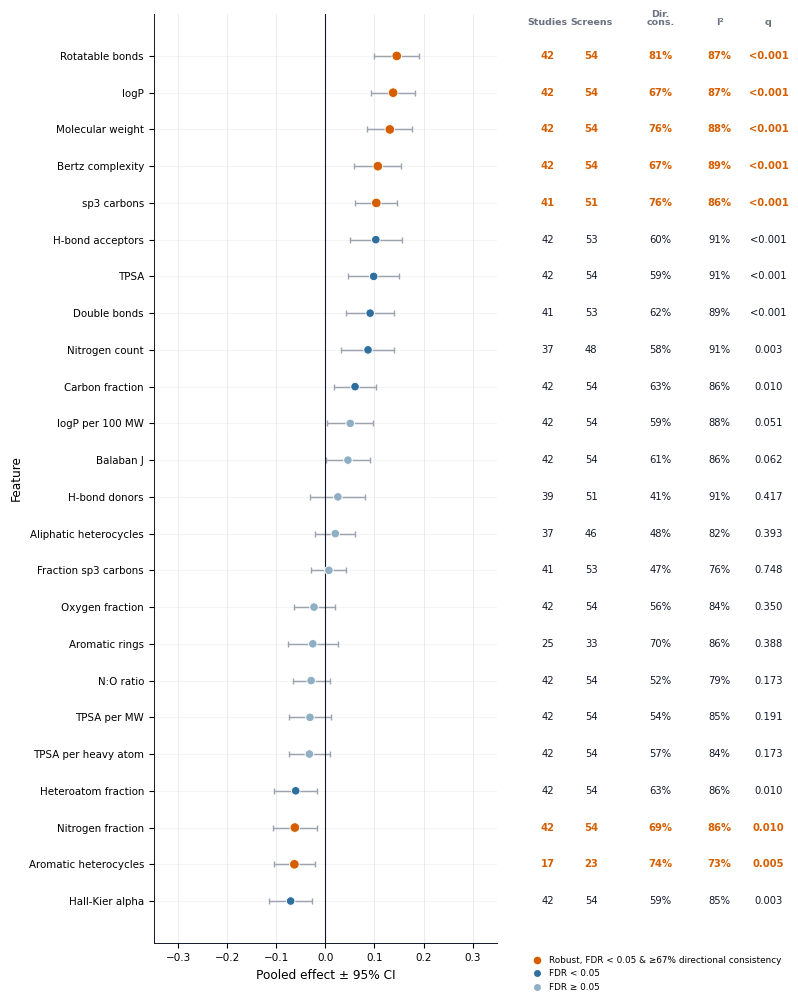

saved:
  /content/cross_study_analysis/panels/Fig3c_extended_descriptor_meta_analysis.pdf
  /content/cross_study_analysis/panels/Fig3c_extended_descriptor_meta_analysis.svg
  /content/cross_study_analysis/panels/Fig3c_extended_descriptor_meta_analysis.png


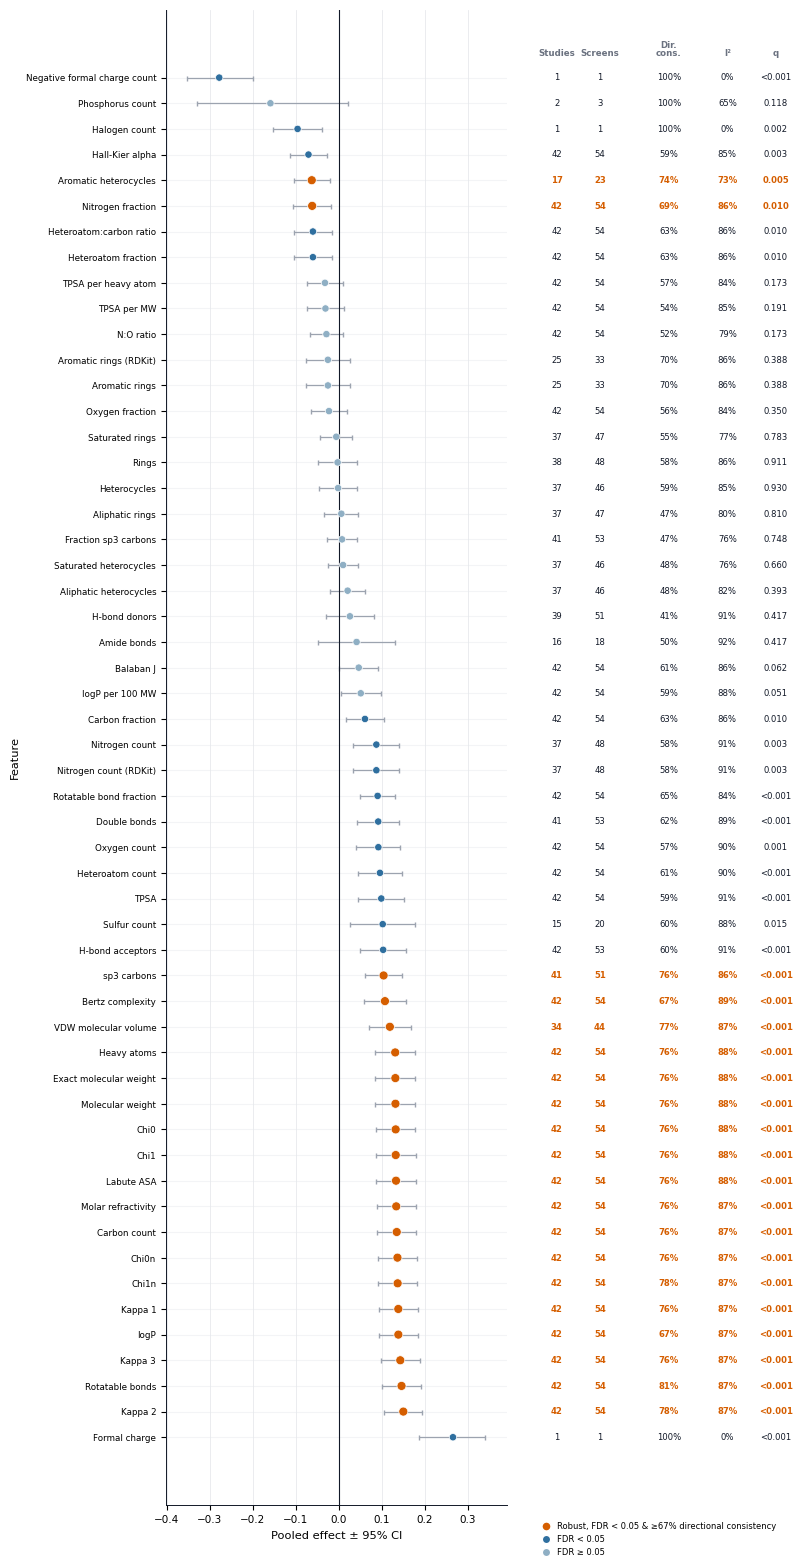

saved:
  /content/cross_study_analysis/supplementary_figures/Supplementary_full_descriptor_meta_analysis.pdf
  /content/cross_study_analysis/supplementary_figures/Supplementary_full_descriptor_meta_analysis.svg
  /content/cross_study_analysis/supplementary_figures/Supplementary_full_descriptor_meta_analysis.png


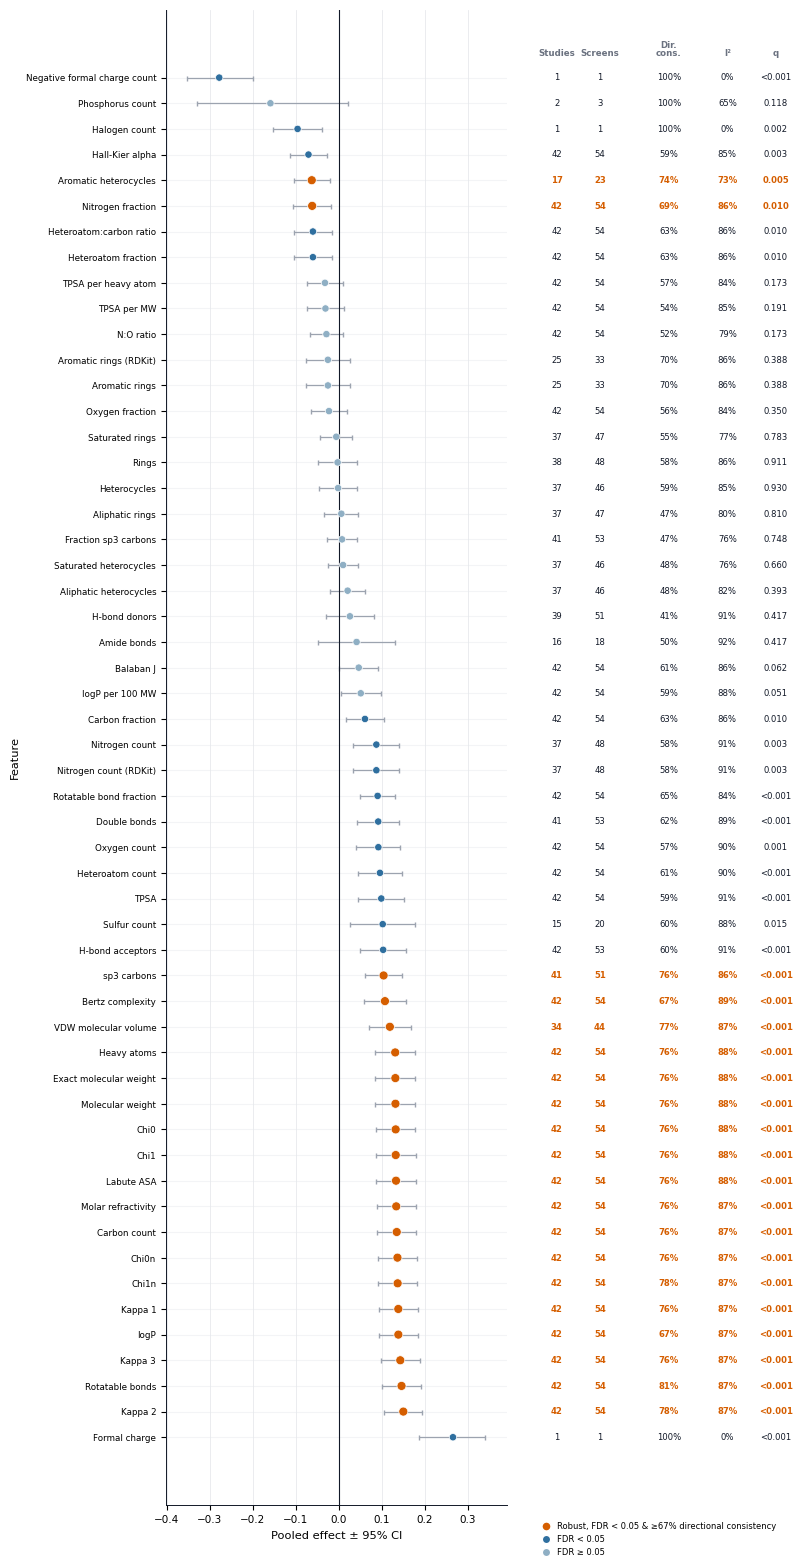

source data -> /content/cross_study_analysis/source_data/Fig3d_extended_descriptor_consistency_matrix_source.csv
source data -> /content/cross_study_analysis/source_data/descriptor_family_summary.csv

EXTENDED MOLECULAR DESCRIPTOR ANALYSIS
Unique IL structures: 13,988
Parsed successfully: 13,988
Failed parsing: 0
Total descriptors analyzed: 54
Final robustness rule: n_screens >= 5 AND n_studies >= 5 AND q_value < 0.05 AND directional_consistency >= 0.67
Passing final robustness rule: 20

ROBUST POSITIVE ASSOCIATIONS
Kappa 2 | effect=0.150 | CI=0.105 to 0.193 | screens=54 | studies=42 | consistency=78% | I2=87% | q=<0.001
Rotatable bonds | effect=0.145 | CI=0.100 to 0.190 | screens=54 | studies=42 | consistency=81% | I2=87% | q=<0.001
Kappa 3 | effect=0.143 | CI=0.097 to 0.187 | screens=54 | studies=42 | consistency=76% | I2=87% | q=<0.001
logP | effect=0.138 | CI=0.093 to 0.183 | screens=54 | studies=42 | consistency=67% | I2=87% | q=<0.001
Kappa 1 | effect=0.138 | CI=0.092 to 0.183 | 

In [ ]:
# ============================================================
# Cell 11 — Extended molecular descriptor analysis
# Everything in this cell is calculated from il_smiles, merged
# back into screen_lnp_table, QC-checked, meta-analyzed, and plotted.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from rdkit import Chem
from rdkit.Chem import Descriptors, GraphDescriptors, rdMolDescriptors, Crippen
from rdkit.Chem.rdchem import BondType, HybridizationType


# ------------------------------------------------------------
# PART 1 — Rerun safety and pre-merge QC state
# ------------------------------------------------------------

CELL11_NEW_DESCRIPTOR_BASE_COLS = [
    "negative_formal_charge_count",
    "phosphorus_count",
    "halogen_count",
    "hall_kier_alpha",
    "aromatic_heterocycles",
    "nitrogen_fraction",
    "heteroatom_to_carbon_ratio",
    "heteroatom_fraction",
    "tpsa_per_heavy_atom",
    "tpsa_per_mw",
    "nitrogen_to_oxygen_ratio",
    "aromatic_rings_rdkit",
    "aromatic_rings",
    "oxygen_fraction",
    "saturated_rings",
    "rings",
    "heterocycles",
    "aliphatic_rings",
    "fraction_sp3_carbons",
    "saturated_heterocycles",
    "aliphatic_heterocycles",
    "hydrogen_bond_donors",
    "amide_bonds",
    "balaban_j",
    "logp_per_100_mw",
    "carbon_fraction",
    "nitrogen_count",
    "nitrogen_count_rdkit",
    "rotatable_bond_fraction",
    "double_bond_count",
    "oxygen_count",
    "heteroatom_count",
    "topological_polar_surface_area",
    "sulfur_count",
    "hydrogen_bond_acceptors",
    "sp3_carbons",
    "bertz_complexity",
    "van_der_waals_molecular_volume",
    "heavy_atoms",
    "exact_molecular_weight",
    "molecular_weight",
    "chi0",
    "chi1",
    "labute_asa",
    "molar_refractivity",
    "carbon_count",
    "chi0n",
    "chi1n",
    "kappa1",
    "logp",
    "kappa3",
    "rotatable_bonds",
    "kappa2",
    "formal_charge",
    "positive_formal_charge_count",
]

CELL11_GENERATED_CANDIDATES = (
    ["rdkit_valid", "rdkit_valid_extra_rdkit"]
    + CELL11_NEW_DESCRIPTOR_BASE_COLS
    + [f"{c}_extra_rdkit" for c in CELL11_NEW_DESCRIPTOR_BASE_COLS]
)

_cell11_generated_present = [
    c for c in CELL11_GENERATED_CANDIDATES
    if c in screen_lnp_table.columns
]
if _cell11_generated_present:
    screen_lnp_table = screen_lnp_table.drop(columns=_cell11_generated_present)
    print("Removed existing descriptor columns before RDKit recomputation:", ", ".join(_cell11_generated_present))

_screen_lnp_pre = screen_lnp_table.copy(deep=True)
_pre_qc = {
    "row_count": len(_screen_lnp_pre),
    "screen_lnp_pairs": _screen_lnp_pre[["screen_id", "lnp_id"]].astype(str).agg("||".join, axis=1).copy(),
    "delivery": _screen_lnp_pre["delivery"].copy(),
    "delivery_rank": _screen_lnp_pre["delivery_rank"].copy(),
    "delivery_percentile": _screen_lnp_pre["delivery_percentile"].copy(),
    "top10_flag": _screen_lnp_pre["top10_flag"].copy(),
    "screen_id": _screen_lnp_pre["screen_id"].copy(),
    "lnp_id": _screen_lnp_pre["lnp_id"].copy(),
}

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def _safe_divide(num, den):
    num = float(num) if pd.notna(num) else np.nan
    den = float(den) if pd.notna(den) else np.nan
    if not np.isfinite(num) or not np.isfinite(den) or den == 0:
        return np.nan
    return num / den


def _safe_descriptor(func, mol):
    try:
        val = func(mol)
        return float(val) if val is not None else np.nan
    except Exception:
        return np.nan


def _count_atoms(mol, atomic_num):
    return int(sum(1 for atom in mol.GetAtoms() if atom.GetAtomicNum() == atomic_num))


def _count_halogen_atoms(mol):
    halogens = {9, 17, 35, 53, 85}
    return int(sum(1 for atom in mol.GetAtoms() if atom.GetAtomicNum() in halogens))


def _format_q(q):
    if pd.isna(q):
        return "NA"
    return "<0.001" if q < 0.001 else f"{q:.3f}"


def _pretty_extended_feature_name(feature):
    mapping = {
        "negative_formal_charge_count": "Negative formal charge count",
        "positive_formal_charge_count": "Positive formal charge count",
        "phosphorus_count": "Phosphorus count",
        "halogen_count": "Halogen count",
        "hall_kier_alpha": "Hall-Kier alpha",
        "aromatic_heterocycles": "Aromatic heterocycles",
        "nitrogen_fraction": "Nitrogen fraction",
        "heteroatom_to_carbon_ratio": "Heteroatom:carbon ratio",
        "heteroatom_fraction": "Heteroatom fraction",
        "tpsa_per_heavy_atom": "TPSA per heavy atom",
        "tpsa_per_mw": "TPSA per MW",
        "nitrogen_to_oxygen_ratio": "N:O ratio",
        "aromatic_rings_rdkit": "Aromatic rings (RDKit)",
        "aromatic_rings": "Aromatic rings",
        "oxygen_fraction": "Oxygen fraction",
        "saturated_rings": "Saturated rings",
        "rings": "Rings",
        "heterocycles": "Heterocycles",
        "aliphatic_rings": "Aliphatic rings",
        "fraction_sp3_carbons": "Fraction sp3 carbons",
        "saturated_heterocycles": "Saturated heterocycles",
        "aliphatic_heterocycles": "Aliphatic heterocycles",
        "hydrogen_bond_donors": "H-bond donors",
        "amide_bonds": "Amide bonds",
        "balaban_j": "Balaban J",
        "logp_per_100_mw": "logP per 100 MW",
        "carbon_fraction": "Carbon fraction",
        "nitrogen_count": "Nitrogen count",
        "nitrogen_count_rdkit": "Nitrogen count (RDKit)",
        "rotatable_bond_fraction": "Rotatable bond fraction",
        "double_bond_count": "Double bonds",
        "oxygen_count": "Oxygen count",
        "heteroatom_count": "Heteroatom count",
        "topological_polar_surface_area": "TPSA",
        "sulfur_count": "Sulfur count",
        "hydrogen_bond_acceptors": "H-bond acceptors",
        "sp3_carbons": "sp3 carbons",
        "bertz_complexity": "Bertz complexity",
        "van_der_waals_molecular_volume": "VDW molecular volume",
        "heavy_atoms": "Heavy atoms",
        "exact_molecular_weight": "Exact molecular weight",
        "molecular_weight": "Molecular weight",
        "chi0": "Chi0",
        "chi1": "Chi1",
        "labute_asa": "Labute ASA",
        "molar_refractivity": "Molar refractivity",
        "carbon_count": "Carbon count",
        "chi0n": "Chi0n",
        "chi1n": "Chi1n",
        "kappa1": "Kappa 1",
        "logp": "logP",
        "kappa3": "Kappa 3",
        "rotatable_bonds": "Rotatable bonds",
        "kappa2": "Kappa 2",
        "formal_charge": "Formal charge",
    }
    if "pretty_feature_name" in globals():
        return mapping.get(feature, pretty_feature_name(feature))
    return mapping.get(feature, str(feature).replace("_", " "))


def _descriptor_family(feature):
    family_map = {
        "heavy_atoms": "Size / bulk",
        "molecular_weight": "Size / bulk",
        "exact_molecular_weight": "Size / bulk",
        "van_der_waals_molecular_volume": "Size / bulk",
        "molar_refractivity": "Size / bulk",
        "labute_asa": "Size / bulk",
        "carbon_count": "Elemental composition",
        "oxygen_count": "Elemental composition",
        "nitrogen_count": "Elemental composition",
        "nitrogen_count_rdkit": "Elemental composition",
        "sulfur_count": "Elemental composition",
        "phosphorus_count": "Elemental composition",
        "halogen_count": "Elemental composition",
        "heteroatom_count": "Elemental composition",
        "carbon_fraction": "Elemental composition",
        "oxygen_fraction": "Elemental composition",
        "nitrogen_fraction": "Elemental composition",
        "heteroatom_fraction": "Elemental composition",
        "nitrogen_to_oxygen_ratio": "Elemental composition",
        "heteroatom_to_carbon_ratio": "Elemental composition",
        "logp": "Hydrophobicity",
        "logp_per_100_mw": "Hydrophobicity",
        "topological_polar_surface_area": "Polarity",
        "hydrogen_bond_donors": "Polarity",
        "hydrogen_bond_acceptors": "Polarity",
        "tpsa_per_mw": "Polarity",
        "tpsa_per_heavy_atom": "Polarity",
        "rotatable_bonds": "Flexibility",
        "rotatable_bond_fraction": "Flexibility",
        "sp3_carbons": "Flexibility",
        "fraction_sp3_carbons": "Flexibility",
        "amide_bonds": "Bonding / flexibility",
        "double_bond_count": "Bonding / flexibility",
        "bertz_complexity": "Topology / complexity",
        "balaban_j": "Topology / complexity",
        "hall_kier_alpha": "Topology / complexity",
        "chi0": "Topology / complexity",
        "chi1": "Topology / complexity",
        "chi0n": "Topology / complexity",
        "chi1n": "Topology / complexity",
        "kappa1": "Molecular shape",
        "kappa2": "Molecular shape",
        "kappa3": "Molecular shape",
        "rings": "Ring chemistry",
        "aromatic_rings": "Ring chemistry",
        "aliphatic_rings": "Ring chemistry",
        "saturated_rings": "Ring chemistry",
        "aromatic_rings_rdkit": "Ring chemistry",
        "heterocycles": "Ring chemistry",
        "aromatic_heterocycles": "Ring chemistry",
        "aliphatic_heterocycles": "Ring chemistry",
        "saturated_heterocycles": "Ring chemistry",
        "formal_charge": "Charge",
        "positive_formal_charge_count": "Charge",
        "negative_formal_charge_count": "Charge",
    }
    return family_map.get(feature, "Other")


def _calc_vdw_molecular_volume(mol):
    # Fast approximate van der Waals molecular volume from atomic radii.
    # This is much faster than 3D conformer embedding/optimization and is stable across reruns.
    vdw_radii = {
        1: 1.20,
        6: 1.70,
        7: 1.55,
        8: 1.52,
        9: 1.47,
        15: 1.80,
        16: 1.80,
        17: 1.75,
        35: 1.85,
        53: 1.98,
    }

    try:
        mol_h = Chem.AddHs(mol)
        return float(sum(
            (4.0 / 3.0) * np.pi * (vdw_radii.get(atom.GetAtomicNum(), 1.70) ** 3)
            for atom in mol_h.GetAtoms()
        ))
    except Exception:
        return np.nan




def _calc_il_descriptors(smi):
    row = {"il_smiles": smi}
    mol = Chem.MolFromSmiles(str(smi)) if pd.notna(smi) else None
    row["rdkit_valid"] = mol is not None
    if mol is None:
        return row

    heavy = int(mol.GetNumHeavyAtoms())
    carbon = _count_atoms(mol, 6)
    oxygen = _count_atoms(mol, 8)
    nitrogen = _count_atoms(mol, 7)
    sulfur = _count_atoms(mol, 16)
    phosphorus = _count_atoms(mol, 15)
    halogens = _count_halogen_atoms(mol)
    hetero = int(sum(1 for atom in mol.GetAtoms() if atom.GetAtomicNum() not in {1, 6}))
    formal_charges = [atom.GetFormalCharge() for atom in mol.GetAtoms()]

    molecular_weight = _safe_descriptor(Descriptors.MolWt, mol)
    exact_molecular_weight = _safe_descriptor(Descriptors.ExactMolWt, mol)
    tpsa = _safe_descriptor(rdMolDescriptors.CalcTPSA, mol)
    logp = _safe_descriptor(Crippen.MolLogP, mol)
    rotatable_bonds = _safe_descriptor(rdMolDescriptors.CalcNumRotatableBonds, mol)

    sp3_carbons = int(sum(
        1 for atom in mol.GetAtoms()
        if atom.GetAtomicNum() == 6 and atom.GetHybridization() == HybridizationType.SP3
    ))

    row.update({
        "negative_formal_charge_count": int(sum(1 for charge in formal_charges if charge < 0)),
        "phosphorus_count": phosphorus,
        "halogen_count": halogens,
        "hall_kier_alpha": _safe_descriptor(Descriptors.HallKierAlpha, mol),
        "aromatic_heterocycles": _safe_descriptor(rdMolDescriptors.CalcNumAromaticHeterocycles, mol),
        "nitrogen_fraction": _safe_divide(nitrogen, heavy),
        "heteroatom_to_carbon_ratio": _safe_divide(hetero, carbon),
        "heteroatom_fraction": _safe_divide(hetero, heavy),
        "tpsa_per_heavy_atom": _safe_divide(tpsa, heavy),
        "tpsa_per_mw": _safe_divide(tpsa, molecular_weight),
        "nitrogen_to_oxygen_ratio": _safe_divide(nitrogen, oxygen),
        "aromatic_rings_rdkit": _safe_descriptor(rdMolDescriptors.CalcNumAromaticRings, mol),
        "aromatic_rings": _safe_descriptor(rdMolDescriptors.CalcNumAromaticRings, mol),
        "oxygen_fraction": _safe_divide(oxygen, heavy),
        "saturated_rings": _safe_descriptor(rdMolDescriptors.CalcNumSaturatedRings, mol),
        "rings": _safe_descriptor(rdMolDescriptors.CalcNumRings, mol),
        "heterocycles": _safe_descriptor(rdMolDescriptors.CalcNumHeterocycles, mol),
        "aliphatic_rings": _safe_descriptor(rdMolDescriptors.CalcNumAliphaticRings, mol),
        "fraction_sp3_carbons": _safe_descriptor(rdMolDescriptors.CalcFractionCSP3, mol),
        "saturated_heterocycles": _safe_descriptor(rdMolDescriptors.CalcNumSaturatedHeterocycles, mol),
        "aliphatic_heterocycles": _safe_descriptor(rdMolDescriptors.CalcNumAliphaticHeterocycles, mol),
        "hydrogen_bond_donors": _safe_descriptor(rdMolDescriptors.CalcNumHBD, mol),
        "amide_bonds": _safe_descriptor(rdMolDescriptors.CalcNumAmideBonds, mol),
        "balaban_j": _safe_descriptor(GraphDescriptors.BalabanJ, mol),
        "logp_per_100_mw": _safe_divide(logp, molecular_weight) * 100 if pd.notna(_safe_divide(logp, molecular_weight)) else np.nan,
        "carbon_fraction": _safe_divide(carbon, heavy),
        "nitrogen_count": nitrogen,
        "nitrogen_count_rdkit": nitrogen,
        "rotatable_bond_fraction": _safe_divide(rotatable_bonds, max(heavy - 1, 1)),
        "double_bond_count": int(sum(1 for bond in mol.GetBonds() if bond.GetBondType() == BondType.DOUBLE)),
        "oxygen_count": oxygen,
        "heteroatom_count": hetero,
        "topological_polar_surface_area": tpsa,
        "sulfur_count": sulfur,
        "hydrogen_bond_acceptors": _safe_descriptor(rdMolDescriptors.CalcNumHBA, mol),
        "sp3_carbons": sp3_carbons,
        "bertz_complexity": _safe_descriptor(GraphDescriptors.BertzCT, mol),
        "van_der_waals_molecular_volume": _calc_vdw_molecular_volume(mol),
        "heavy_atoms": heavy,
        "exact_molecular_weight": exact_molecular_weight,
        "molecular_weight": molecular_weight,
        "chi0": _safe_descriptor(GraphDescriptors.Chi0, mol),
        "chi1": _safe_descriptor(GraphDescriptors.Chi1, mol),
        "labute_asa": _safe_descriptor(rdMolDescriptors.CalcLabuteASA, mol),
        "molar_refractivity": _safe_descriptor(Crippen.MolMR, mol),
        "carbon_count": carbon,
        "chi0n": _safe_descriptor(GraphDescriptors.Chi0n, mol),
        "chi1n": _safe_descriptor(GraphDescriptors.Chi1n, mol),
        "kappa1": _safe_descriptor(rdMolDescriptors.CalcKappa1, mol),
        "logp": logp,
        "kappa3": _safe_descriptor(rdMolDescriptors.CalcKappa3, mol),
        "rotatable_bonds": rotatable_bonds,
        "kappa2": _safe_descriptor(rdMolDescriptors.CalcKappa2, mol),
        "formal_charge": int(sum(formal_charges)),
        "positive_formal_charge_count": int(sum(1 for charge in formal_charges if charge > 0)),
    })

    return row

# ------------------------------------------------------------
# PART 2 — Unique ionizable-lipid descriptor table
# ------------------------------------------------------------

unique_smiles = (
    screen_lnp_table.loc[screen_lnp_table["il_smiles"].notna(), "il_smiles"]
    .astype(str)
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

unique_il_descriptors = pd.DataFrame([_calc_il_descriptors(smi) for smi in unique_smiles])

valid_count = int(unique_il_descriptors["rdkit_valid"].sum())
failed_count = int((~unique_il_descriptors["rdkit_valid"]).sum())
parsed_pct = valid_count / len(unique_il_descriptors) * 100 if len(unique_il_descriptors) else np.nan

print("Unique IL SMILES:", f"{len(unique_il_descriptors):,}")
print("RDKit parsed:", f"{valid_count:,}")
print("RDKit failed:", f"{failed_count:,}")
print("RDKit parsed (%):", f"{parsed_pct:.2f}%")

invalid_il_smiles = unique_il_descriptors.loc[~unique_il_descriptors["rdkit_valid"], ["il_smiles"]].copy()
if len(invalid_il_smiles):
    save_source(invalid_il_smiles, "invalid_il_smiles")
else:
    print("No invalid IL SMILES detected.")

# ------------------------------------------------------------
# PART 3 — Descriptor cleanup
# ------------------------------------------------------------

existing_descriptor_conflicts = pd.DataFrame()
save_source(existing_descriptor_conflicts, "existing_descriptor_conflicts")

new_descriptor_base_cols = [
    c for c in unique_il_descriptors.columns
    if c not in ["il_smiles", "rdkit_valid"]
]

unique_il_descriptors[new_descriptor_base_cols] = (
    unique_il_descriptors[new_descriptor_base_cols]
    .replace([np.inf, -np.inf], np.nan)
)

# ------------------------------------------------------------
# PART 4 — Descriptor QC
# ------------------------------------------------------------

qc_rows = []
for descriptor in new_descriptor_base_cols:
    s = pd.to_numeric(unique_il_descriptors[descriptor], errors="coerce").replace([np.inf, -np.inf], np.nan)
    qc_rows.append({
        "descriptor": descriptor,
        "non_missing": int(s.notna().sum()),
        "percent_non_missing": float(s.notna().mean() * 100),
        "n_unique": int(s.nunique(dropna=True)),
        "min": float(s.min()) if s.notna().any() else np.nan,
        "median": float(s.median()) if s.notna().any() else np.nan,
        "max": float(s.max()) if s.notna().any() else np.nan,
        "near_zero_variance": int(s.nunique(dropna=True)) < 3,
    })

extra_descriptor_qc = pd.DataFrame(qc_rows).sort_values(["near_zero_variance", "descriptor"])
save_source(extra_descriptor_qc, "extra_descriptor_qc")

print("\nExtra descriptor QC")
display(extra_descriptor_qc)

near_zero_descriptors = extra_descriptor_qc.loc[extra_descriptor_qc["near_zero_variance"], "descriptor"].tolist()
if near_zero_descriptors:
    print("Near-zero-variance descriptors excluded from meta-analysis:", near_zero_descriptors)

# ------------------------------------------------------------
# PART 5 — Merge into screen_lnp_table with explicit QC
# ------------------------------------------------------------

_merge_cols = ["il_smiles", "rdkit_valid"] + new_descriptor_base_cols
merge_descriptor_table = unique_il_descriptors[_merge_cols].copy()

rename_map = {}
for col in new_descriptor_base_cols + ["rdkit_valid"]:
    if col in screen_lnp_table.columns:
        rename_map[col] = f"{col}_extra_rdkit"

if rename_map:
    merge_descriptor_table = merge_descriptor_table.rename(columns=rename_map)
    new_descriptor_cols = [rename_map.get(c, c) for c in new_descriptor_base_cols]
    rdkit_valid_col = rename_map.get("rdkit_valid", "rdkit_valid")
else:
    new_descriptor_cols = new_descriptor_base_cols.copy()
    rdkit_valid_col = "rdkit_valid"

screen_lnp_table = screen_lnp_table.merge(
    merge_descriptor_table,
    on="il_smiles",
    how="left",
    validate="many_to_one"
)

assert len(screen_lnp_table) == _pre_qc["row_count"], "Row count changed after descriptor merge."
assert screen_lnp_table[["screen_id", "lnp_id"]].astype(str).agg("||".join, axis=1).equals(_pre_qc["screen_lnp_pairs"]), "screen_id x lnp_id identity changed."

pd.testing.assert_series_equal(screen_lnp_table["delivery"], _pre_qc["delivery"], check_names=False)
pd.testing.assert_series_equal(screen_lnp_table["delivery_rank"], _pre_qc["delivery_rank"], check_names=False)
pd.testing.assert_series_equal(screen_lnp_table["delivery_percentile"], _pre_qc["delivery_percentile"], check_names=False)
pd.testing.assert_series_equal(screen_lnp_table["top10_flag"], _pre_qc["top10_flag"], check_names=False)
pd.testing.assert_series_equal(screen_lnp_table["screen_id"], _pre_qc["screen_id"], check_names=False)
pd.testing.assert_series_equal(screen_lnp_table["lnp_id"], _pre_qc["lnp_id"], check_names=False)

assert not any(col.endswith("_x") or col.endswith("_y") for col in screen_lnp_table.columns), "Unexpected _x/_y columns after merge."

print("Merge QC passed")

# ------------------------------------------------------------
# PART 6 — Save unique descriptor table
# ------------------------------------------------------------

save_source(unique_il_descriptors, "unique_il_descriptors")

# ------------------------------------------------------------
# PART 7 — Extended descriptor list
# ------------------------------------------------------------

descriptor_candidates = [rename_map.get(c, c) for c in CELL11_NEW_DESCRIPTOR_BASE_COLS]

coverage_min_screen_lnp_rows = max(50, int(0.01 * len(screen_lnp_table)))

molecular_descriptors_extended = []
for feature in descriptor_candidates:
    if feature not in screen_lnp_table.columns:
        continue
    s = pd.to_numeric(screen_lnp_table[feature], errors="coerce").replace([np.inf, -np.inf], np.nan)
    if s.notna().sum() < coverage_min_screen_lnp_rows:
        continue
    if s.nunique(dropna=True) < 3:
        continue
    molecular_descriptors_extended.append(feature)

print("\nMolecular descriptors used in extended meta-analysis:")
for feature in molecular_descriptors_extended:
    print(" -", _pretty_extended_feature_name(feature), f"({feature})")

# ------------------------------------------------------------
# PART 8 — Rerun cross-study meta-analysis
# ------------------------------------------------------------

descriptor_screen_effects_extended, descriptor_meta_extended = meta_analyze_continuous_effects(
    screen_lnp_table,
    molecular_descriptors_extended,
    flag_col="top10_flag"
)

if descriptor_meta_extended.empty:
    raise RuntimeError("No descriptors were analyzable in the extended descriptor meta-analysis.")

n_studies_map = (
    descriptor_screen_effects_extended.groupby("feature")["study_id"]
    .nunique()
    .rename("n_studies")
)

descriptor_meta_extended = descriptor_meta_extended.merge(
    n_studies_map,
    left_on="feature",
    right_index=True,
    how="left"
)

descriptor_meta_extended["n_studies"] = descriptor_meta_extended["n_studies"].fillna(0).astype(int)

FINAL_MIN_SCREENS = 5
FINAL_MIN_STUDIES = 5

descriptor_meta_extended["passes_support"] = (
    (descriptor_meta_extended["n_screens"] >= FINAL_MIN_SCREENS)
    & (descriptor_meta_extended["n_studies"] >= FINAL_MIN_STUDIES)
)

descriptor_meta_extended["passes_robustness_rule"] = (
    descriptor_meta_extended["passes_support"]
    & (descriptor_meta_extended["q_value"] < 0.05)
    & (descriptor_meta_extended["directional_consistency"] >= 0.665666666666666)
)

summary_cols = [
    "feature", "pooled_effect", "ci_low", "ci_high", "n_screens", "n_studies",
    "directional_consistency", "i2", "tau2", "p_value", "q_value", "passes_robustness_rule"
]

descriptor_meta_extended = descriptor_meta_extended[
    summary_cols + [c for c in descriptor_meta_extended.columns if c not in summary_cols]
]

save_source(descriptor_screen_effects_extended, "Fig3c_extended_descriptor_screen_effects_source")
save_source(descriptor_meta_extended, "Fig3c_extended_descriptor_meta_analysis_source")

descriptor_screen_effects = descriptor_screen_effects_extended.copy()
descriptor_meta = descriptor_meta_extended.copy()
molecular_descriptors = molecular_descriptors_extended.copy()

# ------------------------------------------------------------
# PART 9 — Descriptor correlation analysis, one row per unique il_smiles
# ------------------------------------------------------------

unique_descriptor_analysis = (
    screen_lnp_table.dropna(subset=["il_smiles"])
    .sort_values("il_smiles")
    .drop_duplicates("il_smiles")
    [["il_smiles"] + molecular_descriptors_extended]
    .copy()
)

for feature in molecular_descriptors_extended:
    unique_descriptor_analysis[feature] = pd.to_numeric(
        unique_descriptor_analysis[feature],
        errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

full_descriptor_corr = unique_descriptor_analysis[molecular_descriptors_extended].corr(
    method="spearman",
    min_periods=20
)

save_source(
    full_descriptor_corr.reset_index().rename(columns={"index": "feature"}),
    "extended_descriptor_spearman_correlation_matrix"
)

focused_features_requested = [
    "molecular_weight", "heavy_atoms", "van_der_waals_molecular_volume", "molar_refractivity",
    "carbon_count", "labute_asa", "bertz_complexity", "sp3_carbons", "rotatable_bonds",
    "logp", "tpsa_per_mw", "logp_per_100_mw", "heteroatom_fraction",
]

focused_features = [
    rename_map.get(f, f)
    for f in focused_features_requested
    if rename_map.get(f, f) in unique_descriptor_analysis.columns
]

focused_corr = unique_descriptor_analysis[focused_features].corr(method="spearman", min_periods=20)

save_source(
    focused_corr.reset_index().rename(columns={"index": "feature"}),
    "focused_extended_descriptor_spearman_correlation_matrix"
)

cluster_corr = focused_corr.copy().fillna(0)
if len(cluster_corr) >= 3:
    dist = 1 - np.abs(cluster_corr)
    dist_arr = dist.to_numpy(copy=True)
    np.fill_diagonal(dist_arr, 0)
    linkage = hierarchy.linkage(squareform(dist_arr, checks=False), method="average")
    order = hierarchy.leaves_list(linkage)
    clustered_corr = focused_corr.iloc[order, order]
else:
    clustered_corr = focused_corr

fig_corr, ax_corr = plt.subplots(figsize=(5.6, 5.1))
fig_corr.patch.set_facecolor("white")

sns.heatmap(
    clustered_corr,
    ax=ax_corr,
    cmap=sns.diverging_palette(240, 20, as_cmap=True),
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.35,
    linecolor="white",
    cbar_kws={"label": "Spearman r", "shrink": 0.70},
)

ax_corr.set_xticklabels(
    [_pretty_extended_feature_name(f) for f in clustered_corr.columns],
    rotation=45,
    ha="right",
    fontsize=7.1
)
ax_corr.set_yticklabels(
    [_pretty_extended_feature_name(f) for f in clustered_corr.index],
    rotation=0,
    fontsize=7.1
)
ax_corr.set_xlabel("")
ax_corr.set_ylabel("")
fig_corr.subplots_adjust(left=0.31, right=0.96, top=0.98, bottom=0.31)

save_figure(fig_corr, "Supplementary_descriptor_correlation_heatmap", DIRS["supplementary_figures"])
plt.show()

# ------------------------------------------------------------
# PART 10 — Main-text and complete descriptor forest plots
# ------------------------------------------------------------

plot_meta_extended = descriptor_meta_extended.sort_values("pooled_effect", ascending=True).reset_index(drop=True)
if plot_meta_extended.empty:
    raise RuntimeError("No descriptors available for the extended descriptor forest plot.")

MAIN_MIN_STUDIES = 6
main_candidate_meta = descriptor_meta_extended[
    descriptor_meta_extended["n_studies"] >= MAIN_MIN_STUDIES
].copy()

if main_candidate_meta.empty:
    raise RuntimeError(f"No descriptors have at least {MAIN_MIN_STUDIES} distinct studies for the main panel.")

main_feature_spec = [
    ("molecular_weight", "size", "Requested main-panel descriptor: molecular weight."),
    ("logp", "lipophilicity", "Requested main-panel descriptor: logP."),
    ("topological_polar_surface_area", "polarity", "Requested main-panel descriptor: TPSA."),
    ("hydrogen_bond_acceptors", "H-bonding", "Requested main-panel descriptor: H-bond acceptors."),
    ("rotatable_bonds", "flexibility", "Requested main-panel descriptor: rotatable bonds."),
    ("sp3_carbons", "saturation / 3D character", "Requested main-panel descriptor: sp3 carbons."),
    ("bertz_complexity", "topology / complexity", "Requested main-panel descriptor: Bertz complexity."),
    ("hall_kier_alpha", "topology / shape", "Requested main-panel descriptor: Hall-Kier alpha."),
    ("aromatic_heterocycles", "aromatic heterocycles", "Requested main-panel descriptor: aromatic heterocycles."),
    ("nitrogen_count", "nitrogen / amine content", "Requested main-panel descriptor: nitrogen count."),
    ("nitrogen_fraction", "nitrogen / amine content", "Requested main-panel descriptor: nitrogen fraction."),
    ("heteroatom_fraction", "elemental balance", "Requested main-panel descriptor: heteroatom fraction."),
    ("carbon_fraction", "elemental balance", "Requested main-panel descriptor: carbon fraction."),
    ("double_bond_count", "bond unsaturation", "Requested main-panel descriptor: double bonds."),
    ("logp_per_100_mw", "normalized lipophilicity", "Requested main-panel descriptor: logP per 100 MW."),
    ("balaban_j", "topology", "Requested main-panel descriptor: Balaban J."),
    ("tpsa_per_mw", "normalized polarity", "Requested main-panel descriptor: TPSA per MW."),
    ("aromatic_rings", "aromaticity", "Requested main-panel descriptor: aromatic rings."),
    ("hydrogen_bond_donors", "H-bonding", "Requested main-panel descriptor: H-bond donors."),
    ("fraction_sp3_carbons", "saturation / 3D character", "Requested main-panel descriptor: fraction sp3 carbons."),
    ("tpsa_per_heavy_atom", "normalized polarity", "Requested main-panel descriptor: TPSA per heavy atom."),
    ("nitrogen_to_oxygen_ratio", "elemental balance", "Requested main-panel descriptor: N:O ratio."),
    ("oxygen_fraction", "oxygen content", "Requested main-panel descriptor: oxygen fraction."),
    ("aliphatic_heterocycles", "aliphatic heterocycles", "Requested main-panel descriptor: aliphatic heterocycles."),
]

main_feature_order = [f for f, _, _ in main_feature_spec if f in main_candidate_meta["feature"].values]
main_reason_map = {f: reason for f, _, reason in main_feature_spec if f in main_feature_order}
main_concept_map = {f: concept for f, concept, _ in main_feature_spec if f in main_feature_order}

if len(main_feature_order) < 10:
    already = set(main_feature_order)
    redundant_groups = {
        "size": {"heavy_atoms", "exact_molecular_weight", "van_der_waals_molecular_volume", "molar_refractivity", "labute_asa", "carbon_count"},
        "rings": {"rings", "aromatic_rings_rdkit"},
        "saturation": {"sp3_carbons"},
        "polarity": {"tpsa_per_mw", "tpsa_per_heavy_atom"},
    }
    redundant_pool = set().union(*redundant_groups.values()) if redundant_groups else set()

    sig_pool = main_candidate_meta[
        (main_candidate_meta["q_value"] < 0.05)
        & (~main_candidate_meta["feature"].isin(already | redundant_pool))
    ].sort_values(["q_value", "n_studies", "n_screens"], ascending=[True, False, False])

    for feature in sig_pool["feature"]:
        if len(main_feature_order) >= 14:
            break
        main_feature_order.append(feature)
        already.add(feature)
        main_reason_map[feature] = "Backfilled as a strong non-redundant significant descriptor."
        main_concept_map[feature] = _descriptor_family(feature)

    if len(main_feature_order) < 10:
        nonsig_pool = main_candidate_meta[main_candidate_meta["q_value"] >= 0.05].copy()
        nonsig_pool["ci_width"] = nonsig_pool["ci_high"] - nonsig_pool["ci_low"]
        nonsig_pool = nonsig_pool[
            ~nonsig_pool["feature"].isin(already | redundant_pool)
        ].sort_values(["n_studies", "n_screens", "ci_width"], ascending=[False, False, True])

        for feature in nonsig_pool["feature"]:
            if len(main_feature_order) >= 14:
                break
            main_feature_order.append(feature)
            already.add(feature)
            main_reason_map[feature] = "Backfilled as a well-supported non-significant descriptor with relatively narrow CI."
            main_concept_map[feature] = _descriptor_family(feature)

_main_redundancy_reason = {
    "heavy_atoms": "Not retained: redundant with molecular_weight as the representative size descriptor.",
    "exact_molecular_weight": "Not retained: redundant with molecular_weight as the representative size descriptor.",
    "van_der_waals_molecular_volume": "Not retained: redundant with molecular_weight as the representative size descriptor.",
    "molar_refractivity": "Not retained: redundant with molecular_weight/logP axis for the compact panel.",
    "labute_asa": "Not retained: redundant with the retained molecular size/surface-area axis.",
    "carbon_count": "Not retained: redundant with molecular_weight for the compact size axis.",
    "rings": "Not retained: aromatic_rings gives the more interpretable aromaticity axis.",
    "aromatic_rings_rdkit": "Not retained: redundant with aromatic_rings.",
    "sp3_carbons": "Not retained: fraction_sp3_carbons is the normalized saturation/3D-character descriptor.",
    "tpsa_per_mw": "Not retained: normalized TPSA is redundant with TPSA in the compact panel.",
    "tpsa_per_heavy_atom": "Not retained: normalized TPSA is redundant with TPSA in the compact panel.",
    "nitrogen_count_rdkit": "Not retained: redundant with nitrogen_count for the compact panel.",
}


def _main_selection_reason(row):
    feature = row["feature"]
    if feature in main_reason_map:
        return main_reason_map[feature]
    if row["n_studies"] < MAIN_MIN_STUDIES:
        return f"Not eligible for main panel: fewer than {MAIN_MIN_STUDIES} distinct studies."
    if feature in _main_redundancy_reason:
        return _main_redundancy_reason[feature]
    if row["q_value"] < 0.05:
        return "Not retained: significant but lower priority for a balanced non-redundant physicochemical cross-section."
    return "Not retained: non-significant descriptor with lower priority after support, precision, biological relevance, and non-redundancy checks."


selection_table = descriptor_meta_extended.copy()
selection_table["descriptor"] = selection_table["feature"].map(_pretty_extended_feature_name)
selection_table["effect"] = selection_table["pooled_effect"].map(lambda x: f"{x:.3f}" if pd.notna(x) else "NA")
selection_table["CI"] = selection_table.apply(
    lambda r: f"{r['ci_low']:.3f} to {r['ci_high']:.3f}"
    if pd.notna(r["ci_low"]) and pd.notna(r["ci_high"])
    else "NA",
    axis=1,
)
selection_table["FDR"] = selection_table["q_value"].map(_format_q)
selection_table["significant"] = selection_table["q_value"] < 0.05
selection_table["studies"] = selection_table["n_studies"].astype(int)
selection_table["screens"] = selection_table["n_screens"].astype(int)
selection_table["retained_main"] = selection_table["feature"].isin(main_feature_order)
selection_table["reason"] = selection_table.apply(_main_selection_reason, axis=1)
selection_table["main_concept"] = selection_table["feature"].map(main_concept_map).fillna("")
selection_table = selection_table.sort_values(
    ["retained_main", "main_concept", "q_value"],
    ascending=[False, True, True]
)

selection_columns = [
    "descriptor", "effect", "CI", "FDR", "significant",
    "studies", "screens", "retained_main", "reason"
]

print("\nMain Fig. 3c descriptor-selection table")
display(selection_table[selection_columns])

save_source(
    selection_table[["feature", "main_concept"] + selection_columns],
    "Fig3c_descriptor_meta_analysis_main_selection"
)

main_plot_meta = (
    descriptor_meta_extended[descriptor_meta_extended["feature"].isin(main_feature_order)]
    .copy()
    .sort_values("pooled_effect", ascending=False)
    .reset_index(drop=True)
)

save_source(main_plot_meta, "Fig3c_descriptor_meta_analysis_main_source")


def _draw_descriptor_forest(plot_df, filename, outdir, *, compact=False):
    plot_df = plot_df.reset_index(drop=True).copy()
    n = len(plot_df)

    fig_height = max(
        4.8 if compact else 7.0,
        (0.40 if compact else 0.285) * n + (1.6 if compact else 1.9)
    )
    fig_width = 9.2 if compact else 9.4

    fig = plt.figure(figsize=(fig_width, fig_height))
    gs = gridspec.GridSpec(1, 2, width_ratios=[5.15, 3.85], wspace=0.10)
    ax = fig.add_subplot(gs[0, 0])
    ax_tab = fig.add_subplot(gs[0, 1], sharey=ax)

    y = np.arange(n)

    robust_color = COLORS.get("orange", "#D55E00")
    sig_color = "#2F6F9F"
    nonsig_color = "#8FAFC4"

    point_colors = np.select(
        [plot_df["passes_robustness_rule"], plot_df["q_value"] < 0.05],
        [robust_color, sig_color],
        default=nonsig_color,
    )

    for yi in y:
        ax.axhline(yi, color="#F3F4F6", lw=0.8 if compact else 0.75, zorder=0)

    ax.errorbar(
        plot_df["pooled_effect"],
        y,
        xerr=[
            plot_df["pooled_effect"] - plot_df["ci_low"],
            plot_df["ci_high"] - plot_df["pooled_effect"],
        ],
        fmt="none",
        ecolor="#9CA3AF",
        elinewidth=1.05 if compact else 0.9,
        capsize=2.0 if compact else 1.8,
        zorder=2,
    )

    ax.scatter(
        plot_df["pooled_effect"],
        y,
        s=np.where(
            plot_df["passes_robustness_rule"],
            48 if compact else 42,
            38 if compact else 28,
        ),
        color=point_colors,
        edgecolor="white",
        linewidth=0.65 if compact else 0.5,
        zorder=3,
    )

    ax.axvline(0, color="#111827", lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(
        [_pretty_extended_feature_name(f) for f in plot_df["feature"]],
        fontsize=7.4 if compact else 6.3,
    )
    ax.invert_yaxis()
    ax.set_ylabel("Feature", fontsize=8.7 if compact else 8.2)
    ax.set_xlabel("Pooled effect ± 95% CI", fontsize=8.7 if compact else 8.2)
    ax.grid(axis="x", color="#E5E7EB", lw=0.55)
    ax.set_axisbelow(True)

    ci_min = np.nanmin(plot_df["ci_low"]) if n else -0.2
    ci_max = np.nanmax(plot_df["ci_high"]) if n else 0.2
    ax.set_xlim(min(-0.35, ci_min - 0.05), max(0.35, ci_max + 0.05))

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    ax_tab.axis("off")
    ax_tab.set_xlim(0, 1)
    ax_tab.set_ylim(ax.get_ylim())

    header_y = -0.78
    table_x = {"studies": 0.08, "screens": 0.25, "same": 0.52, "i2": 0.75, "q": 0.94}
    header_color = COLORS.get("muted", "#6B7280")
    header_fs = 6.8 if compact else 6.2
    value_fs = 7.2 if compact else 6.1

    ax_tab.text(table_x["studies"], header_y, "Studies", ha="center", va="bottom", fontsize=header_fs, fontweight="bold", color=header_color)
    ax_tab.text(table_x["screens"], header_y, "Screens", ha="center", va="bottom", fontsize=header_fs, fontweight="bold", color=header_color)
    ax_tab.text(table_x["same"], header_y, "Dir.\ncons.", ha="center", va="bottom", fontsize=header_fs, fontweight="bold", color=header_color, linespacing=0.9)
    ax_tab.text(table_x["i2"], header_y, "I²", ha="center", va="bottom", fontsize=header_fs, fontweight="bold", color=header_color)
    ax_tab.text(table_x["q"], header_y, "q", ha="center", va="bottom", fontsize=header_fs, fontweight="bold", color=header_color)

    for yi, (_, row) in zip(y, plot_df.iterrows()):
        row_color = robust_color if row["passes_robustness_rule"] else "#111827"
        weight = "bold" if row["passes_robustness_rule"] else "normal"

        ax_tab.text(table_x["studies"], yi, f"{int(row['n_studies'])}", ha="center", va="center", fontsize=value_fs, color=row_color, fontweight=weight)
        ax_tab.text(table_x["screens"], yi, f"{int(row['n_screens'])}", ha="center", va="center", fontsize=value_fs, color=row_color, fontweight=weight)
        ax_tab.text(table_x["same"], yi, f"{row['directional_consistency'] * 100:.0f}%", ha="center", va="center", fontsize=value_fs, color=row_color, fontweight=weight)
        ax_tab.text(table_x["i2"], yi, f"{row['i2']:.0f}%", ha="center", va="center", fontsize=value_fs, color=row_color, fontweight=weight)
        ax_tab.text(table_x["q"], yi, _format_q(row["q_value"]), ha="center", va="center", fontsize=value_fs, color=row_color, fontweight=weight)

    from matplotlib.lines import Line2D

    legend_handles = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor=robust_color, markeredgecolor="white", markersize=6.5, label="Robust, FDR < 0.05 & ≥67% directional consistency"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=sig_color, markeredgecolor="white", markersize=6.0, label="FDR < 0.05"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=nonsig_color, markeredgecolor="white", markersize=6.0, label="FDR ≥ 0.05"),
    ]

    ax_tab.legend(
        handles=legend_handles,
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(0.00, -0.012 if compact else -0.010),
        fontsize=6.4 if compact else 6.0,
        handletextpad=0.35,
        borderpad=0.15,
        borderaxespad=0.0,
        ncol=1,
    )

    fig.subplots_adjust(
        left=0.30 if compact else 0.32,
        right=0.985,
        top=0.965,
        bottom=0.135 if compact else 0.10,
    )

    save_figure(fig, filename, outdir)
    plt.show()

    return fig


_draw_descriptor_forest(main_plot_meta, "Fig3c_descriptor_meta_analysis_main", DIRS["panels"], compact=True)
_draw_descriptor_forest(plot_meta_extended, "Fig3c_extended_descriptor_meta_analysis", DIRS["panels"], compact=False)
_draw_descriptor_forest(plot_meta_extended, "Supplementary_full_descriptor_meta_analysis", DIRS["supplementary_figures"], compact=False)

plot_meta = plot_meta_extended.copy()
consistency_features = plot_meta["feature"].tolist()

screen_cols = (
    descriptor_screen_effects_extended[
        descriptor_screen_effects_extended["feature"].isin(consistency_features)
    ]
    .groupby("screen_id")
    .size()
    .sort_values(ascending=False)
    .index.tolist()
)

effect_matrix = (
    descriptor_screen_effects_extended
    .pivot(index="feature", columns="screen_id", values="effect_r")
    .reindex(index=consistency_features, columns=screen_cols)
)

save_source(effect_matrix.reset_index(), "Fig3d_extended_descriptor_consistency_matrix_source")

# ------------------------------------------------------------
# PART 11 — Descriptor-family summary
# ------------------------------------------------------------

descriptor_family_summary = descriptor_meta_extended.copy()
descriptor_family_summary["descriptor_family"] = descriptor_family_summary["feature"].map(_descriptor_family)

descriptor_family_summary = descriptor_family_summary[[
    "feature", "descriptor_family", "pooled_effect", "q_value", "directional_consistency",
    "n_screens", "n_studies", "i2", "passes_robustness_rule"
]].sort_values(["descriptor_family", "q_value"])

save_source(descriptor_family_summary, "descriptor_family_summary")

# ------------------------------------------------------------
# PART 12 — Automatic interpretation
# ------------------------------------------------------------

robust = descriptor_meta_extended[descriptor_meta_extended["passes_robustness_rule"]].copy()
robust_pos = robust[robust["pooled_effect"] > 0].sort_values("q_value")
robust_neg = robust[robust["pooled_effect"] < 0].sort_values("q_value")

sig_not_robust = descriptor_meta_extended[
    (descriptor_meta_extended["q_value"] < 0.05)
    & (~descriptor_meta_extended["passes_robustness_rule"])
].copy().sort_values("q_value")

print("\n========================================")
print("EXTENDED MOLECULAR DESCRIPTOR ANALYSIS")
print("========================================")
print("Unique IL structures:", f"{len(unique_il_descriptors):,}")
print("Parsed successfully:", f"{valid_count:,}")
print("Failed parsing:", f"{failed_count:,}")
print("Total descriptors analyzed:", f"{len(molecular_descriptors_extended):,}")
print("Final robustness rule: n_screens >= 5 AND n_studies >= 5 AND q_value < 0.05 AND directional_consistency >= 0.67")
print("Passing final robustness rule:", f"{len(robust):,}")


def _print_assoc_table(title, data):
    print(f"\n{title}")
    if data.empty:
        print("None")
        return

    for _, row in data.iterrows():
        print(
            f"{_pretty_extended_feature_name(row['feature'])} | "
            f"effect={row['pooled_effect']:.3f} | "
            f"CI={row['ci_low']:.3f} to {row['ci_high']:.3f} | "
            f"screens={int(row['n_screens'])} | "
            f"studies={int(row['n_studies'])} | "
            f"consistency={row['directional_consistency'] * 100:.0f}% | "
            f"I2={row['i2']:.0f}% | "
            f"q={_format_q(row['q_value'])}"
        )


_print_assoc_table("ROBUST POSITIVE ASSOCIATIONS", robust_pos)
_print_assoc_table("ROBUST NEGATIVE ASSOCIATIONS", robust_neg)

print("\nSIGNIFICANT BUT NOT ROBUST")
if sig_not_robust.empty:
    print("None")
else:
    for _, row in sig_not_robust.iterrows():
        failed = []
        if row["n_screens"] < FINAL_MIN_SCREENS:
            failed.append("screen support")
        if row["n_studies"] < FINAL_MIN_STUDIES:
            failed.append("study support")
        if row["directional_consistency"] < 0.6666666666666667:
            failed.append("directional consistency")
        if row["q_value"] >= 0.05:
            failed.append("FDR")
        if not failed:
            failed.append("another robustness rule")

        print(
            f"{_pretty_extended_feature_name(row['feature'])} | "
            f"effect={row['pooled_effect']:.3f} | "
            f"q={_format_q(row['q_value'])} | "
            f"failed: {', '.join(failed)}"
        )

if len(robust) >= 2:
    robust_features_for_corr = [f for f in robust["feature"] if f in full_descriptor_corr.index]
    robust_corr = full_descriptor_corr.loc[robust_features_for_corr, robust_features_for_corr]
    upper_vals = robust_corr.where(np.triu(np.ones(robust_corr.shape), k=1).astype(bool)).stack().abs()
    mean_abs_corr = float(upper_vals.mean()) if len(upper_vals) else np.nan
    max_abs_corr = float(upper_vals.max()) if len(upper_vals) else np.nan
    print("\nRobust-descriptor correlation:", f"mean |rho|={mean_abs_corr:.2f}; max |rho|={max_abs_corr:.2f}")
else:
    mean_abs_corr = np.nan
    max_abs_corr = np.nan
    print("\nRobust-descriptor correlation: not calculated because fewer than two descriptors passed robustness criteria.")

robust_pos_family_hits = (
    robust_pos.assign(descriptor_family=robust_pos["feature"].map(_descriptor_family))
    .groupby("descriptor_family")
    .size()
    .sort_values(ascending=False)
    if len(robust_pos)
    else pd.Series(dtype=int)
)

robust_neg_family_hits = (
    robust_neg.assign(descriptor_family=robust_neg["feature"].map(_descriptor_family))
    .groupby("descriptor_family")
    .size()
    .sort_values(ascending=False)
    if len(robust_neg)
    else pd.Series(dtype=int)
)

sig_family_hits = (
    descriptor_family_summary[descriptor_family_summary["q_value"] < 0.05]
    .groupby("descriptor_family")
    .size()
    .sort_values(ascending=False)
)

interpretation_bits = []

if len(robust_pos):
    top_families = ", ".join(robust_pos_family_hits.index[:3]) if len(robust_pos_family_hits) else "multiple descriptor families"
    interpretation_bits.append(f"Robust positive associations were observed mainly in: {top_families}.")
else:
    interpretation_bits.append("No extended molecular descriptor showed a robust positive association under the final robustness rule.")

if len(robust_neg):
    neg_families = ", ".join(robust_neg_family_hits.index[:3]) if len(robust_neg_family_hits) else "multiple descriptor families"
    interpretation_bits.append(f"Robust negative associations were observed in: {neg_families}.")

if len(sig_not_robust):
    sig_families = ", ".join(sig_family_hits.index[:4]) if len(sig_family_hits) else "several descriptor families"
    interpretation_bits.append(
        f"Several descriptors were significant but not robust, most often failing directional consistency or cross-study support; "
        f"these signals include {sig_families} and may reflect correlated screen-specific axes rather than independent design rules."
    )

if np.isfinite(max_abs_corr) and max_abs_corr >= 0.85:
    interpretation_bits.append("Robust descriptors were highly correlated, consistent with a shared molecular-size or composition axis.")
elif len(focused_corr):
    size_axis = [
        f for f in [
            "molecular_weight", "heavy_atoms", "van_der_waals_molecular_volume",
            "molar_refractivity", "carbon_count", "labute_asa"
        ]
        if f in focused_corr
    ]
    if len(size_axis) >= 3:
        size_corr = focused_corr.loc[size_axis, size_axis]
        vals = size_corr.where(np.triu(np.ones(size_corr.shape), k=1).astype(bool)).stack().abs()
        if len(vals) and vals.median() >= 0.85:
            interpretation_bits.append(
                "The main size/bulk descriptors are strongly intercorrelated, so apparent size-related effects should be interpreted as a correlated molecular-size axis rather than independent variables."
            )

print("\nConcise interpretation")
print("Current results suggest that " + " ".join(interpretation_bits))

# ------------------------------------------------------------
# PART 13 — Final assertions
# ------------------------------------------------------------

assert len(screen_lnp_table) == _pre_qc["row_count"], "Final row-count assertion failed."
assert screen_lnp_table[["screen_id", "lnp_id"]].astype(str).agg("||".join, axis=1).equals(_pre_qc["screen_lnp_pairs"]), "Final screen x LNP identity assertion failed."

pd.testing.assert_series_equal(screen_lnp_table["delivery"], _pre_qc["delivery"], check_names=False)
pd.testing.assert_series_equal(screen_lnp_table["delivery_rank"], _pre_qc["delivery_rank"], check_names=False)
pd.testing.assert_series_equal(screen_lnp_table["delivery_percentile"], _pre_qc["delivery_percentile"], check_names=False)
pd.testing.assert_series_equal(screen_lnp_table["top10_flag"], _pre_qc["top10_flag"], check_names=False)

for descriptor in new_descriptor_cols:
    if descriptor not in screen_lnp_table.columns:
        continue
    max_nunique = screen_lnp_table.groupby("il_smiles")[descriptor].nunique(dropna=True).max()
    assert pd.isna(max_nunique) or max_nunique <= 1, f"Descriptor {descriptor} varies within identical il_smiles."

numeric_descriptor_values = screen_lnp_table[new_descriptor_cols].select_dtypes(include=[np.number])
assert not np.isinf(numeric_descriptor_values.to_numpy(dtype=float)).any(), "Infinite descriptor values detected."
assert "invalid_il_smiles" in locals(), "Invalid SMILES reporting object missing."
assert not any(col.endswith("_x") or col.endswith("_y") for col in screen_lnp_table.columns), "Unexpected _x/_y columns after final checks."

print("\nExtended molecular descriptor analysis QC passed.")

In [ ]:
# ============================================================
# Cell 12A — PI robustness: does flexibility/topology remain
# associated with delivery after controlling for molecular size?
#
# Within each screen:
#   1) rank-transform delivery and the three representative descriptors,
#   2) z-standardize ranks,
#   3) fit a multivariable model:
#        delivery ~ molecular size + flexibility + topology
#   4) combine screen coefficients within study,
#   5) random-effects meta-analysis across studies.
#
# Representative descriptors are taken directly from the Fig. 3b signature:
# molecular_weight (size), rotatable_bonds (flexibility),
# bertz_complexity (topology/complexity).
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

C12_ADJ_FEATURES = {
    "molecular_weight": "Molecular size (MW)",
    "rotatable_bonds": "Flexibility (rotatable bonds)",
    "bertz_complexity": "Topology / complexity (Bertz)",
}
C12_MIN_ROWS = 10


def _c12_zscore(s):
    s = pd.to_numeric(s, errors="coerce")
    sd = s.std(ddof=1)
    if not np.isfinite(sd) or sd <= 0:
        return pd.Series(np.nan, index=s.index)
    return (s - s.mean()) / sd


def _c12_rank_z(s):
    # Spearman-style rank transformation, then standardization.
    return _c12_zscore(pd.to_numeric(s, errors="coerce").rank(method="average"))


def _c12_fit_rank_model(sdf):
    cols = ["delivery_percentile"] + list(C12_ADJ_FEATURES)
    d = sdf[cols].copy()
    for c in cols:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d = d.replace([np.inf, -np.inf], np.nan).dropna()

    if len(d) < C12_MIN_ROWS:
        return []
    if any(d[c].nunique() < 3 for c in C12_ADJ_FEATURES):
        return []

    y = _c12_rank_z(d["delivery_percentile"]).to_numpy(float)
    Xcols = {c: _c12_rank_z(d[c]) for c in C12_ADJ_FEATURES}
    X = np.column_stack([np.ones(len(d))] + [Xcols[c].to_numpy(float) for c in C12_ADJ_FEATURES])

    if not np.isfinite(X).all() or not np.isfinite(y).all():
        return []

    # Skip numerically singular screens.
    if np.linalg.cond(X) > 1e8:
        return []

    beta, _, rank, _ = np.linalg.lstsq(X, y, rcond=None)
    dof = len(d) - X.shape[1]
    if dof <= 0 or rank < X.shape[1]:
        return []

    resid = y - X @ beta
    sigma2 = float(np.sum(resid**2) / dof)
    cov = sigma2 * np.linalg.inv(X.T @ X)

    rows = []
    for j, feature in enumerate(C12_ADJ_FEATURES, start=1):
        var = float(cov[j, j])
        if not np.isfinite(var) or var <= 0:
            continue
        rows.append({
            "feature": feature,
            "label": C12_ADJ_FEATURES[feature],
            "beta": float(beta[j]),
            "variance": var,
            "se": float(np.sqrt(var)),
            "n": int(len(d)),
        })
    return rows


def _c12_collapse_coefficients_within_study(screen_df, effect_col, var_col):
    rows = []
    if screen_df.empty:
        return pd.DataFrame()
    for (feature, study_id), sdf in screen_df.groupby(["feature", "study_id"], dropna=False):
        sdf = sdf.replace([np.inf, -np.inf], np.nan).dropna(subset=[effect_col, var_col])
        sdf = sdf[sdf[var_col] > 0].copy()
        if sdf.empty:
            continue
        w = 1.0 / sdf[var_col].astype(float)
        eff = float(np.sum(w * sdf[effect_col].astype(float)) / np.sum(w))
        var = float(1.0 / np.sum(w))
        rows.append({
            "feature": feature,
            "label": sdf["label"].iloc[0] if "label" in sdf.columns else feature,
            "study_id": study_id,
            "effect": eff,
            "variance": var,
            "n_screens": int(sdf["screen_id"].nunique()),
        })
    return pd.DataFrame(rows)


adj_rows = []
for screen_id, sdf in screen_lnp_table.groupby("screen_id", dropna=False):
    fit_rows = _c12_fit_rank_model(sdf)
    for row in fit_rows:
        adj_rows.append({
            "screen_id": screen_id,
            "study_id": sdf["study_id"].iloc[0],
            "experimental_setting": sdf["experimental_setting"].iloc[0],
            **row,
        })

size_adjusted_screen_effects = pd.DataFrame(adj_rows)
size_adjusted_study_effects = _c12_collapse_coefficients_within_study(
    size_adjusted_screen_effects, "beta", "variance"
)

adj_meta_rows = []
for feature, fdf in size_adjusted_study_effects.groupby("feature"):
    meta = random_effects_meta(fdf["effect"], fdf["variance"])
    pooled = meta["pooled"]
    if meta["k"] > 1 and np.isfinite(pooled):
        crit = stats.t.ppf(0.975, max(meta["k"] - 2, 1)) if meta["k"] > 2 else 1.96
        half = float(crit * np.sqrt(meta["tau2"] + meta["se"]**2))
        pi_low, pi_high = pooled - half, pooled + half
    else:
        pi_low = pi_high = np.nan

    pooled_sign = np.sign(pooled) if np.isfinite(pooled) else np.nan
    cons = (
        float((np.sign(fdf["effect"]) == pooled_sign).mean())
        if np.isfinite(pooled_sign) and pooled_sign != 0 else np.nan
    )
    adj_meta_rows.append({
        "feature": feature,
        "label": C12_ADJ_FEATURES[feature],
        "pooled_adjusted_effect": pooled,
        "ci_low": meta["ci_low"],
        "ci_high": meta["ci_high"],
        "prediction_low": pi_low,
        "prediction_high": pi_high,
        "n_studies": int(meta["k"]),
        "n_screens": int(size_adjusted_screen_effects.loc[
            size_adjusted_screen_effects["feature"] == feature, "screen_id"
        ].nunique()),
        "directional_consistency": cons,
        "i2": meta["i2"],
        "tau2": meta["tau2"],
        "p_value": meta["p"],
    })

size_adjusted_meta = pd.DataFrame(adj_meta_rows)
if not size_adjusted_meta.empty:
    size_adjusted_meta["q_value"] = bh_fdr(size_adjusted_meta["p_value"])

save_source(size_adjusted_screen_effects, "PI_size_adjusted_signature_screen_effects")
save_source(size_adjusted_study_effects, "PI_size_adjusted_signature_study_effects")
save_source(size_adjusted_meta, "PI_size_adjusted_signature_meta")

print("Size-adjusted size / flexibility / topology analysis")
display(size_adjusted_meta)

# Compact forest plot.
if not size_adjusted_meta.empty:
    plot_df = size_adjusted_meta.sort_values("pooled_adjusted_effect").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(6.2, 2.8))
    y = np.arange(len(plot_df))
    for i, row in plot_df.iterrows():
        ax.plot([row["prediction_low"], row["prediction_high"]], [i, i],
                color="#CBD5E1", lw=6, solid_capstyle="round", zorder=1)
        ax.plot([row["ci_low"], row["ci_high"]], [i, i],
                color="#6B7280", lw=2.4, solid_capstyle="round", zorder=2)
        ax.scatter(row["pooled_adjusted_effect"], i, s=60, color="#D55E00",
                   edgecolor="white", linewidth=0.8, zorder=3)
    ax.axvline(0, color="#111827", lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(plot_df["label"])
    ax.set_xlabel("Size-adjusted association with delivery percentile")
    ax.grid(axis="x", color="#E5E7EB", lw=0.6)
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis="y", length=0)
    fig.subplots_adjust(left=0.36, right=0.98, top=0.95, bottom=0.20)
    save_figure(fig, "Supplementary_PI_size_adjusted_signature", DIRS["supplementary_figures"])
    plt.show()


In [ ]:
# ============================================================
# Cell 12B — PI robustness: prediction intervals for molecular
# descriptors + comparison at similar study support
#
# 1) Re-express the molecular-descriptor meta-analysis at the
#    STUDY level (multiple screens from one study are first combined).
# 2) Add 95% prediction intervals.
# 3) Re-run the three representative molecular descriptors only
#    in studies that have analyzable formulation-ratio data and,
#    separately, studies that have analyzable physicochemical data.
# ============================================================

from scipy import stats

C12_SIGNATURE = ["molecular_weight", "rotatable_bonds", "bertz_complexity"]


def _c12_combine_screen_r_within_study(screen_effects):
    rows = []
    if screen_effects.empty:
        return pd.DataFrame()
    for (feature, study_id), sdf in screen_effects.groupby(["feature", "study_id"], dropna=False):
        sdf = sdf.replace([np.inf, -np.inf], np.nan).dropna(subset=["effect_z", "variance_z"])
        sdf = sdf[sdf["variance_z"] > 0].copy()
        if sdf.empty:
            continue
        w = 1.0 / sdf["variance_z"].astype(float)
        pooled_z = float(np.sum(w * sdf["effect_z"].astype(float)) / np.sum(w))
        pooled_var = float(1.0 / np.sum(w))
        rows.append({
            "feature": feature,
            "study_id": study_id,
            "effect_z": pooled_z,
            "variance_z": pooled_var,
            "effect_r": float(r_from_fisher_z(pooled_z)),
            "n_screens": int(sdf["screen_id"].nunique()),
        })
    return pd.DataFrame(rows)


def _c12_meta_from_study_r(study_effects, allowed_studies=None, analysis_label="all_studies"):
    rows = []
    d = study_effects.copy()
    if allowed_studies is not None:
        d = d[d["study_id"].isin(set(allowed_studies))].copy()

    for feature, fdf in d.groupby("feature"):
        meta = random_effects_meta(fdf["effect_z"], fdf["variance_z"])
        if meta["k"] == 0:
            continue

        if meta["k"] > 1 and np.isfinite(meta["pooled"]):
            crit = stats.t.ppf(0.975, max(meta["k"] - 2, 1)) if meta["k"] > 2 else 1.96
            half = float(crit * np.sqrt(meta["tau2"] + meta["se"]**2))
            pi_low_z = meta["pooled"] - half
            pi_high_z = meta["pooled"] + half
        else:
            pi_low_z = pi_high_z = np.nan

        pooled_r = float(r_from_fisher_z(meta["pooled"])) if np.isfinite(meta["pooled"]) else np.nan
        sign = np.sign(pooled_r) if np.isfinite(pooled_r) else np.nan
        cons = (
            float((np.sign(fdf["effect_r"]) == sign).mean())
            if np.isfinite(sign) and sign != 0 else np.nan
        )

        rows.append({
            "analysis": analysis_label,
            "feature": feature,
            "pooled_effect": pooled_r,
            "ci_low": float(r_from_fisher_z(meta["ci_low"])) if np.isfinite(meta["ci_low"]) else np.nan,
            "ci_high": float(r_from_fisher_z(meta["ci_high"])) if np.isfinite(meta["ci_high"]) else np.nan,
            "prediction_low": float(r_from_fisher_z(pi_low_z)) if np.isfinite(pi_low_z) else np.nan,
            "prediction_high": float(r_from_fisher_z(pi_high_z)) if np.isfinite(pi_high_z) else np.nan,
            "n_studies": int(meta["k"]),
            "directional_consistency": cons,
            "i2": meta["i2"],
            "tau2": meta["tau2"],
            "p_value": meta["p"],
        })
    out = pd.DataFrame(rows)
    if not out.empty:
        out["q_value"] = bh_fdr(out["p_value"])
    return out


# Study-level molecular-descriptor evidence and 95% prediction intervals.
molecular_study_effects = _c12_combine_screen_r_within_study(descriptor_screen_effects_extended)
molecular_meta_with_pi = _c12_meta_from_study_r(
    molecular_study_effects, analysis_label="all_molecular_studies"
)

save_source(molecular_study_effects, "PI_molecular_descriptor_study_effects")
save_source(molecular_meta_with_pi, "PI_molecular_descriptor_meta_with_prediction_intervals")

# Identify studies with enough within-screen variation for formulation and physicochemical analyses.
FORMULATION_MATCH_FEATURES = [
    "il_mol_ratio", "helper_lipid_mol_ratio", "cholesterol_mol_ratio",
    "peg_lipid_mol_ratio", "il_to_nucleic_acid_mass_ratio",
]
PHYSCHEM_MATCH_FEATURES = [
    "particle_size_nm", "pdi", "zeta_potential_mv",
    "encapsulation_efficiency_percent", "measured_pka",
]


def _c12_supported_studies(features, min_rows=6):
    studies = set()
    for feature in present_cols(screen_lnp_table, features):
        for _, sdf in screen_lnp_table.groupby("screen_id", dropna=False):
            d = sdf[[feature, "study_id"]].copy()
            d[feature] = pd.to_numeric(d[feature], errors="coerce")
            d = d.dropna()
            if len(d) >= min_rows and d[feature].nunique() >= 2:
                studies.add(d["study_id"].iloc[0])
    return studies


formulation_supported_studies = _c12_supported_studies(FORMULATION_MATCH_FEATURES)
physchem_supported_studies = _c12_supported_studies(PHYSCHEM_MATCH_FEATURES)

matched_rows = []
for label, studies in [
    ("all molecular studies", None),
    ("formulation-supported studies", formulation_supported_studies),
    ("physicochemical-supported studies", physchem_supported_studies),
]:
    tmp = _c12_meta_from_study_r(
        molecular_study_effects[molecular_study_effects["feature"].isin(C12_SIGNATURE)],
        allowed_studies=studies,
        analysis_label=label,
    )
    matched_rows.append(tmp)

matched_support_meta = pd.concat(matched_rows, ignore_index=True)
save_source(matched_support_meta, "PI_molecular_signature_matched_study_support")

print("Molecular descriptors with prediction intervals")
display(molecular_meta_with_pi[
    ["feature", "pooled_effect", "ci_low", "ci_high", "prediction_low", "prediction_high",
     "n_studies", "directional_consistency", "i2", "q_value"]
].sort_values("pooled_effect"))

print("\nMatched-support comparison for the three representative descriptors")
print("Formulation-supported studies:", len(formulation_supported_studies))
print("Physicochemical-supported studies:", len(physchem_supported_studies))
display(matched_support_meta[
    ["analysis", "feature", "pooled_effect", "ci_low", "ci_high",
     "prediction_low", "prediction_high", "n_studies",
     "directional_consistency", "i2", "q_value"]
])

# Compact prediction-interval figure for the main Fig. 3b descriptor subset when available.
pi_plot_features = [f for f in globals().get("main_feature_order", C12_SIGNATURE)
                    if f in molecular_meta_with_pi["feature"].values]
pi_plot = molecular_meta_with_pi[molecular_meta_with_pi["feature"].isin(pi_plot_features)].copy()
if not pi_plot.empty:
    order = {f: i for i, f in enumerate(pi_plot_features)}
    pi_plot["_order"] = pi_plot["feature"].map(order)
    pi_plot = pi_plot.sort_values("_order").reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(6.5, max(3.4, 0.30 * len(pi_plot) + 1.0)))
    y = np.arange(len(pi_plot))
    for i, row in pi_plot.iterrows():
        ax.plot([row["prediction_low"], row["prediction_high"]], [i, i],
                color="#CBD5E1", lw=6, solid_capstyle="round", zorder=1)
        ax.plot([row["ci_low"], row["ci_high"]], [i, i],
                color="#6B7280", lw=2.2, solid_capstyle="round", zorder=2)
        ax.scatter(row["pooled_effect"], i, s=54, color="#D55E00",
                   edgecolor="white", linewidth=0.8, zorder=3)
    ax.axvline(0, color="#111827", lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([_pretty_extended_feature_name(f) for f in pi_plot["feature"]], fontsize=7.2)
    ax.set_xlabel("Pooled rank association with top-10% delivery")
    ax.grid(axis="x", color="#E5E7EB", lw=0.6)
    ax.invert_yaxis()
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis="y", length=0)
    fig.subplots_adjust(left=0.34, right=0.98, top=0.97, bottom=0.13)
    save_figure(fig, "Supplementary_PI_molecular_descriptor_prediction_intervals",
                DIRS["supplementary_figures"])
    plt.show()


In [ ]:
# ============================================================
# Cell 12C — PI robustness: compare the molecular signature
# between in vitro and in vivo studies.
#
# Focused comparison of the three representative signature
# descriptors to avoid an unnecessarily large secondary analysis.
# Meta-analysis is performed at the STUDY level within each setting.
# ============================================================

C12_SETTING_FEATURES = ["molecular_weight", "rotatable_bonds", "bertz_complexity"]

setting_rows = []
for setting in ["in_vitro", "in_vivo"]:
    sedf = descriptor_screen_effects_extended[
        (descriptor_screen_effects_extended["experimental_setting"] == setting)
        & (descriptor_screen_effects_extended["feature"].isin(C12_SETTING_FEATURES))
    ].copy()

    study_eff = _c12_combine_screen_r_within_study(sedf)
    meta = _c12_meta_from_study_r(study_eff, analysis_label=setting)
    setting_rows.append(meta)

setting_signature_meta = pd.concat(setting_rows, ignore_index=True)
save_source(setting_signature_meta, "PI_in_vitro_in_vivo_signature_comparison")

print("In vitro versus in vivo molecular-signature comparison")
display(setting_signature_meta[
    ["analysis", "feature", "pooled_effect", "ci_low", "ci_high",
     "prediction_low", "prediction_high", "n_studies",
     "directional_consistency", "i2", "q_value"]
])

if not setting_signature_meta.empty:
    label_map = {
        "molecular_weight": "Molecular size (MW)",
        "rotatable_bonds": "Flexibility (rotatable bonds)",
        "bertz_complexity": "Topology / complexity (Bertz)",
    }
    ybase = {f: i for i, f in enumerate(C12_SETTING_FEATURES)}
    offsets = {"in_vitro": -0.10, "in_vivo": 0.10}
    colors = {"in_vitro": "#56B4E9", "in_vivo": "#D55E00"}
    markers = {"in_vitro": "o", "in_vivo": "^"}

    fig, ax = plt.subplots(figsize=(6.4, 2.9))
    for setting, sdf in setting_signature_meta.groupby("analysis"):
        for _, row in sdf.iterrows():
            y = ybase[row["feature"]] + offsets[setting]
            ax.plot([row["ci_low"], row["ci_high"]], [y, y],
                    color=colors[setting], lw=2.0, alpha=0.85)
            ax.scatter(row["pooled_effect"], y, s=58, marker=markers[setting],
                       color=colors[setting], edgecolor="white", linewidth=0.8,
                       label=setting if row["feature"] == C12_SETTING_FEATURES[0] else None)

    ax.axvline(0, color="#111827", lw=0.8)
    ax.set_yticks(range(len(C12_SETTING_FEATURES)))
    ax.set_yticklabels([label_map[f] for f in C12_SETTING_FEATURES])
    ax.set_xlabel("Pooled rank association with top-10% delivery")
    ax.grid(axis="x", color="#E5E7EB", lw=0.6)
    ax.legend(frameon=False, loc="lower right")
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis="y", length=0)
    fig.subplots_adjust(left=0.36, right=0.98, top=0.95, bottom=0.20)
    save_figure(fig, "Supplementary_PI_in_vitro_vs_in_vivo_signature",
                DIRS["supplementary_figures"])
    plt.show()


In [ ]:
# ============================================================
# Cell 12D — PI robustness: repeated formulations of the same
# ionizable lipid + discretized/tied delivery measurements.
#
# Sensitivity A:
#   collapse each screen to one row per unique il_smiles using the
#   median delivery percentile across formulations, then re-rank
#   lipids and re-run the molecular signature analysis.
#
# Sensitivity B:
#   exclude screens whose delivery metric is explicitly discretized,
#   then re-run the same signature analysis.
# ============================================================

C12_SENS_FEATURES = ["molecular_weight", "rotatable_bonds", "bertz_complexity"]


def _c12_meta_top10_from_table(data, features, label):
    screen_eff, _ = meta_analyze_continuous_effects(
        data, features, flag_col="top10_flag", min_screens=3
    )
    study_eff = _c12_combine_screen_r_within_study(screen_eff)
    meta = _c12_meta_from_study_r(study_eff, analysis_label=label)
    return screen_eff, study_eff, meta


# Primary reference, restricted to the same three descriptors.
primary_screen_eff = descriptor_screen_effects_extended[
    descriptor_screen_effects_extended["feature"].isin(C12_SENS_FEATURES)
].copy()
primary_study_eff = _c12_combine_screen_r_within_study(primary_screen_eff)
primary_meta = _c12_meta_from_study_r(primary_study_eff, analysis_label="primary formulation-level")


# -------- Sensitivity A: one row per unique IL per screen --------
agg_map = {
    "study_id": ("study_id", "first"),
    "experimental_setting": ("experimental_setting", "first"),
    "delivery_percentile_raw": ("delivery_percentile", "median"),
}
for f in C12_SENS_FEATURES:
    if f in screen_lnp_table.columns:
        agg_map[f] = (f, "first")

unique_il_screen = (
    screen_lnp_table.dropna(subset=["il_smiles"])
    .groupby(["screen_id", "il_smiles"], dropna=False)
    .agg(**agg_map)
    .reset_index()
)

unique_il_screen["delivery_rank"] = (
    unique_il_screen.groupby("screen_id")["delivery_percentile_raw"]
    .rank(method="average", ascending=True)
)
_n = unique_il_screen.groupby("screen_id")["delivery_percentile_raw"].transform("size")
unique_il_screen["delivery_percentile"] = np.where(
    _n > 1,
    (unique_il_screen["delivery_rank"] - 1) / (_n - 1),
    1.0,
)

# Recreate top-10% flags at the unique-lipid level with ties preserved.
_unique_cutoff = unique_il_screen.groupby("screen_id")["delivery_percentile_raw"].transform(
    lambda s: top_cutoff(s, 0.10)
)
unique_il_screen["top10_flag"] = (
    unique_il_screen["delivery_percentile_raw"] >= _unique_cutoff
)

unique_il_screen_eff, unique_il_study_eff, unique_il_meta = _c12_meta_top10_from_table(
    unique_il_screen, C12_SENS_FEATURES, "one IL per screen"
)

save_source(unique_il_screen, "PI_unique_IL_per_screen_sensitivity_table")
save_source(unique_il_meta, "PI_unique_IL_per_screen_signature_meta")


# -------- Sensitivity B: exclude discretized delivery screens --------
metric_col = "delivery_metric" if "delivery_metric" in screen_lnp_table.columns else None
if metric_col is not None:
    metric_text = screen_lnp_table[metric_col].astype(str).str.lower()
    discretized_screen_ids = set(
        screen_lnp_table.loc[metric_text.str.contains("discret", na=False), "screen_id"].unique()
    )
else:
    discretized_screen_ids = set()

continuous_only_table = screen_lnp_table[
    ~screen_lnp_table["screen_id"].isin(discretized_screen_ids)
].copy()

cont_screen_eff, cont_study_eff, continuous_only_meta = _c12_meta_top10_from_table(
    continuous_only_table, C12_SENS_FEATURES, "exclude discretized screens"
)
save_source(continuous_only_meta, "PI_exclude_discretized_signature_meta")


# Combined comparison table.
sensitivity_meta = pd.concat(
    [primary_meta, unique_il_meta, continuous_only_meta],
    ignore_index=True
)
save_source(sensitivity_meta, "PI_repeated_IL_and_discretized_sensitivity_summary")

# QC table quantifying ties and discretization.
tie_qc = (
    screen_lnp_table.groupby("screen_id")
    .agg(
        study_id=("study_id", "first"),
        experimental_setting=("experimental_setting", "first"),
        n_formulations=("lnp_id", "nunique"),
        n_unique_il=("il_smiles", pd.Series.nunique),
        n_unique_delivery=("delivery", pd.Series.nunique),
    )
    .reset_index()
)
tie_qc["delivery_unique_fraction"] = tie_qc["n_unique_delivery"] / tie_qc["n_formulations"]
tie_qc["discretized_metric"] = tie_qc["screen_id"].isin(discretized_screen_ids)
save_source(tie_qc, "PI_tied_delivery_screen_qc")

print("Repeated-lipid and discretized-outcome sensitivity")
print("Discretized screens excluded:", len(discretized_screen_ids))
display(sensitivity_meta[
    ["analysis", "feature", "pooled_effect", "ci_low", "ci_high",
     "prediction_low", "prediction_high", "n_studies",
     "directional_consistency", "i2", "q_value"]
])

# Compact comparison plot.
if not sensitivity_meta.empty:
    scenarios = [
        "primary formulation-level",
        "one IL per screen",
        "exclude discretized screens",
    ]
    colors = {
        "primary formulation-level": "#111827",
        "one IL per screen": "#0072B2",
        "exclude discretized screens": "#D55E00",
    }
    offsets = {
        "primary formulation-level": -0.14,
        "one IL per screen": 0.00,
        "exclude discretized screens": 0.14,
    }
    feat_labels = {
        "molecular_weight": "Molecular size (MW)",
        "rotatable_bonds": "Flexibility (rotatable bonds)",
        "bertz_complexity": "Topology / complexity (Bertz)",
    }
    ybase = {f: i for i, f in enumerate(C12_SENS_FEATURES)}

    fig, ax = plt.subplots(figsize=(6.6, 3.0))
    for scenario in scenarios:
        sdf = sensitivity_meta[sensitivity_meta["analysis"] == scenario]
        for _, row in sdf.iterrows():
            y = ybase[row["feature"]] + offsets[scenario]
            ax.plot([row["ci_low"], row["ci_high"]], [y, y],
                    color=colors[scenario], lw=1.8, alpha=0.85)
            ax.scatter(row["pooled_effect"], y, s=48, color=colors[scenario],
                       edgecolor="white", linewidth=0.7,
                       label=scenario if row["feature"] == C12_SENS_FEATURES[0] else None)
    ax.axvline(0, color="#111827", lw=0.8)
    ax.set_yticks(range(len(C12_SENS_FEATURES)))
    ax.set_yticklabels([feat_labels[f] for f in C12_SENS_FEATURES])
    ax.set_xlabel("Pooled rank association with top-10% delivery")
    ax.grid(axis="x", color="#E5E7EB", lw=0.6)
    ax.legend(frameon=False, fontsize=7, loc="lower right")
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis="y", length=0)
    fig.subplots_adjust(left=0.36, right=0.98, top=0.95, bottom=0.20)
    save_figure(fig, "Supplementary_PI_repeated_IL_and_discretized_sensitivity",
                DIRS["supplementary_figures"])
    plt.show()


# Cell 13 — Fig. 3f: Head-group active nitrogen class x lipid-family success map

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


source data -> /content/cross_study_analysis/source_data/Fig3e_chemical_space_performance_source.csv
saved:
  /content/cross_study_analysis/panels/Fig3e_chemical_space_performance.pdf
  /content/cross_study_analysis/panels/Fig3e_chemical_space_performance.svg
  /content/cross_study_analysis/panels/Fig3e_chemical_space_performance.png


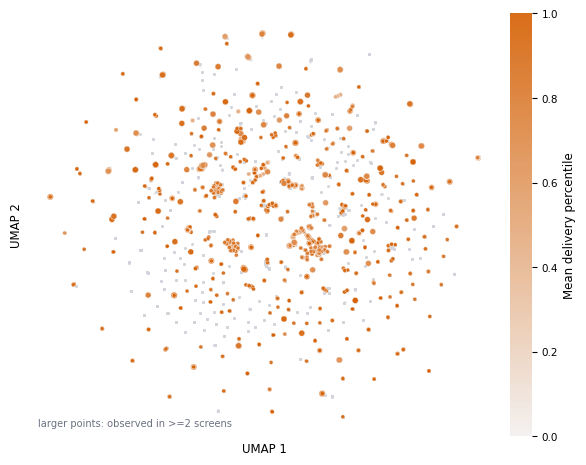

In [ ]:
lipid_perf = (
    screen_lnp_table.dropna(subset=["il_smiles"])
    .groupby("il_smiles", dropna=False)
    .agg(
        il_id=("il_id", lambda s: s.dropna().iloc[0] if len(s.dropna()) else np.nan),
        il_class=("il_class", lambda s: s.dropna().iloc[0] if len(s.dropna()) else np.nan),
        il_class_group=("il_class_group", lambda s: s.dropna().iloc[0] if len(s.dropna()) else np.nan),
        n_formulations=("lnp_id", "nunique"),
        n_screens=("screen_id", pd.Series.nunique),
        n_studies=("study_id", pd.Series.nunique),
        median_delivery_percentile=("delivery_percentile", "median"),
        mean_delivery_percentile=("delivery_percentile", "mean"),
        top10_fraction=("top10_flag", "mean"),
    )
    .reset_index()
)

mols = []
valid = []
for smi in lipid_perf["il_smiles"]:
    mol = Chem.MolFromSmiles(str(smi))
    mols.append(mol)
    valid.append(mol is not None)

lipid_perf["rdkit_valid"] = valid

valid_perf = lipid_perf[lipid_perf["rdkit_valid"]].copy().reset_index(drop=True)
valid_mols = [m for m in mols if m is not None]

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

fps = []
for mol in valid_mols:
    arr = np.zeros((2048,), dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(gen.GetFingerprint(mol), arr)
    fps.append(arr)

fp = np.vstack(fps).astype(bool)

reducer = umap.UMAP(
    n_components=2,
    metric="jaccard",
    n_neighbors=30,
    min_dist=0.06,
    random_state=RANDOM_SEED,
    low_memory=True,
)

coords = reducer.fit_transform(fp)

valid_perf["UMAP1"] = coords[:, 0]
valid_perf["UMAP2"] = coords[:, 1]

chemical_space_source = valid_perf.copy()
save_source(chemical_space_source, "Fig3e_chemical_space_performance_source")

fig, ax = plt.subplots(figsize=(5.8, 4.7))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")


# Background: all valid unique ionizable lipids.
# rasterized=False keeps the PDF vector-sharp.
ax.scatter(
    chemical_space_source["UMAP1"],
    chemical_space_source["UMAP2"],
    s=3.5,
    color="#D1D5DB",
    alpha=0.45,
    linewidth=0,
)

# Highlight lipids observed among top-10% formulations.
top_lipids = chemical_space_source[
    chemical_space_source["top10_fraction"] > 0
].copy()

sc = ax.scatter(
    top_lipids["UMAP1"],
    top_lipids["UMAP2"],
    c=top_lipids["mean_delivery_percentile"],
    s=np.where(top_lipids["n_screens"] >= 2, 18, 8),
    cmap=sns.light_palette("#D55E00", as_cmap=True),
    vmin=0,
    vmax=1,
    alpha=0.90,
    edgecolor="white",
    linewidth=0.25,
)

ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)

cbar = fig.colorbar(sc, ax=ax, fraction=0.045, pad=0.02)
cbar.set_label("Mean delivery percentile")
cbar.outline.set_visible(False)

ax.text(
    0.02,
    0.02,
    f"larger points: observed in >=2 screens",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=7.1,
    color=COLORS["muted"],
)

fig.subplots_adjust(left=0.06, right=0.93, top=0.98, bottom=0.08)

save_figure(fig, "Fig3e_chemical_space_performance", DIRS["panels"])
plt.show()

# Cell 13 — Fig. 3f: Head-group active nitrogen class x lipid-family success map

source data -> /content/cross_study_analysis/source_data/Fig3f_head_architecture_screen_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3f_head_architecture_study_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3f_head_architecture_meta_analysis_source.csv
saved:
  /content/cross_study_analysis/panels/Fig3f_head_class_architecture_evidence_matrix.pdf
  /content/cross_study_analysis/panels/Fig3f_head_class_architecture_evidence_matrix.svg
  /content/cross_study_analysis/panels/Fig3f_head_class_architecture_evidence_matrix.png


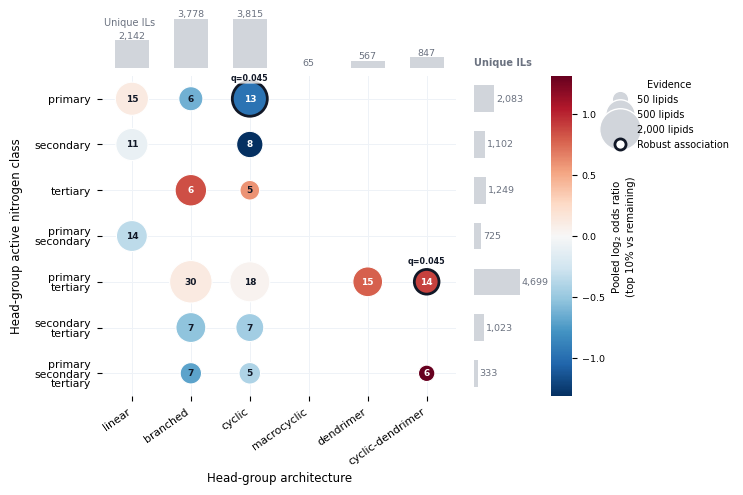


ROBUST HEAD-CLASS × ARCHITECTURE ASSOCIATIONS



,il_head_class,il_head_architecture,unique_lipids_tested,n_screens,n_studies,pooled_log2_or,ci_low,ci_high,directional_consistency,i2,q_value
13,primary_tertiary,cyclic-dendrimer,250,16,14,0.897032,0.278195,1.515868,0.714286,33.294682,0.044957
1,primary,cyclic,1009,14,13,-0.965934,-1.625967,-0.305900,0.769231,51.126417,0.044957


In [ ]:
# ============================================================
# Cell 13 — Fig. 3f: Head-group class x head-group architecture success map
# Cross-study evidence matrix
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from scipy.stats import norm


# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

MIN_COMBO_PER_SCREEN = 3
MIN_STUDIES = 5
MIN_SCREENS = 5
MIN_UNIQUE_LIPIDS = 10
MIN_DIRECTIONAL_CONSISTENCY = 0.70

ARCH_ORDER = [
    "linear",
    "branched",
    "cyclic",
    "macrocyclic",
    "dendrimer",
    "cyclic-dendrimer",
]

HEAD_ORDER_PREFERRED = [
    "primary",
    "secondary",
    "tertiary",
    "primary_secondary",
    "primary_tertiary",
    "secondary_tertiary",
    "primary_secondary_tertiary",
]

LN2 = np.log(2)


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def bh_fdr(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    qvalues = np.full(len(pvalues), np.nan)
    valid = np.isfinite(pvalues)
    p = pvalues[valid]

    if len(p) == 0:
        return qvalues

    order = np.argsort(p)
    ranked = p[order]

    q = ranked * len(ranked) / np.arange(1, len(ranked) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.minimum(q, 1.0)

    temp = np.empty(len(p))
    temp[order] = q
    qvalues[valid] = temp

    return qvalues


def random_effects_meta(effect, variance):
    effect = np.asarray(effect, dtype=float)
    variance = np.asarray(variance, dtype=float)

    valid = np.isfinite(effect) & np.isfinite(variance) & (variance > 0)
    effect = effect[valid]
    variance = variance[valid]

    k = len(effect)
    if k == 0:
        return {
            "pooled_effect": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "p_value": np.nan,
            "tau2": np.nan,
            "i2": np.nan,
        }

    w_fixed = 1 / variance
    fixed_effect = np.sum(w_fixed * effect) / np.sum(w_fixed)

    Q = np.sum(w_fixed * (effect - fixed_effect) ** 2)
    df_q = k - 1
    C = np.sum(w_fixed) - np.sum(w_fixed ** 2) / np.sum(w_fixed)

    tau2 = max(0, (Q - df_q) / C) if C > 0 and k > 1 else 0

    w_random = 1 / (variance + tau2)
    pooled = np.sum(w_random * effect) / np.sum(w_random)
    se = np.sqrt(1 / np.sum(w_random))

    ci_low = pooled - 1.96 * se
    ci_high = pooled + 1.96 * se

    z = pooled / se
    p_value = 2 * norm.sf(abs(z))

    if Q > 0 and k > 1:
        i2 = max(0, (Q - df_q) / Q) * 100
    else:
        i2 = 0

    return {
        "pooled_effect": pooled,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_value": p_value,
        "tau2": tau2,
        "i2": i2,
    }


def format_q(q):
    if pd.isna(q):
        return "NA"
    return "<0.001" if q < 0.001 else f"{q:.3f}"


def pretty_head_label(x):
    x = clean_label(x) if "clean_label" in globals() else str(x).replace("_", " ")
    return (
        x.replace(" primary", "\nprimary")
        .replace(" secondary", "\nsecondary")
        .replace(" tertiary", "\ntertiary")
    )


def pretty_arch_label(x):
    x = clean_label(x) if "clean_label" in globals() else str(x).replace("-", " ")
    return x.replace("cyclic dendrimer", "cyclic-\ndendrimer")


# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

head_df = screen_lnp_table.dropna(
    subset=[
        "il_head_class",
        "il_head_architecture",
        "il_smiles",
        "study_id",
        "screen_id",
    ]
).copy()

head_df["il_head_architecture"] = (
    head_df["il_head_architecture"]
    .astype(str)
    .str.strip()
    .str.lower()
)

head_df["il_head_class"] = (
    head_df["il_head_class"]
    .astype(str)
    .str.strip()
)

undefined_head = {"not reported", "unknown", "nan", "none", ""}
undefined_arch = {"not reported", "unknown", "nan", "none", ""}

head_df = head_df[
    ~head_df["il_head_class"].str.lower().isin(undefined_head)
    & ~head_df["il_head_architecture"].str.lower().isin(undefined_arch)
].copy()

head_df["top10_flag"] = head_df["top10_flag"].astype(bool)


# ------------------------------------------------------------
# Screen-level effects
# ------------------------------------------------------------

screen_effect_rows = []

combinations = (
    head_df[
        ["il_head_class", "il_head_architecture"]
    ]
    .drop_duplicates()
)

for _, combo in combinations.iterrows():

    head = combo["il_head_class"]
    arch = combo["il_head_architecture"]

    for screen_id, sdf in head_df.groupby("screen_id"):

        combo_mask = (
            (sdf["il_head_class"] == head)
            & (sdf["il_head_architecture"] == arch)
        )

        if combo_mask.sum() < MIN_COMBO_PER_SCREEN:
            continue

        top = sdf["top10_flag"]

        a = int((combo_mask & top).sum())
        b = int((combo_mask & ~top).sum())
        c = int((~combo_mask & top).sum())
        d = int((~combo_mask & ~top).sum())

        cells = np.array([a, b, c, d], dtype=float)

        if np.any(cells == 0):
            cells += 0.5

        a2, b2, c2, d2 = cells

        ln_or = np.log((a2 * d2) / (b2 * c2))

        var_ln_or = (
            1 / a2
            + 1 / b2
            + 1 / c2
            + 1 / d2
        )

        log2_or = ln_or / LN2
        var_log2_or = var_ln_or / (LN2 ** 2)

        screen_effect_rows.append({
            "study_id": sdf["study_id"].iloc[0],
            "screen_id": screen_id,
            "il_head_class": head,
            "il_head_architecture": arch,
            "log2_or": log2_or,
            "variance": var_log2_or,
            "combo_formulations": int(combo_mask.sum()),
            "top_combo": a,
            "top_total": int(top.sum()),
            "screen_total": len(sdf),
        })


head_screen_effects = pd.DataFrame(screen_effect_rows)


# ------------------------------------------------------------
# Collapse multiple screens from the same study
# ------------------------------------------------------------

study_effect_rows = []

for (head, arch, study_id), sdf in head_screen_effects.groupby(
    ["il_head_class", "il_head_architecture", "study_id"]
):

    effects = sdf["log2_or"].to_numpy()
    variances = sdf["variance"].to_numpy()
    weights = 1 / variances

    study_effect = np.sum(weights * effects) / np.sum(weights)
    study_variance = 1 / np.sum(weights)

    study_effect_rows.append({
        "study_id": study_id,
        "il_head_class": head,
        "il_head_architecture": arch,
        "study_effect": study_effect,
        "study_variance": study_variance,
        "n_screens_in_study": sdf["screen_id"].nunique(),
    })


head_study_effects = pd.DataFrame(study_effect_rows)


# ------------------------------------------------------------
# Random-effects meta-analysis across studies
# ------------------------------------------------------------

meta_rows = []

for (head, arch), sdf in head_study_effects.groupby(
    ["il_head_class", "il_head_architecture"]
):

    meta = random_effects_meta(
        sdf["study_effect"],
        sdf["study_variance"],
    )

    pooled = meta["pooled_effect"]

    if pooled > 0:
        consistency = np.mean(sdf["study_effect"] > 0)
    elif pooled < 0:
        consistency = np.mean(sdf["study_effect"] < 0)
    else:
        consistency = np.nan

    original_combo = head_df[
        (head_df["il_head_class"] == head)
        & (head_df["il_head_architecture"] == arch)
    ]

    contributing_screens = (
        head_screen_effects[
            (head_screen_effects["il_head_class"] == head)
            & (head_screen_effects["il_head_architecture"] == arch)
        ]["screen_id"]
        .nunique()
    )

    meta_rows.append({
        "il_head_class": head,
        "il_head_architecture": arch,
        "unique_lipids_tested": original_combo["il_smiles"].nunique(),
        "n_screens": int(contributing_screens),
        "n_studies": int(sdf["study_id"].nunique()),
        "pooled_log2_or": meta["pooled_effect"],
        "ci_low": meta["ci_low"],
        "ci_high": meta["ci_high"],
        "tau2": meta["tau2"],
        "i2": meta["i2"],
        "p_value": meta["p_value"],
        "directional_consistency": consistency,
    })


head_arch_meta = pd.DataFrame(meta_rows)


# ------------------------------------------------------------
# Multiple-testing correction and robustness rule
# ------------------------------------------------------------

head_arch_meta["q_value"] = bh_fdr(head_arch_meta["p_value"])

head_arch_meta["support_pass"] = (
    (head_arch_meta["unique_lipids_tested"] >= MIN_UNIQUE_LIPIDS)
    & (head_arch_meta["n_screens"] >= MIN_SCREENS)
    & (head_arch_meta["n_studies"] >= MIN_STUDIES)
)

head_arch_meta["passes_robustness_rule"] = (
    head_arch_meta["support_pass"]
    & (head_arch_meta["q_value"] < 0.05)
    & (head_arch_meta["directional_consistency"] >= MIN_DIRECTIONAL_CONSISTENCY)
)


save_source(head_screen_effects, "Fig3f_head_architecture_screen_effects_source")
save_source(head_study_effects, "Fig3f_head_architecture_study_effects_source")
save_source(head_arch_meta, "Fig3f_head_architecture_meta_analysis_source")


# ------------------------------------------------------------
# Orders
# ------------------------------------------------------------

x_order = [
    x for x in ARCH_ORDER
    if x in head_arch_meta["il_head_architecture"].unique()
]

observed_heads = (
    head_arch_meta["il_head_class"]
    .dropna()
    .unique()
    .tolist()
)

y_order = [
    h for h in HEAD_ORDER_PREFERRED
    if h in observed_heads
]

y_order += [
    h for h in observed_heads
    if h not in y_order
]


# ------------------------------------------------------------
# Marginal chemical coverage
# ------------------------------------------------------------

arch_coverage = (
    head_df
    .groupby("il_head_architecture")["il_smiles"]
    .nunique()
    .reindex(x_order)
    .fillna(0)
)

head_coverage = (
    head_df
    .groupby("il_head_class")["il_smiles"]
    .nunique()
    .reindex(y_order)
    .fillna(0)
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plot_df = head_arch_meta[head_arch_meta["support_pass"]].copy()

plot_df["x"] = plot_df["il_head_architecture"].map({
    v: i for i, v in enumerate(x_order)
})

plot_df["y"] = plot_df["il_head_class"].map({
    v: i for i, v in enumerate(y_order)
})

plot_df = plot_df.dropna(subset=["x", "y"]).copy()
plot_df["x"] = plot_df["x"].astype(int)
plot_df["y"] = plot_df["y"].astype(int)

fig = plt.figure(
    figsize=(8.6, max(4.8, 0.58 * len(y_order) + 1.7))
)

gs = gridspec.GridSpec(
    2,
    4,
    width_ratios=[5.8, 0.95, 0.35, 1.45],
    height_ratios=[0.85, 5.2],
    hspace=0.04,
    wspace=0.14,
)

ax_top = fig.add_subplot(gs[0, 0])
ax = fig.add_subplot(gs[1, 0])
ax_right = fig.add_subplot(gs[1, 1], sharey=ax)
cax = fig.add_subplot(gs[1, 2])
ax_leg = fig.add_subplot(gs[1, 3])

fig.patch.set_facecolor("white")
ax.set_facecolor("white")


# ------------------------------------------------------------
# Top marginal coverage
# ------------------------------------------------------------

ax_top.bar(
    np.arange(len(x_order)),
    arch_coverage.values,
    width=0.58,
    color="#D1D5DB",
)

ax_top.set_xlim(-0.5, len(x_order) - 0.5)
ax_top.set_xticks([])
ax_top.set_yticks([])

for spine in ax_top.spines.values():
    spine.set_visible(False)

for i, value in enumerate(arch_coverage.values):
    ax_top.text(
        i,
        value,
        f"{int(value):,}",
        ha="center",
        va="bottom",
        fontsize=6.8,
        color="#6B7280",
    )

ax_top.text(
    -0.48,
    ax_top.get_ylim()[1] * 0.82,
    "Unique ILs",
    fontsize=7,
    color="#6B7280",
)


# ------------------------------------------------------------
# Main evidence matrix
# ------------------------------------------------------------

vmax = np.nanpercentile(np.abs(plot_df["pooled_log2_or"]), 95)
vmax = max(vmax, 1.0)

norm_color = TwoSlopeNorm(
    vmin=-vmax,
    vcenter=0,
    vmax=vmax,
)

size_scale = 20

def bubble_area(n):
    return np.sqrt(n) * size_scale

sizes = bubble_area(plot_df["unique_lipids_tested"])

nonrobust = ~plot_df["passes_robustness_rule"]
robust = plot_df["passes_robustness_rule"]
significant = plot_df["q_value"] < 0.05

sc = ax.scatter(
    plot_df.loc[nonrobust, "x"],
    plot_df.loc[nonrobust, "y"],
    s=sizes[nonrobust],
    c=plot_df.loc[nonrobust, "pooled_log2_or"],
    cmap="RdBu_r",
    norm=norm_color,
    edgecolor="white",
    linewidth=0.8,
    zorder=3,
)

ax.scatter(
    plot_df.loc[robust, "x"],
    plot_df.loc[robust, "y"],
    s=sizes[robust],
    c=plot_df.loc[robust, "pooled_log2_or"],
    cmap="RdBu_r",
    norm=norm_color,
    edgecolor="#111827",
    linewidth=2.0,
    zorder=4,
)

# Number inside each bubble = independent studies.
for _, row in plot_df.iterrows():
    effect = row["pooled_log2_or"]
    text_color = "white" if abs(effect) > 0.55 * vmax else "#111827"

    ax.text(
        row["x"],
        row["y"],
        f"{int(row['n_studies'])}",
        ha="center",
        va="center",
        fontsize=6.5,
        fontweight="bold",
        color=text_color,
        zorder=5,
    )

# q-value above significant bubbles.
for _, row in plot_df[significant].iterrows():
    ax.text(
        row["x"],
        row["y"] - 0.45,
        f"q={format_q(row['q_value'])}",
        ha="center",
        va="center",
        fontsize=5.8,
        fontweight="bold",
        color="#111827",
        zorder=6,
        clip_on=False,
        bbox=dict(
            boxstyle="round,pad=0.12",
            facecolor="white",
            edgecolor="none",
            alpha=0.80,
        ),
    )

ax.set_xticks(range(len(x_order)))
ax.set_xticklabels(
    [pretty_arch_label(x) for x in x_order],
    rotation=35,
    ha="right",
    fontsize=7.8,
)

ax.set_yticks(range(len(y_order)))
ax.set_yticklabels(
    [pretty_head_label(y) for y in y_order],
    fontsize=7.8,
    linespacing=0.95,
)

ax.tick_params(axis="y", pad=5)
ax.set_xlabel("Head-group architecture")
ax.set_ylabel("Head-group active nitrogen class", labelpad=8)

ax.set_xlim(-0.5, len(x_order) - 0.5)
ax.set_ylim(len(y_order) - 0.5, -0.5)

ax.grid(color="#EEF2F7", linewidth=0.7)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)



# ------------------------------------------------------------
# Right marginal coverage
# ------------------------------------------------------------

ax_right.barh(
    np.arange(len(y_order)),
    head_coverage.values,
    height=0.58,
    color="#D1D5DB",
)

ax_right.set_xticks([])
ax_right.tick_params(axis="y", left=False, labelleft=False)

for spine in ax_right.spines.values():
    spine.set_visible(False)

xmax_right = max(head_coverage.max(), 1)
ax_right.set_xlim(0, xmax_right * 1.28)

for i, value in enumerate(head_coverage.values):
    ax_right.text(
        value + xmax_right * 0.035,
        i,
        f"{int(value):,}",
        va="center",
        ha="left",
        fontsize=6.8,
        color="#6B7280",
    )

ax_right.text(
    0,
    -0.72,
    "Unique ILs",
    fontsize=7,
    color="#6B7280",
    fontweight="bold",
)


# ------------------------------------------------------------
# Color bar
# ------------------------------------------------------------

cbar = fig.colorbar(sc, cax=cax)
cbar.set_label(
    "Pooled log$_2$ odds ratio\n(top 10% vs remaining)",
    fontsize=7.4,
)
cbar.ax.tick_params(labelsize=6.8)
cbar.outline.set_visible(False)


# ------------------------------------------------------------
# Bubble-size and robust-outline legend
# ------------------------------------------------------------

ax_leg.axis("off")

size_examples = [50, 500, 2000]

handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markersize=np.sqrt(bubble_area(n)),
        markerfacecolor="#D1D5DB",
        markeredgecolor="white",
        label=f"{n:,} lipids",
    )
    for n in size_examples
]

handles.append(
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markersize=8,
        markerfacecolor="white",
        markeredgecolor="#111827",
        markeredgewidth=2,
        label="Robust association",
    )
)

ax_leg.legend(
    handles=handles,
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(0.18, 1.0),
    fontsize=7,
    title="Evidence",
    title_fontsize=7,
    borderaxespad=0,
)


# ------------------------------------------------------------
# Small explanation
# ------------------------------------------------------------



fig.subplots_adjust(
    left=0.31,
    right=0.98,
    top=0.96,
    bottom=0.30,
)


save_figure(
    fig,
    "Fig3f_head_class_architecture_evidence_matrix",
    DIRS["panels"],
)

plt.show()


# ------------------------------------------------------------
# Print statistically robust combinations
# ------------------------------------------------------------

robust_results = (
    head_arch_meta[
        head_arch_meta["passes_robustness_rule"]
    ]
    .sort_values(
        "pooled_log2_or",
        ascending=False,
    )
)

print(
    "\nROBUST HEAD-CLASS × ARCHITECTURE ASSOCIATIONS\n"
)

display(
    robust_results[
        [
            "il_head_class",
            "il_head_architecture",
            "unique_lipids_tested",
            "n_screens",
            "n_studies",
            "pooled_log2_or",
            "ci_low",
            "ci_high",
            "directional_consistency",
            "i2",
            "q_value",
        ]
    ]
)

# Prin the table associated with this figure

In [ ]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

display(
    head_arch_meta[
        [
            "il_head_class",
            "il_head_architecture",
            "unique_lipids_tested",
            "n_screens",
            "n_studies",
            "pooled_log2_or",
            "ci_low",
            "ci_high",
            "directional_consistency",
            "i2",
            "q_value",
            "passes_robustness_rule",
        ]
    ].sort_values("pooled_log2_or", ascending=False)
)

,il_head_class,il_head_architecture,unique_lipids_tested,n_screens,n_studies,pooled_log2_or,ci_low,ci_high,directional_consistency,i2,q_value,passes_robustness_rule
10,primary_secondary_tertiary,cyclic-dendrimer,49,6,6,1.306207,-0.074015,2.686430,0.333333,25.123684,0.349073,False
2,primary,cyclic-dendrimer,31,3,3,1.242097,-0.984848,3.469042,0.666667,40.658583,0.658588,False
23,secondary_tertiary,cyclic-dendrimer,30,1,1,1.241008,-0.100540,2.582556,1.000000,0.000000,0.349073,False
25,secondary_tertiary,macrocyclic,10,1,1,1.192645,-1.070999,3.456289,1.000000,0.000000,0.658588,False
28,tertiary,cyclic-dendrimer,482,2,1,1.052904,0.649046,1.456761,1.000000,0.000000,0.000010,False
5,primary_secondary,branched,5,1,1,1.027623,-3.172063,5.227309,1.000000,0.000000,0.817692,False
18,secondary,cyclic-dendrimer,5,1,1,1.027623,-3.172063,5.227309,1.000000,0.000000,0.817692,False
4,primary,macrocyclic,5,1,1,1.027623,-3.172063,5.227309,1.000000,0.000000,0.817692,False
13,primary_tertiary,cyclic-dendrimer,250,16,14,0.897032,0.278195,1.515868,0.714286,33.294682,0.044957,True
26,tertiary,branched,661,7,6,0.849966,-0.694882,2.394813,0.666667,90.923523,0.658588,False


In [ ]:
df['il_head_architecture'].unique()

array(['linear', 'branched', 'dendrimer', 'cyclic-dendrimer', 'cyclic',
       'unknown', 'macrocyclic'], dtype=object)

source data -> /content/cross_study_analysis/source_data/Fig3g_representative_head_group_examples.csv
Saved vector SVG -> /content/cross_study_analysis/panels/Fig3g_representative_head_group_examples.svg
Saved vector PDF -> /content/cross_study_analysis/panels/Fig3g_representative_head_group_examples.pdf


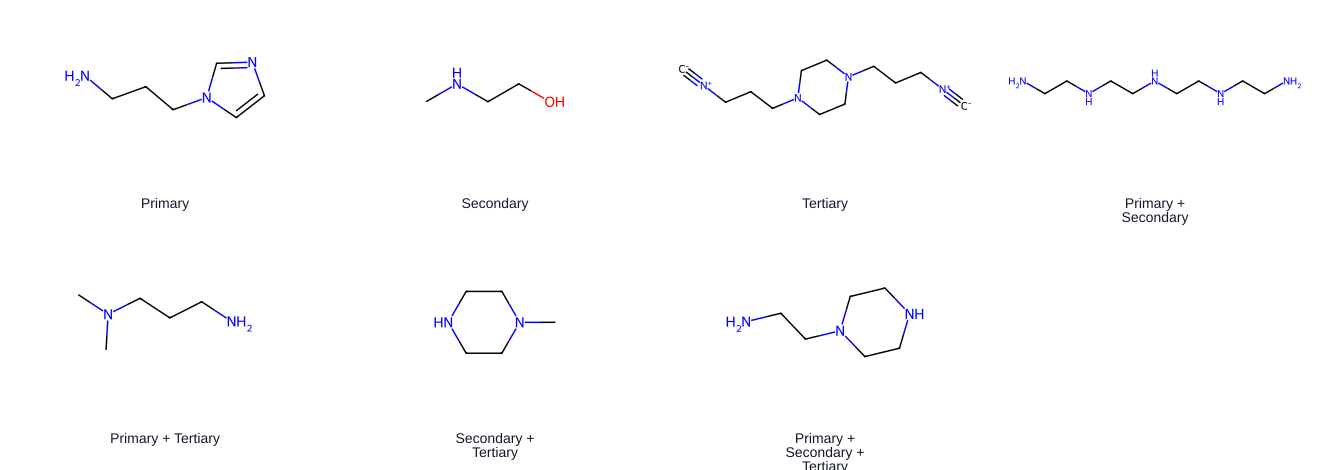

In [ ]:
# ============================================================
# Cell 14 — Representative lipid head-group examples
# Compact VECTOR schematic examples for each il_head_class
# ============================================================

import re
import textwrap
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D

work = df.copy()

HEAD_CLASS_COL = "il_head_class"
HEAD_SMILES_COL = "il_head_smiles"

required = [HEAD_CLASS_COL, HEAD_SMILES_COL]
missing = [c for c in required if c not in work.columns]
if missing:
    raise ValueError(f"Missing required column(s): {missing}")

bad_labels = {
    "",
    "nan",
    "none",
    "not reported",
    "not_reported",
    "unknown",
    "unclear",
}

work[HEAD_CLASS_COL] = work[HEAD_CLASS_COL].astype(str).str.strip()
work[HEAD_SMILES_COL] = work[HEAD_SMILES_COL].astype(str).str.strip()

head_df = work[
    (~work[HEAD_CLASS_COL].str.lower().isin(bad_labels)) &
    (~work[HEAD_SMILES_COL].str.lower().isin(bad_labels))
].copy()

primary_n = Chem.MolFromSmarts("[NX3;H2;!$(NC=O)]")
secondary_n = Chem.MolFromSmarts("[NX3;H1;!$(NC=O)]")
tertiary_n = Chem.MolFromSmarts("[NX3;H0;!$(NC=O)]")

def valid_mol(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    return mol if mol is not None else None

def has_primary_n(mol):
    return mol.HasSubstructMatch(primary_n)

def has_secondary_n(mol):
    return mol.HasSubstructMatch(secondary_n)

def has_tertiary_n(mol):
    return mol.HasSubstructMatch(tertiary_n)

def matches_head_class(smiles, head_class):
    mol = valid_mol(smiles)
    if mol is None:
        return False

    hc = str(head_class).lower()

    if hc == "primary":
        return has_primary_n(mol) and not has_secondary_n(mol) and not has_tertiary_n(mol)

    if hc == "secondary":
        return has_secondary_n(mol) and not has_primary_n(mol) and not has_tertiary_n(mol)

    if hc == "tertiary":
        return has_tertiary_n(mol) and not has_primary_n(mol) and not has_secondary_n(mol)

    if hc == "primary_secondary":
        return has_primary_n(mol) and has_secondary_n(mol)

    if hc == "primary_tertiary":
        return has_primary_n(mol) and has_tertiary_n(mol)

    if hc == "secondary_tertiary":
        return has_secondary_n(mol) and has_tertiary_n(mol)

    if hc == "primary_secondary_tertiary":
        return has_primary_n(mol) and has_secondary_n(mol) and has_tertiary_n(mol)

    return True

examples = []

for head_class, sdf in head_df.groupby(HEAD_CLASS_COL):
    smiles_counts = sdf[HEAD_SMILES_COL].value_counts()
    valid_smiles = [smi for smi in smiles_counts.index if valid_mol(smi) is not None]

    if not valid_smiles:
        continue

    matched_smiles = [
        smi for smi in valid_smiles
        if matches_head_class(smi, head_class)
    ]

    chosen_smiles = matched_smiles[0] if matched_smiles else valid_smiles[0]

    examples.append({
        "il_head_class": head_class,
        "example_il_head_smiles": chosen_smiles,
    })

examples = pd.DataFrame(examples)

preferred_order = [
    "primary",
    "secondary",
    "tertiary",
    "primary_secondary",
    "primary_tertiary",
    "secondary_tertiary",
    "primary_secondary_tertiary",
]

examples["order"] = examples["il_head_class"].apply(
    lambda x: preferred_order.index(x) if x in preferred_order else 999
)

examples = (
    examples
    .sort_values(["order", "il_head_class"])
    .drop(columns="order")
    .reset_index(drop=True)
)

save_source(examples, "Fig3g_representative_head_group_examples")

def pretty_head_class(label):
    return str(label).replace("_", " + ").title()

def mol_to_svg_inner(smiles, width=430, height=250):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return ""

    rdDepictor.Compute2DCoords(mol)

    drawer = rdMolDraw2D.MolDraw2DSVG(width, height)
    opts = drawer.drawOptions()
    opts.clearBackground = False
    opts.bondLineWidth = 2.1
    opts.fixedBondLength = 34
    opts.padding = 0.015

    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()

    svg = drawer.GetDrawingText()

    svg = re.sub(r"<\?xml.*?\?>", "", svg, flags=re.DOTALL)
    svg = re.sub(r"<!DOCTYPE.*?>", "", svg, flags=re.DOTALL)
    svg = re.sub(r"^.*?<svg[^>]*>", "", svg, flags=re.DOTALL)
    svg = re.sub(r"</svg>\s*$", "", svg, flags=re.DOTALL)

    return svg

# ============================================================
# Build compact vector SVG figure
# ============================================================

n = len(examples)
nrows = 2
ncols = int(np.ceil(n / nrows))

mol_w = 430
mol_h = 250

cell_w = 330
cell_h = 235

canvas_w = ncols * cell_w
canvas_h = nrows * cell_h

svg_parts = []

svg_parts.append(
    f"""
<svg xmlns="http://www.w3.org/2000/svg"
     width="{canvas_w}"
     height="{canvas_h}"
     viewBox="0 0 {canvas_w} {canvas_h}">
<rect width="100%" height="100%" fill="white"/>
"""
)

for idx, (_, row) in enumerate(examples.iterrows()):
    r = idx // ncols
    c = idx % ncols

    x0 = c * cell_w
    y0 = r * cell_h

    mol_svg = mol_to_svg_inner(
        row["example_il_head_smiles"],
        width=mol_w,
        height=mol_h,
    )

    scale = 0.70
    mol_x = x0 + (cell_w - mol_w * scale) / 2
    mol_y = y0 + 0

    svg_parts.append(
        f"""
<g transform="translate({mol_x:.2f},{mol_y:.2f}) scale({scale:.4f})">
{mol_svg}
</g>
"""
    )

    label = pretty_head_class(row["il_head_class"])
    label_lines = textwrap.wrap(label, width=18)

    label_y = y0 + cell_h - 27
    line_gap = 14

    for j, line in enumerate(label_lines):
        svg_parts.append(
            f"""
<text x="{x0 + cell_w / 2:.2f}"
      y="{label_y + j * line_gap:.2f}"
      text-anchor="middle"
      font-family="Arial, Helvetica, sans-serif"
      font-size="14"
      fill="#111827">{line}</text>
"""
        )

svg_parts.append("</svg>")
svg_text = "\n".join(svg_parts)

# ============================================================
# Save vector SVG and vector PDF
# ============================================================

outdir = DIRS["panels"]
outdir.mkdir(parents=True, exist_ok=True)

base = "Fig3g_representative_head_group_examples"

svg_path = outdir / f"{base}.svg"
pdf_path = outdir / f"{base}.pdf"

with open(svg_path, "w", encoding="utf-8") as f:
    f.write(svg_text)

try:
    import cairosvg
except ImportError:
    !pip -q install cairosvg
    import cairosvg

cairosvg.svg2pdf(
    bytestring=svg_text.encode("utf-8"),
    write_to=str(pdf_path),
)

print(f"Saved vector SVG -> {svg_path}")
print(f"Saved vector PDF -> {pdf_path}")

from IPython.display import SVG, display
display(SVG(filename=str(svg_path)))

source data -> /content/cross_study_analysis/source_data/Fig3h_representative_head_architecture_examples.csv
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.6/75.6 kB 3.9 MB/s eta 0:00:00
Saved vector SVG -> /content/cross_study_analysis/panels/Fig3h_representative_head_architecture_examples.svg
Saved vector PDF -> /content/cross_study_analysis/panels/Fig3h_representative_head_architecture_examples.pdf


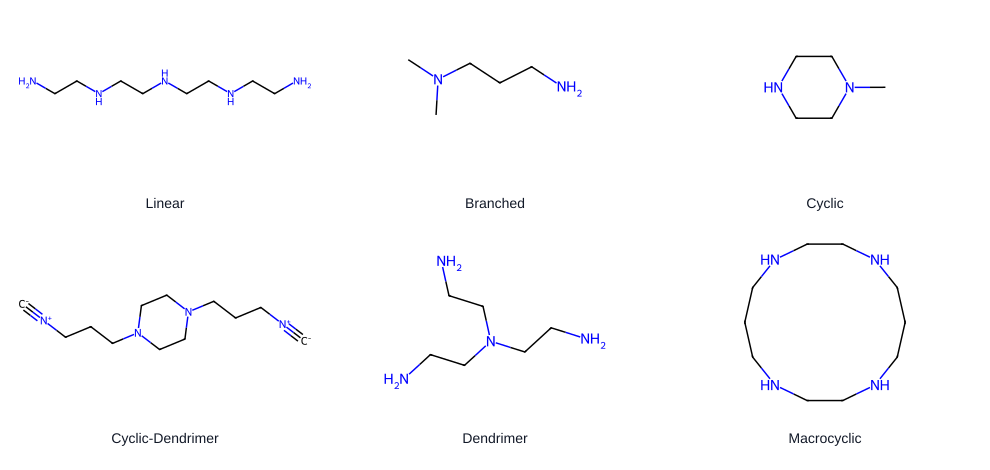

In [ ]:
# ============================================================
# Cell 14 — Representative lipid head-architecture examples
# Compact VECTOR schematic examples for each il_head_architecture
# ============================================================

from io import BytesIO
import re
import textwrap
import numpy as np
import pandas as pd
from pathlib import Path
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D

work = df.copy()

ARCH_COL = "il_head_architecture"
HEAD_SMILES_COL = "il_head_smiles"

required = [ARCH_COL, HEAD_SMILES_COL]
missing = [c for c in required if c not in work.columns]
if missing:
    raise ValueError(f"Missing required column(s): {missing}")

bad_labels = {
    "",
    "nan",
    "none",
    "not reported",
    "not_reported",
    "unknown",
    "unclear",
}

work[ARCH_COL] = work[ARCH_COL].astype(str).str.strip()
work[HEAD_SMILES_COL] = work[HEAD_SMILES_COL].astype(str).str.strip()

arch_df = work[
    (~work[ARCH_COL].str.lower().isin(bad_labels)) &
    (~work[HEAD_SMILES_COL].str.lower().isin(bad_labels))
].copy()

def valid_mol(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    return mol if mol is not None else None

def has_ring(smiles):
    mol = valid_mol(smiles)
    return mol is not None and mol.GetRingInfo().NumRings() > 0

def has_branching(smiles):
    mol = valid_mol(smiles)
    if mol is None:
        return False

    return any(
        atom.GetDegree() >= 3 and atom.GetAtomicNum() in {6, 7, 8}
        for atom in mol.GetAtoms()
    )

def architecture_match_score(smiles, architecture):
    arch = str(architecture).lower()
    ring = has_ring(smiles)
    branched = has_branching(smiles)

    if "cyclic" in arch or "ring" in arch:
        return int(ring)

    if "branched" in arch:
        return int(branched and not ring)

    if "linear" in arch:
        return int((not branched) and (not ring))

    return 0

examples = []

for architecture, sdf in arch_df.groupby(ARCH_COL):
    smiles_counts = sdf[HEAD_SMILES_COL].value_counts()
    valid_smiles = [smi for smi in smiles_counts.index if valid_mol(smi) is not None]

    if not valid_smiles:
        continue

    ranked = sorted(
        valid_smiles,
        key=lambda smi: (
            architecture_match_score(smi, architecture),
            smiles_counts.loc[smi],
        ),
        reverse=True,
    )

    examples.append({
        "il_head_architecture": architecture,
        "example_il_head_smiles": ranked[0],
    })

examples = pd.DataFrame(examples)

preferred_order = [
    "linear",
    "branched",
    "cyclic",
    "linear_branched",
    "linear_cyclic",
    "branched_cyclic",
    "linear_branched_cyclic",
]

examples["order"] = examples["il_head_architecture"].apply(
    lambda x: preferred_order.index(x) if x in preferred_order else 999
)

examples = (
    examples
    .sort_values(["order", "il_head_architecture"])
    .drop(columns="order")
    .reset_index(drop=True)
)

save_source(examples, "Fig3h_representative_head_architecture_examples")

def pretty_architecture(label):
    return str(label).replace("_", " + ").title()

def mol_to_svg_inner(smiles, width=430, height=250):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return ""

    rdDepictor.Compute2DCoords(mol)

    drawer = rdMolDraw2D.MolDraw2DSVG(width, height)
    opts = drawer.drawOptions()
    opts.clearBackground = False
    opts.bondLineWidth = 2.1
    opts.fixedBondLength = 34
    opts.padding = 0.015

    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()

    svg = drawer.GetDrawingText()

    # Remove XML declaration and outer <svg> wrapper; keep vector molecule paths.
    svg = re.sub(r"<\?xml.*?\?>", "", svg, flags=re.DOTALL)
    svg = re.sub(r"<!DOCTYPE.*?>", "", svg, flags=re.DOTALL)
    svg = re.sub(r"^.*?<svg[^>]*>", "", svg, flags=re.DOTALL)
    svg = re.sub(r"</svg>\s*$", "", svg, flags=re.DOTALL)

    return svg

# ============================================================
# Build a vector SVG figure manually
# ============================================================

n = len(examples)
nrows = 2
ncols = int(np.ceil(n / nrows))

mol_w = 430
mol_h = 250

cell_w = 330
cell_h = 235

canvas_w = ncols * cell_w
canvas_h = nrows * cell_h

svg_parts = []

svg_parts.append(
    f"""
<svg xmlns="http://www.w3.org/2000/svg"
     width="{canvas_w}"
     height="{canvas_h}"
     viewBox="0 0 {canvas_w} {canvas_h}">
<rect width="100%" height="100%" fill="white"/>
"""
)

for idx, (_, row) in enumerate(examples.iterrows()):
    r = idx // ncols
    c = idx % ncols

    x0 = c * cell_w
    y0 = r * cell_h

    mol_svg = mol_to_svg_inner(row["example_il_head_smiles"], width=mol_w, height=mol_h)

    # Scale molecule down into the compact layout while keeping it vector.
    scale = 0.70
    mol_x = x0 + (cell_w - mol_w * scale) / 2
    mol_y = y0 + 0

    svg_parts.append(
        f"""
<g transform="translate({mol_x:.2f},{mol_y:.2f}) scale({scale:.4f})">
{mol_svg}
</g>
"""
    )

    label = pretty_architecture(row["il_head_architecture"])
    label_lines = textwrap.wrap(label, width=18)

    label_y = y0 + cell_h - 27
    line_gap = 14

    for j, line in enumerate(label_lines):
        svg_parts.append(
            f"""
<text x="{x0 + cell_w / 2:.2f}"
      y="{label_y + j * line_gap:.2f}"
      text-anchor="middle"
      font-family="Arial, Helvetica, sans-serif"
      font-size="14"
      fill="#111827">{line}</text>
"""
        )

svg_parts.append("</svg>")

svg_text = "\n".join(svg_parts)

# ============================================================
# Save vector SVG and vector PDF
# ============================================================

outdir = DIRS["panels"]
outdir.mkdir(parents=True, exist_ok=True)

base = "Fig3h_representative_head_architecture_examples"

svg_path = outdir / f"{base}.svg"
pdf_path = outdir / f"{base}.pdf"

with open(svg_path, "w", encoding="utf-8") as f:
    f.write(svg_text)

try:
    import cairosvg
except ImportError:
    !pip -q install cairosvg
    import cairosvg

cairosvg.svg2pdf(
    bytestring=svg_text.encode("utf-8"),
    write_to=str(pdf_path),
)

print(f"Saved vector SVG -> {svg_path}")
print(f"Saved vector PDF -> {pdf_path}")

from IPython.display import SVG, display
display(SVG(filename=str(svg_path)))

## T-SNE dont run

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 13988 samples in 0.073s...


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/pairwise.py:2466: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/pairwise.py:2466: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


[t-SNE] Computed neighbors for 13988 samples in 1457.259s...
[t-SNE] Computed conditional probabilities for sample 1000 / 13988
[t-SNE] Computed conditional probabilities for sample 2000 / 13988
[t-SNE] Computed conditional probabilities for sample 3000 / 13988
[t-SNE] Computed conditional probabilities for sample 4000 / 13988
[t-SNE] Computed conditional probabilities for sample 5000 / 13988
[t-SNE] Computed conditional probabilities for sample 6000 / 13988
[t-SNE] Computed conditional probabilities for sample 7000 / 13988
[t-SNE] Computed conditional probabilities for sample 8000 / 13988
[t-SNE] Computed conditional probabilities for sample 9000 / 13988
[t-SNE] Computed conditional probabilities for sample 10000 / 13988
[t-SNE] Computed conditional probabilities for sample 11000 / 13988
[t-SNE] Computed conditional probabilities for sample 12000 / 13988
[t-SNE] Computed conditional probabilities for sample 13000 / 13988
[t-SNE] Computed conditional probabilities for sample 13988 / 13

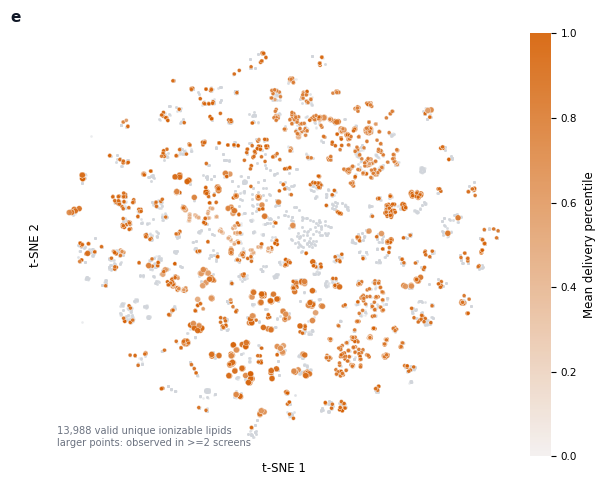

In [ ]:
from sklearn.manifold import TSNE

# ============================================================
# t-SNE chemical-space map of ionizable lipids
# ============================================================

# Assumes these already exist from the previous cell:
# lipid_perf
# valid_perf
# fp
# RANDOM_SEED
# COLORS
# save_source
# save_figure
# DIRS


# ------------------------------------------------------------
# 1. Run t-SNE on Morgan fingerprints
# ------------------------------------------------------------

tsne = TSNE(
    n_components=2,
    perplexity=30,
    metric="jaccard",
    init="random",
    learning_rate="auto",
    max_iter=1000,
    random_state=RANDOM_SEED,
    method="barnes_hut",
    n_jobs=-1,
    verbose=1,
)

coords_tsne = tsne.fit_transform(fp)

valid_perf["TSNE1"] = coords_tsne[:, 0]
valid_perf["TSNE2"] = coords_tsne[:, 1]


# ------------------------------------------------------------
# 2. Save source data
# ------------------------------------------------------------

chemical_space_tsne_source = valid_perf.copy()

save_source(
    chemical_space_tsne_source,
    "Fig3e_TSNE_chemical_space_performance_source"
)


# ------------------------------------------------------------
# 3. Plot all lipids in grey
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5.8, 4.7))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

add_panel_label(ax, "e", x=-0.08, y=1.02)

ax.scatter(
    chemical_space_tsne_source["TSNE1"],
    chemical_space_tsne_source["TSNE2"],
    s=3.5,
    color="#D1D5DB",
    alpha=0.45,
    linewidth=0,
    rasterized=True,
)


# ------------------------------------------------------------
# 4. Highlight lipids that reached top 10% at least once
# ------------------------------------------------------------

top_lipids = chemical_space_tsne_source[
    chemical_space_tsne_source["top10_fraction"] > 0
].copy()

sc = ax.scatter(
    top_lipids["TSNE1"],
    top_lipids["TSNE2"],

    # Color = average delivery performance
    c=top_lipids["mean_delivery_percentile"],

    # Larger if observed in >=2 screens
    s=np.where(
        top_lipids["n_screens"] >= 2,
        18,
        8
    ),

    cmap=sns.light_palette("#D55E00", as_cmap=True),
    vmin=0,
    vmax=1,
    alpha=0.90,
    edgecolor="white",
    linewidth=0.25,
    rasterized=True,
)


# ------------------------------------------------------------
# 5. Formatting
# ------------------------------------------------------------

ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")

ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)


# Color bar
cbar = fig.colorbar(
    sc,
    ax=ax,
    fraction=0.045,
    pad=0.02
)

cbar.set_label("Mean delivery percentile")
cbar.outline.set_visible(False)


# Annotation
ax.text(
    0.02,
    0.02,
    (
        f"{len(chemical_space_tsne_source):,} valid unique ionizable lipids\n"
        "larger points: observed in >=2 screens"
    ),
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=7.1,
    color=COLORS["muted"],
)


fig.subplots_adjust(
    left=0.06,
    right=0.93,
    top=0.98,
    bottom=0.08
)


# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

save_figure(
    fig,
    "Fig3e_TSNE_chemical_space_performance",
    DIRS["panels"]
)

plt.show()

# Supplementary Fig. 4 — Top 5/10/20% sensitivity analysis

source data -> /content/cross_study_analysis/source_data/SuppFig4_top_threshold_sensitivity_source.csv
saved:
  /content/cross_study_analysis/supplementary_figures/Supplementary_Fig4_top_threshold_sensitivity.pdf
  /content/cross_study_analysis/supplementary_figures/Supplementary_Fig4_top_threshold_sensitivity.svg
  /content/cross_study_analysis/supplementary_figures/Supplementary_Fig4_top_threshold_sensitivity.png


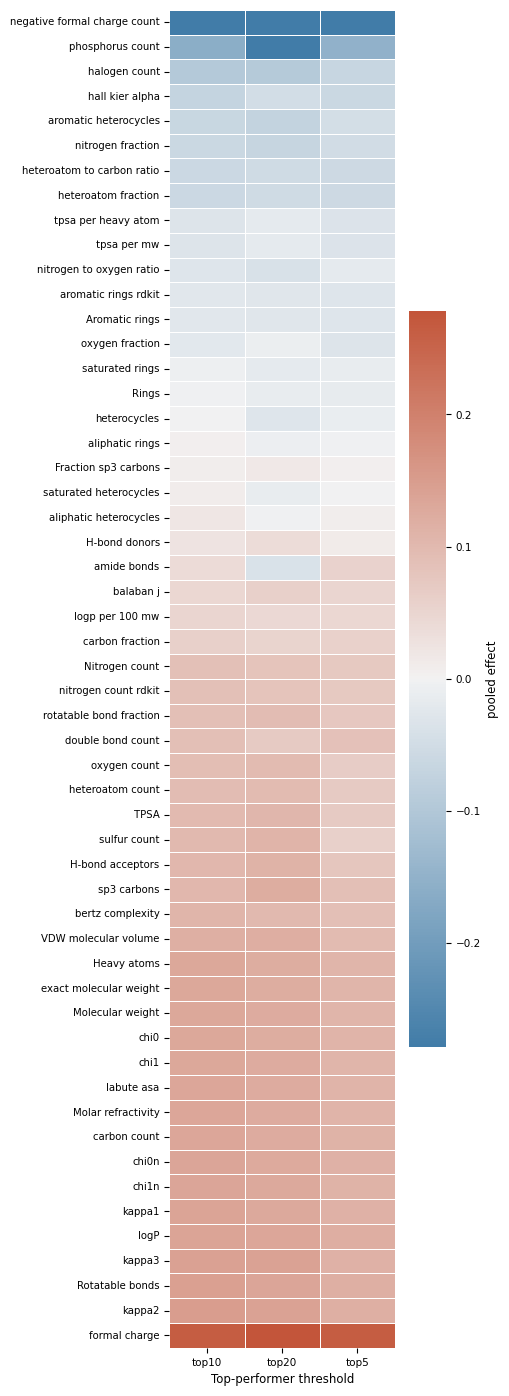

In [ ]:
sensitivity_rows = []
for flag in ["top5_flag", "top10_flag", "top20_flag"]:
    _, meta_flag = meta_analyze_continuous_effects(screen_lnp_table, molecular_descriptors, flag_col=flag)
    if meta_flag.empty:
        continue
    tmp = meta_flag[["feature", "pooled_effect", "n_screens", "q_value"]].copy()
    tmp["threshold"] = flag.replace("_flag", "")
    sensitivity_rows.append(tmp)
sensitivity_meta = pd.concat(sensitivity_rows, ignore_index=True) if sensitivity_rows else pd.DataFrame()
save_source(sensitivity_meta, "SuppFig4_top_threshold_sensitivity_source")

heat = sensitivity_meta.pivot(index="feature", columns="threshold", values="pooled_effect").reindex(index=descriptor_meta.sort_values("pooled_effect")["feature"])
fig, ax = plt.subplots(figsize=(4.7, max(3.4, 0.28 * len(heat) + 1.0)))
vmax = max(0.25, np.nanpercentile(np.abs(heat.values), 98))
sns.heatmap(heat, ax=ax, cmap=sns.diverging_palette(240, 20, as_cmap=True), center=0, vmin=-vmax, vmax=vmax, linewidths=0.5, linecolor="white", cbar_kws={"label": "pooled effect", "shrink": 0.55})
ax.set_xlabel("Top-performer threshold")
ax.set_ylabel("")
ax.set_yticklabels([pretty_feature_name(f) for f in heat.index], rotation=0, fontsize=7.3)
fig.subplots_adjust(left=0.36, right=0.96, top=0.98, bottom=0.15)
save_figure(fig, "Supplementary_Fig4_top_threshold_sensitivity", DIRS["supplementary_figures"])
plt.show()

# Cell 14 — Fig. 3g: Formulation-ratio cross-study meta-analysis

source data -> /content/cross_study_analysis/source_data/Fig3g_formulation_ratio_feature_coverage.csv
Available formulation-ratio columns in screen_lnp_table:
['il_mol_ratio', 'helper_lipid_mol_ratio', 'cholesterol_mol_ratio', 'peg_lipid_mol_ratio', 'il_to_nucleic_acid_mass_ratio', 'il_to_nucleic_acid_charge_ratio', 'total_lipid_to_cargo_ratio']

Retained continuous formulation-ratio features:
['il_mol_ratio', 'helper_lipid_mol_ratio', 'cholesterol_mol_ratio', 'peg_lipid_mol_ratio', 'il_to_nucleic_acid_mass_ratio', 'il_to_nucleic_acid_charge_ratio', 'total_lipid_to_cargo_ratio']


,feature,label,non_missing_screen_lnp_rows,screens_with_value,studies_with_value,unique_numeric_values,retained_for_analysis
0,il_mol_ratio,Ionizable lipid molar ratio,19224,59,45,1950,True
1,helper_lipid_mol_ratio,Helper lipid molar ratio,19136,58,44,1948,True
2,cholesterol_mol_ratio,Cholesterol molar ratio,19136,58,44,1984,True
3,peg_lipid_mol_ratio,PEG-lipid molar ratio,19136,58,44,1943,True
4,il_to_nucleic_acid_mass_ratio,IL:cargo mass ratio,19724,57,44,1712,True
5,il_to_nucleic_acid_charge_ratio,IL:cargo charge ratio,1179,7,5,8,True
6,total_lipid_to_cargo_ratio,Total lipid:cargo ratio,2709,12,9,8,True


source data -> /content/cross_study_analysis/source_data/Fig3g_formulation_ratio_screen_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3g_formulation_ratio_study_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3g_formulation_ratio_meta_analysis_source.csv
saved:
  /content/cross_study_analysis/panels/Fig3g_formulation_ratio_orchard_meta_analysis.pdf
  /content/cross_study_analysis/panels/Fig3g_formulation_ratio_orchard_meta_analysis.svg
  /content/cross_study_analysis/panels/Fig3g_formulation_ratio_orchard_meta_analysis.png


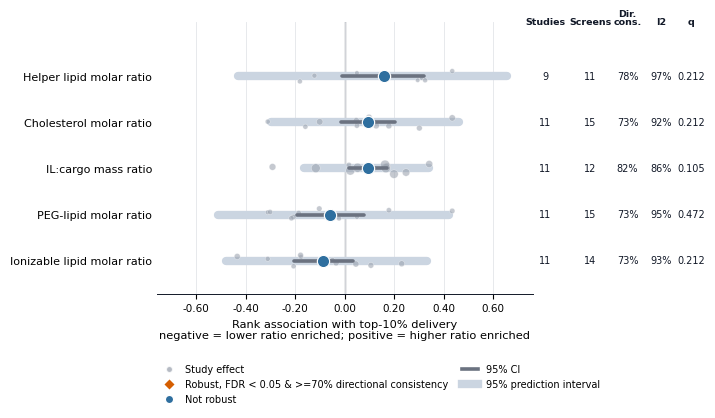

source data -> /content/cross_study_analysis/source_data/Supplementary_formulation_ratio_study_effect_heatmap_source.csv
saved:
  /content/cross_study_analysis/supplementary_figures/Supplementary_formulation_ratio_study_effect_heatmap.pdf
  /content/cross_study_analysis/supplementary_figures/Supplementary_formulation_ratio_study_effect_heatmap.svg
  /content/cross_study_analysis/supplementary_figures/Supplementary_formulation_ratio_study_effect_heatmap.png


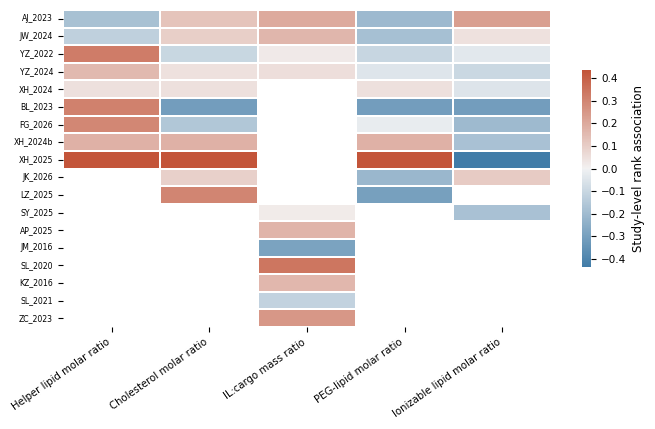

,feature,label,pooled_effect,ci_low,ci_high,prediction_low,prediction_high,n_screens,n_studies,directional_consistency,tau2,i2,p_value,q_value,passes_robustness_rule,association_direction
0,helper_lipid_mol_ratio,Helper lipid molar ratio,0.158761,-0.012828,0.321267,-0.432319,0.654412,11,9,0.777778,0.061598,96.680664,0.069583,0.211665,False,not_robust_or_inconsistent
1,cholesterol_mol_ratio,Cholesterol molar ratio,0.095793,-0.015541,0.204781,-0.295938,0.459941,15,11,0.727273,0.028202,92.022511,0.091583,0.211665,False,not_robust_or_inconsistent
2,il_to_nucleic_acid_mass_ratio,IL:cargo mass ratio,0.094241,0.018389,0.169015,-0.164030,0.340421,12,11,0.818182,0.011706,86.384173,0.014954,0.104681,False,not_robust_or_inconsistent
3,peg_lipid_mol_ratio,PEG-lipid molar ratio,-0.057859,-0.191750,0.078147,-0.510256,0.419619,15,11,0.727273,0.045035,94.850655,0.404636,0.472076,False,not_robust_or_inconsistent
4,il_mol_ratio,Ionizable lipid molar ratio,-0.088511,-0.206252,0.031757,-0.478922,0.331131,14,11,0.727273,0.032831,92.961576,0.148928,0.211665,False,not_robust_or_inconsistent
5,total_lipid_to_cargo_ratio,Total lipid:cargo ratio,-0.091878,-0.392168,0.226109,NaN,NaN,1,1,1.000000,0.000000,0.000000,0.575172,0.575172,False,not_robust_or_inconsistent
6,il_to_nucleic_acid_charge_ratio,IL:cargo charge ratio,-0.100402,-0.233895,0.036807,-0.233895,0.036807,3,2,1.000000,0.000000,0.000000,0.151189,0.211665,False,not_robust_or_inconsistent



Final robustness rule: n_screens >= 5 AND n_studies >= 5 AND q_value < 0.05 AND directional_consistency >= 0.70
Robust positive formulation ratios: None
Robust negative formulation ratios: None
Not robust or inconsistent formulation ratios: Helper lipid molar ratio, Cholesterol molar ratio, IL:cargo mass ratio, PEG-lipid molar ratio, Ionizable lipid molar ratio, Total lipid:cargo ratio, IL:cargo charge ratio


In [ ]:
# ============================================================
# Cell 14 — Fig. 3g: Formulation-ratio cross-study meta-analysis
# Uses the existing screen_lnp_table, top10_flag definition, and
# rank-based within-screen effect framework used above.
# Does not modify the original LNPHub dataframe or screen_lnp_table.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

# ------------------------------------------------------------
# 1. Discover valid formulation-ratio columns from screen_lnp_table
# ------------------------------------------------------------

FORMULATION_RATIO_CANDIDATES = [
    "il_mol_ratio",
    "helper_lipid_mol_ratio",
    "cholesterol_mol_ratio",
    "peg_lipid_mol_ratio",
    "il_to_nucleic_acid_mass_ratio",
    "il_to_nucleic_acid_charge_ratio",
    "total_lipid_to_cargo_ratio",
]

formulation_label_map = {
    "il_mol_ratio": "Ionizable lipid molar ratio",
    "helper_lipid_mol_ratio": "Helper lipid molar ratio",
    "cholesterol_mol_ratio": "Cholesterol molar ratio",
    "peg_lipid_mol_ratio": "PEG-lipid molar ratio",
    "il_to_nucleic_acid_mass_ratio": "IL:cargo mass ratio",
    "il_to_nucleic_acid_charge_ratio": "IL:cargo charge ratio",
    "total_lipid_to_cargo_ratio": "Total lipid:cargo ratio",
}

available_formulation_cols = present_cols(screen_lnp_table, FORMULATION_RATIO_CANDIDATES)

# Add any other clearly formulation/cargo-normalized continuous ratio fields that exist.
extra_ratio_cols = []
for col in screen_lnp_table.columns:
    low = str(col).lower()
    looks_like_ratio = "ratio" in low
    looks_formulation_related = any(
        key in low for key in ["il_", "helper", "cholesterol", "peg", "lipid", "cargo", "nucleic"]
    )
    if looks_like_ratio and looks_formulation_related and col not in available_formulation_cols:
        extra_ratio_cols.append(col)

available_formulation_cols = available_formulation_cols + sorted(extra_ratio_cols)

coverage_rows = []
for feature in available_formulation_cols:
    s = pd.to_numeric(screen_lnp_table[feature], errors="coerce").replace([np.inf, -np.inf], np.nan)
    valid = s.notna()
    coverage_rows.append({
        "feature": feature,
        "label": formulation_label_map.get(feature, pretty_feature_name(feature) if "pretty_feature_name" in globals() else clean_label(feature)),
        "non_missing_screen_lnp_rows": int(valid.sum()),
        "screens_with_value": int(screen_lnp_table.loc[valid, "screen_id"].nunique()),
        "studies_with_value": int(screen_lnp_table.loc[valid, "study_id"].nunique()),
        "unique_numeric_values": int(s[valid].nunique()),
        "retained_for_analysis": bool(valid.sum() >= 6 and s[valid].nunique() >= 2),
    })

formulation_feature_coverage = pd.DataFrame(coverage_rows)
formulation_features = formulation_feature_coverage.loc[
    formulation_feature_coverage["retained_for_analysis"], "feature"
].tolist()

save_source(formulation_feature_coverage, "Fig3g_formulation_ratio_feature_coverage")

print("Available formulation-ratio columns in screen_lnp_table:")
print(available_formulation_cols if available_formulation_cols else "None detected")
print("\nRetained continuous formulation-ratio features:")
print(formulation_features if formulation_features else "None retained")

display(formulation_feature_coverage)

if not formulation_features:
    raise ValueError("No analyzable continuous formulation-ratio features were detected in screen_lnp_table.")

# ------------------------------------------------------------
# 2. Screen-level effects, then collapse multiple screens per study
# ------------------------------------------------------------

def _format_formulation_q(q):
    if pd.isna(q):
        return "NA"
    return "<0.001" if q < 0.001 else f"{q:.3f}"


def _formulation_random_effects_meta(effect, variance):
    effect = np.asarray(effect, dtype=float)
    variance = np.asarray(variance, dtype=float)
    keep = np.isfinite(effect) & np.isfinite(variance) & (variance > 0)
    effect = effect[keep]
    variance = variance[keep]
    k = len(effect)

    empty = {
        "k": 0,
        "pooled": np.nan,
        "ci_low": np.nan,
        "ci_high": np.nan,
        "se": np.nan,
        "p": np.nan,
        "tau2": np.nan,
        "i2": np.nan,
    }
    if k == 0:
        return empty

    if k == 1:
        se = float(np.sqrt(variance[0]))
        z = float(effect[0] / se) if se > 0 else np.nan
        p = float(2 * stats.norm.sf(abs(z))) if np.isfinite(z) else np.nan
        return {
            "k": 1,
            "pooled": float(effect[0]),
            "ci_low": float(effect[0] - 1.96 * se),
            "ci_high": float(effect[0] + 1.96 * se),
            "se": se,
            "p": p,
            "tau2": 0.0,
            "i2": 0.0,
        }

    w = 1.0 / variance
    fixed = np.sum(w * effect) / np.sum(w)
    q_stat = np.sum(w * (effect - fixed) ** 2)
    df_q = k - 1
    c_val = np.sum(w) - np.sum(w ** 2) / np.sum(w)
    tau2 = max(0.0, (q_stat - df_q) / c_val) if c_val > 0 else 0.0

    wr = 1.0 / (variance + tau2)
    pooled = float(np.sum(wr * effect) / np.sum(wr))
    se = float(np.sqrt(1.0 / np.sum(wr)))
    ci_low = float(pooled - 1.96 * se)
    ci_high = float(pooled + 1.96 * se)
    z = pooled / se if se > 0 else np.nan
    p = float(2 * stats.norm.sf(abs(z))) if np.isfinite(z) else np.nan
    i2 = float(max(0.0, (q_stat - df_q) / q_stat) * 100) if q_stat > 0 else 0.0

    return {
        "k": int(k),
        "pooled": pooled,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "se": se,
        "p": p,
        "tau2": float(tau2),
        "i2": i2,
    }


def _formulation_label(feature):
    return formulation_label_map.get(
        feature,
        pretty_feature_name(feature) if "pretty_feature_name" in globals() else clean_label(feature),
    )


def _combine_screen_effects_within_study(screen_effects):
    study_rows = []

    if screen_effects.empty:
        return pd.DataFrame(study_rows)

    for (feature, study_id), sdf in screen_effects.groupby(["feature", "study_id"], dropna=False):
        sdf = sdf.replace([np.inf, -np.inf], np.nan).dropna(subset=["effect_z", "variance_z"]).copy()
        sdf = sdf[sdf["variance_z"] > 0].copy()
        if sdf.empty:
            continue

        weights = 1.0 / sdf["variance_z"].astype(float)
        pooled_z = float(np.sum(weights * sdf["effect_z"].astype(float)) / np.sum(weights))
        pooled_var = float(1.0 / np.sum(weights))

        study_rows.append({
            "feature": feature,
            "study_id": study_id,
            "study_effect_z": pooled_z,
            "study_variance_z": pooled_var,
            "study_effect_r": float(r_from_fisher_z(pooled_z)),
            "study_weight_fixed": float(np.sum(weights)),
            "n_screens": int(sdf["screen_id"].nunique()),
            "n_screen_lnp_rows": int(sdf["n"].sum()),
            "n_top_rows": int(sdf["n_top"].sum()),
            "screen_ids": "; ".join(sorted(sdf["screen_id"].astype(str).unique())),
            "experimental_setting": "; ".join(sorted(sdf["experimental_setting"].dropna().astype(str).unique())),
            "cargo_type": "; ".join(sorted(sdf["cargo_type"].dropna().astype(str).unique())),
        })

    return pd.DataFrame(study_rows)


# Build screen-level effects directly instead of calling meta_analyze_continuous_effects().
# This avoids version-dependent helper output keys in older Colab runtimes.
formulation_screen_rows = []
for feature in formulation_features:
    for screen_id, sdf in screen_lnp_table.groupby("screen_id", dropna=False):
        eff = spearman_screen_effect(sdf, feature, flag_col="top10_flag")
        if eff is None:
            continue

        formulation_screen_rows.append({
            "feature": feature,
            "screen_id": screen_id,
            "study_id": sdf["study_id"].iloc[0],
            "experimental_setting": sdf["experimental_setting"].iloc[0] if "experimental_setting" in sdf.columns else np.nan,
            "cargo_type": sdf["cargo_type"].iloc[0] if "cargo_type" in sdf.columns else np.nan,
            **eff,
        })

formulation_screen_effects = pd.DataFrame(formulation_screen_rows)
formulation_study_effects = _combine_screen_effects_within_study(formulation_screen_effects)

meta_rows = []
for feature, fdf in formulation_study_effects.groupby("feature"):
    meta = _formulation_random_effects_meta(fdf["study_effect_z"], fdf["study_variance_z"])
    n_studies = int(meta.get("k", len(fdf)))
    n_screens = int(formulation_screen_effects.loc[formulation_screen_effects["feature"] == feature, "screen_id"].nunique())

    if np.isfinite(meta["pooled"]):
        pooled_effect = float(r_from_fisher_z(meta["pooled"]))
        ci_low = float(r_from_fisher_z(meta["ci_low"])) if np.isfinite(meta["ci_low"]) else np.nan
        ci_high = float(r_from_fisher_z(meta["ci_high"])) if np.isfinite(meta["ci_high"]) else np.nan

        if n_studies > 1:
            pi_crit = stats.t.ppf(0.975, max(n_studies - 2, 1)) if n_studies > 2 else 1.96
            pi_half_width_z = float(pi_crit * np.sqrt(meta["tau2"] + meta["se"] ** 2))
            pi_low = float(r_from_fisher_z(meta["pooled"] - pi_half_width_z))
            pi_high = float(r_from_fisher_z(meta["pooled"] + pi_half_width_z))
        else:
            pi_low = np.nan
            pi_high = np.nan
    else:
        pooled_effect = ci_low = ci_high = pi_low = pi_high = np.nan

    pooled_sign = np.sign(pooled_effect) if np.isfinite(pooled_effect) else np.nan
    if np.isfinite(pooled_sign) and pooled_sign != 0:
        directional_consistency = float((np.sign(fdf["study_effect_r"]) == pooled_sign).mean())
    else:
        directional_consistency = np.nan

    meta_rows.append({
        "feature": feature,
        "label": _formulation_label(feature),
        "pooled_z": meta["pooled"],
        "pooled_effect": pooled_effect,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "prediction_low": pi_low,
        "prediction_high": pi_high,
        "n_screens": n_screens,
        "n_studies": n_studies,
        "directional_consistency": directional_consistency,
        "tau2": meta["tau2"],
        "i2": meta["i2"],
        "p_value": meta["p"],
    })

formulation_meta = pd.DataFrame(meta_rows)
if not formulation_meta.empty:
    formulation_meta["q_value"] = bh_fdr(formulation_meta["p_value"])
    formulation_meta["passes_robustness_rule"] = (
        (formulation_meta["n_screens"] >= 5)
        & (formulation_meta["n_studies"] >= 5)
        & (formulation_meta["q_value"] < 0.05)
        & (formulation_meta["directional_consistency"] >= 0.70)
    )
    formulation_meta["association_direction"] = np.select(
        [
            formulation_meta["passes_robustness_rule"] & (formulation_meta["pooled_effect"] > 0),
            formulation_meta["passes_robustness_rule"] & (formulation_meta["pooled_effect"] < 0),
        ],
        ["robust_positive", "robust_negative"],
        default="not_robust_or_inconsistent",
    )
    formulation_meta = formulation_meta.sort_values("pooled_effect", ascending=False).reset_index(drop=True)

save_source(formulation_screen_effects, "Fig3g_formulation_ratio_screen_effects_source")
save_source(formulation_study_effects, "Fig3g_formulation_ratio_study_effects_source")
save_source(formulation_meta, "Fig3g_formulation_ratio_meta_analysis_source")

# ------------------------------------------------------------
# 3. Main-text orchard/meta-analysis plot
# ------------------------------------------------------------

plot_meta = formulation_meta.copy()
plot_meta = plot_meta[np.isfinite(plot_meta["pooled_effect"])].copy()

# Main figure display filter: keep formulation ratios supported by at least 5 studies.
# The complete meta-analysis source table remains saved above.
MIN_FORMULATION_STUDIES_FOR_DISPLAY = 5
plot_meta = plot_meta[plot_meta["n_studies"] >= MIN_FORMULATION_STUDIES_FOR_DISPLAY].copy()
plot_meta = plot_meta.sort_values("pooled_effect", ascending=False).reset_index(drop=True)

fig_h = max(3.2, 0.48 * len(plot_meta) + 1.35)
fig = plt.figure(figsize=(8.0, fig_h))
gs = gridspec.GridSpec(1, 2, width_ratios=[5.25, 2.35], wspace=0.015)
ax = fig.add_subplot(gs[0, 0])
ax_tab = fig.add_subplot(gs[0, 1], sharey=ax)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax_tab.set_facecolor("white")

robust_color = "#D55E00"
neutral_color = "#2F6F9F"
study_point_color = "#9CA3AF"
pi_color = "#CBD5E1"
ci_neutral = "#6B7280"

if plot_meta.empty:
    ax.axis("off")
    ax_tab.axis("off")
    ax.text(0.5, 0.5, "No analyzable formulation-ratio associations", ha="center", va="center")
else:
    y_positions = np.arange(len(plot_meta))
    feature_to_y = dict(zip(plot_meta["feature"], y_positions))

    study_plot = formulation_study_effects.merge(
        plot_meta[["feature", "tau2"]], on="feature", how="inner"
    ).copy()
    study_plot["y"] = study_plot["feature"].map(feature_to_y)
    study_plot["random_weight"] = 1.0 / (study_plot["study_variance_z"] + study_plot["tau2"].fillna(0.0))

    rng = np.random.default_rng(RANDOM_SEED)
    study_plot["y_jitter"] = study_plot["y"] + rng.uniform(-0.13, 0.13, size=len(study_plot))

    if len(study_plot):
        w = study_plot["random_weight"].replace([np.inf, -np.inf], np.nan)
        if w.notna().any() and w.max() > w.min():
            study_sizes = 10 + 34 * (w - w.min()) / (w.max() - w.min())
        else:
            study_sizes = pd.Series(18, index=study_plot.index)

        ax.scatter(
            study_plot["study_effect_r"],
            study_plot["y_jitter"],
            s=study_sizes,
            color=study_point_color,
            alpha=0.58,
            edgecolor="white",
            linewidth=0.35,
            zorder=2,
        )

    for _, row in plot_meta.iterrows():
        y = feature_to_y[row["feature"]]
        robust = bool(row["passes_robustness_rule"])
        color = robust_color if robust else neutral_color
        ci_color = robust_color if robust else ci_neutral

        if np.isfinite(row["prediction_low"]) and np.isfinite(row["prediction_high"]):
            ax.plot(
                [row["prediction_low"], row["prediction_high"]],
                [y, y],
                color=pi_color,
                lw=6.0,
                solid_capstyle="round",
                zorder=1,
            )

        ax.plot(
            [row["ci_low"], row["ci_high"]],
            [y, y],
            color=ci_color,
            lw=2.6,
            solid_capstyle="round",
            zorder=3,
        )

        ax.scatter(
            row["pooled_effect"],
            y,
            s=78,
            marker="D" if robust else "o",
            color=color,
            edgecolor="white",
            linewidth=0.85,
            zorder=4,
        )

    xmax_candidates = pd.concat([
        plot_meta["ci_low"], plot_meta["ci_high"],
        plot_meta["prediction_low"], plot_meta["prediction_high"],
        formulation_study_effects["study_effect_r"] if "study_effect_r" in formulation_study_effects else pd.Series(dtype=float),
    ]).replace([np.inf, -np.inf], np.nan).dropna()
    x_abs = max(0.15, float(np.nanmax(np.abs(xmax_candidates))) if len(xmax_candidates) else 0.15)
    x_lim = min(0.99, x_abs * 1.16)

    ax.axvline(0, color="#111827", lw=0.85, zorder=0)
    ax.set_xlim(-x_lim, x_lim)
    ax.set_ylim(-1.18, len(plot_meta) - 0.28)
    ax.invert_yaxis()
    ax.set_yticks(y_positions)
    ax.set_yticklabels(plot_meta["label"], fontsize=8.0)
    ax.set_xlabel(
        "Rank association with top-10% delivery\nnegative = lower ratio enriched; positive = higher ratio enriched",
        fontsize=8.2,
    )
    ax.grid(axis="x", color="#E5E7EB", lw=0.65)
    ax.set_axisbelow(True)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.2f}"))

    ax_tab.set_xlim(0, 1)
    ax_tab.set_ylim(ax.get_ylim())
    ax_tab.axis("off")

    table_x = {
        "studies": 0.05,
        "screens": 0.32,
        "consistency": 0.54,
        "i2": 0.74,
        "q": 0.92,
    }
    header_y = -1.08

    ax_tab.text(table_x["studies"], header_y, "Studies", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"])
    ax_tab.text(table_x["screens"], header_y, "Screens", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"])
    ax_tab.text(table_x["consistency"], header_y, "Dir.\ncons.", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"], linespacing=0.90)
    ax_tab.text(table_x["i2"], header_y, "I2", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"])
    ax_tab.text(table_x["q"], header_y, "q", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"])

    for _, row in plot_meta.iterrows():
        y = feature_to_y[row["feature"]]
        robust = bool(row["passes_robustness_rule"])
        row_color = robust_color if robust else COLORS["ink"]
        weight = "bold" if robust else "normal"

        ax_tab.text(table_x["studies"], y, f"{int(row['n_studies']):,}", ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
        ax_tab.text(table_x["screens"], y, f"{int(row['n_screens']):,}", ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
        ax_tab.text(table_x["consistency"], y, f"{row['directional_consistency'] * 100:.0f}%" if pd.notna(row["directional_consistency"]) else "NA", ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
        ax_tab.text(table_x["i2"], y, f"{row['i2']:.0f}%" if pd.notna(row["i2"]) else "NA", ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
        ax_tab.text(table_x["q"], y, _format_formulation_q(row["q_value"]), ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)

    legend_handles = [
        Line2D([0], [0], marker="o", linestyle="none", color="none", markerfacecolor=study_point_color, markeredgecolor="white", markersize=4.5, alpha=0.75, label="Study effect"),
        Line2D([0], [0], marker="D", linestyle="none", color="none", markerfacecolor=robust_color, markeredgecolor="white", markersize=6.0, label="Robust, FDR < 0.05 & >=70% directional consistency"),
        Line2D([0], [0], marker="o", linestyle="none", color="none", markerfacecolor=neutral_color, markeredgecolor="white", markersize=6.0, label="Not robust"),
        Line2D([0], [0], color=ci_neutral, lw=2.6, label="95% CI"),
        Line2D([0], [0], color=pi_color, lw=6.0, label="95% prediction interval"),
    ]
    ax.legend(
        handles=legend_handles,
        loc="lower left",
        bbox_to_anchor=(0.0, -0.2),
        frameon=False,
        ncol=2,
        handlelength=1.7,
        columnspacing=1.4,
        borderaxespad=0,
        fontsize=7.0,
    )

fig.subplots_adjust(left=0.30, right=0.985, top=0.965, bottom=0.24)
save_figure(fig, "Fig3g_formulation_ratio_orchard_meta_analysis", DIRS["panels"])
plt.show()

# ------------------------------------------------------------
# 4. Supplementary study-by-formulation-variable heatmap
# ------------------------------------------------------------

if not formulation_study_effects.empty:
    heatmap_source = formulation_study_effects.copy()
    heatmap_source = heatmap_source.merge(
        formulation_meta[["feature", "label", "pooled_effect", "q_value", "passes_robustness_rule"]],
        on="feature",
        how="left",
    )
    save_source(heatmap_source, "Supplementary_formulation_ratio_study_effect_heatmap_source")

    heatmap_cols = plot_meta["feature"].tolist() if len(plot_meta) else formulation_features
    heat = (
        formulation_study_effects
        .pivot(index="study_id", columns="feature", values="study_effect_r")
        .reindex(columns=heatmap_cols)
    )
    heat = heat.loc[heat.notna().sum(axis=1).sort_values(ascending=False).index]

    vmax = max(0.20, float(np.nanpercentile(np.abs(heat.values), 95))) if np.isfinite(heat.values).any() else 0.5
    vmax = min(0.95, vmax)

    fig_hm, ax_hm = plt.subplots(figsize=(7.4, max(4.2, 0.105 * len(heat) + 1.45)))
    fig_hm.patch.set_facecolor("white")
    ax_hm.set_facecolor("white")

    sns.heatmap(
        heat,
        ax=ax_hm,
        cmap=sns.diverging_palette(240, 20, as_cmap=True),
        center=0,
        vmin=-vmax,
        vmax=vmax,
        linewidths=0.22,
        linecolor="white",
        cbar_kws={"label": "Study-level rank association", "shrink": 0.62},
    )
    ax_hm.set_xlabel("")
    ax_hm.set_ylabel("")
    ax_hm.set_xticklabels([_formulation_label(c) for c in heat.columns], rotation=35, ha="right", fontsize=7.3)
    ax_hm.set_yticklabels([str(s).replace("LNPhub_", "") for s in heat.index], fontsize=5.6)
    for spine in ["top", "right", "left", "bottom"]:
        ax_hm.spines[spine].set_visible(False)
    fig_hm.subplots_adjust(left=0.16, right=0.985, top=0.985, bottom=0.23)
    save_figure(fig_hm, "Supplementary_formulation_ratio_study_effect_heatmap", DIRS["supplementary_figures"])
    plt.show()

# ------------------------------------------------------------
# 5. Report full table and concise interpretation
# ------------------------------------------------------------

report_cols = [
    "feature", "label", "pooled_effect", "ci_low", "ci_high",
    "prediction_low", "prediction_high", "n_screens", "n_studies",
    "directional_consistency", "tau2", "i2", "p_value", "q_value",
    "passes_robustness_rule", "association_direction",
]

formulation_meta_report = formulation_meta[report_cols].copy()
display(formulation_meta_report)

robust_pos = formulation_meta_report[
    (formulation_meta_report["passes_robustness_rule"]) &
    (formulation_meta_report["pooled_effect"] > 0)
]
robust_neg = formulation_meta_report[
    (formulation_meta_report["passes_robustness_rule"]) &
    (formulation_meta_report["pooled_effect"] < 0)
]
inconsistent = formulation_meta_report[~formulation_meta_report["passes_robustness_rule"]]

print("\nFinal robustness rule: n_screens >= 5 AND n_studies >= 5 AND q_value < 0.05 AND directional_consistency >= 0.70")
print("Robust positive formulation ratios:", ", ".join(robust_pos["label"].tolist()) if len(robust_pos) else "None")
print("Robust negative formulation ratios:", ", ".join(robust_neg["label"].tolist()) if len(robust_neg) else "None")
print("Not robust or inconsistent formulation ratios:", ", ".join(inconsistent["label"].tolist()) if len(inconsistent) else "None")










source data -> /content/cross_study_analysis/source_data/Fig3g_formulation_ratio_in_vitro_meta_analysis_feature_coverage.csv
source data -> /content/cross_study_analysis/source_data/Fig3g_formulation_ratio_in_vitro_meta_analysis_screen_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3g_formulation_ratio_in_vitro_meta_analysis_study_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3g_formulation_ratio_in_vitro_meta_analysis_meta_analysis_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_formulation_ratio_in_vivo_meta_analysis_feature_coverage.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_formulation_ratio_in_vivo_meta_analysis_screen_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_formulation_ratio_in_vivo_meta_analysis_study_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_formulation_ratio_in_vivo_meta_analysis_met

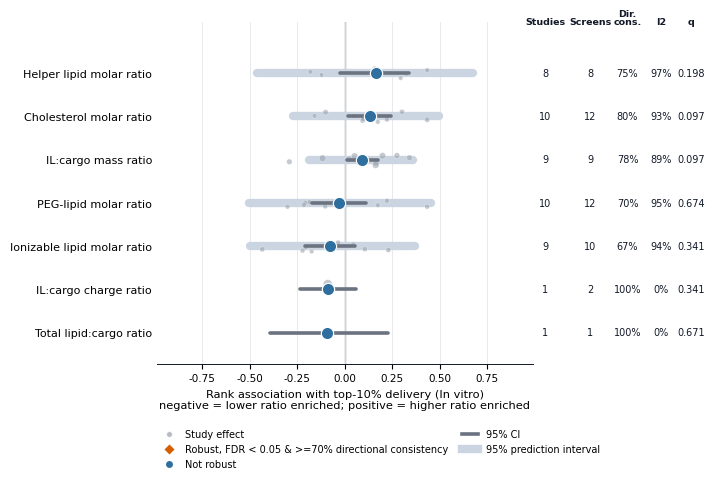

saved:
  /content/cross_study_analysis/panels/Fig3h_formulation_ratio_in_vivo_meta_analysis.pdf
  /content/cross_study_analysis/panels/Fig3h_formulation_ratio_in_vivo_meta_analysis.svg
  /content/cross_study_analysis/panels/Fig3h_formulation_ratio_in_vivo_meta_analysis.png


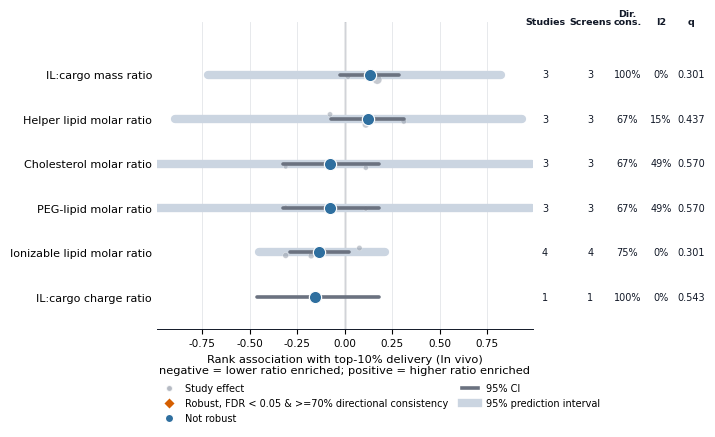

Final robustness rule: n_screens >= 5 AND n_studies >= 5 AND q_value < 0.05 AND directional_consistency >= 0.70

In vitro complete formulation-ratio meta-analysis


,experimental_setting_filter,feature,label,pooled_effect,ci_low,ci_high,prediction_low,prediction_high,n_screens,n_studies,directional_consistency,tau2,i2,p_value,q_value,passes_robustness_rule,association_direction
0,in_vitro,helper_lipid_mol_ratio,Helper lipid molar ratio,0.162463,-0.022455,0.336632,-0.459897,0.677788,8,8,0.750000,0.063953,97.082917,0.084741,0.197730,False,not_robust_or_inconsistent
1,in_vitro,cholesterol_mol_ratio,Cholesterol molar ratio,0.131249,0.015250,0.243762,-0.272092,0.495363,12,10,0.800000,0.028238,92.537856,0.026691,0.097012,False,not_robust_or_inconsistent
2,in_vitro,il_to_nucleic_acid_mass_ratio,IL:cargo mass ratio,0.092489,0.010165,0.173568,-0.186530,0.357702,9,9,0.777778,0.012396,89.046105,0.027718,0.097012,False,not_robust_or_inconsistent
3,in_vitro,peg_lipid_mol_ratio,PEG-lipid molar ratio,-0.030990,-0.173484,0.112775,-0.504177,0.456509,12,10,0.700000,0.046196,95.302466,0.673616,0.673616,False,not_robust_or_inconsistent
4,in_vitro,il_mol_ratio,Ionizable lipid molar ratio,-0.078939,-0.209016,0.053883,-0.497068,0.368942,10,9,0.666667,0.034280,94.277690,0.243859,0.341403,False,not_robust_or_inconsistent
5,in_vitro,il_to_nucleic_acid_charge_ratio,IL:cargo charge ratio,-0.089253,-0.235322,0.060759,NaN,NaN,2,1,1.000000,0.000000,0.000000,0.243282,0.341403,False,not_robust_or_inconsistent
6,in_vitro,total_lipid_to_cargo_ratio,Total lipid:cargo ratio,-0.091878,-0.392168,0.226109,NaN,NaN,1,1,1.000000,0.000000,0.000000,0.575172,0.671035,False,not_robust_or_inconsistent


In vitro robust positive formulation ratios: None
In vitro robust negative formulation ratios: None
In vitro not robust or inconsistent formulation ratios: Helper lipid molar ratio, Cholesterol molar ratio, IL:cargo mass ratio, PEG-lipid molar ratio, Ionizable lipid molar ratio, IL:cargo charge ratio, Total lipid:cargo ratio

In vivo complete formulation-ratio meta-analysis


,experimental_setting_filter,feature,label,pooled_effect,ci_low,ci_high,prediction_low,prediction_high,n_screens,n_studies,directional_consistency,tau2,i2,p_value,q_value,passes_robustness_rule,association_direction
0,in_vivo,il_to_nucleic_acid_mass_ratio,IL:cargo mass ratio,0.133806,-0.025950,0.286898,-0.719361,0.826042,3,3,1.000000,0.000000,0.000000,0.100348,0.301045,False,not_robust_or_inconsistent
1,in_vivo,helper_lipid_mol_ratio,Helper lipid molar ratio,0.124417,-0.074071,0.313423,-0.894154,0.934452,3,3,0.666667,0.004879,15.163063,0.218655,0.437311,False,not_robust_or_inconsistent
2,in_vivo,cholesterol_mol_ratio,Cholesterol molar ratio,-0.075455,-0.324104,0.182945,-0.991503,0.988520,3,3,0.666667,0.025910,48.695676,0.569675,0.569675,False,not_robust_or_inconsistent
3,in_vivo,peg_lipid_mol_ratio,PEG-lipid molar ratio,-0.075455,-0.324104,0.182945,-0.991503,0.988520,3,3,0.666667,0.025910,48.695676,0.569675,0.569675,False,not_robust_or_inconsistent
4,in_vivo,il_mol_ratio,Ionizable lipid molar ratio,-0.136273,-0.288711,0.022903,-0.452974,0.210968,4,4,0.750000,0.000000,0.000000,0.093066,0.301045,False,not_robust_or_inconsistent
5,in_vivo,il_to_nucleic_acid_charge_ratio,IL:cargo charge ratio,-0.157378,-0.462030,0.180496,NaN,NaN,1,1,1.000000,0.000000,0.000000,0.361956,0.542934,False,not_robust_or_inconsistent


In vivo robust positive formulation ratios: None
In vivo robust negative formulation ratios: None
In vivo not robust or inconsistent formulation ratios: IL:cargo mass ratio, Helper lipid molar ratio, Cholesterol molar ratio, PEG-lipid molar ratio, Ionizable lipid molar ratio, IL:cargo charge ratio


In [ ]:


# ============================================================
# Cell 15 — Setting-specific formulation-ratio meta-analysis
# Generates two additional orchard/meta-analysis panels using the
# same formulation-ratio methodology as Cell 14:
#   1. in vitro only
#   2. in vivo only
# Does not modify screen_lnp_table or the original LNPHub dataframe.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

# ------------------------------------------------------------
# 1. Shared formulation-ratio feature set
# ------------------------------------------------------------

FORMULATION_RATIO_CANDIDATES_CELL15 = [
    "il_mol_ratio",
    "helper_lipid_mol_ratio",
    "cholesterol_mol_ratio",
    "peg_lipid_mol_ratio",
    "il_to_nucleic_acid_mass_ratio",
    "il_to_nucleic_acid_charge_ratio",
    "total_lipid_to_cargo_ratio",
]

formulation_label_map_cell15 = {
    "il_mol_ratio": "Ionizable lipid molar ratio",
    "helper_lipid_mol_ratio": "Helper lipid molar ratio",
    "cholesterol_mol_ratio": "Cholesterol molar ratio",
    "peg_lipid_mol_ratio": "PEG-lipid molar ratio",
    "il_to_nucleic_acid_mass_ratio": "IL:cargo mass ratio",
    "il_to_nucleic_acid_charge_ratio": "IL:cargo charge ratio",
    "total_lipid_to_cargo_ratio": "Total lipid:cargo ratio",
}

formulation_features_cell15 = present_cols(screen_lnp_table, FORMULATION_RATIO_CANDIDATES_CELL15)

if not formulation_features_cell15:
    raise ValueError("No formulation-ratio features detected in screen_lnp_table.")

# ------------------------------------------------------------
# 2. Local helpers to avoid dependency on older notebook helper schemas
# ------------------------------------------------------------

def _cell15_label(feature):
    return formulation_label_map_cell15.get(
        feature,
        pretty_feature_name(feature) if "pretty_feature_name" in globals() else clean_label(feature),
    )


def _cell15_format_q(q):
    if pd.isna(q):
        return "NA"
    return "<0.001" if q < 0.001 else f"{q:.3f}"


def _cell15_bh_fdr(p_values):
    p = np.asarray(p_values, dtype=float)
    q = np.full_like(p, np.nan, dtype=float)
    valid = np.isfinite(p)
    if valid.sum() == 0:
        return q
    pv = p[valid]
    order = np.argsort(pv)
    ranks = np.arange(1, len(pv) + 1)
    q_sorted = pv[order] * len(pv) / ranks
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]
    q_valid = np.empty_like(pv)
    q_valid[order] = np.minimum(q_sorted, 1.0)
    q[valid] = q_valid
    return q


def _cell15_fisher_z_from_r(r):
    r = np.clip(float(r), -0.999999, 0.999999)
    return np.arctanh(r)


def _cell15_r_from_fisher_z(z):
    return np.tanh(z)


def _cell15_spearman_screen_effect(data, feature, flag_col="top10_flag", min_each=2):
    d = data[[feature, flag_col]].copy()
    d[feature] = pd.to_numeric(d[feature], errors="coerce")
    d = d.replace([np.inf, -np.inf], np.nan).dropna()

    if len(d) < 6 or d[feature].nunique() < 2 or d[flag_col].nunique() < 2:
        return None

    n_top = int(d[flag_col].sum())
    n_non = int(len(d) - n_top)
    if n_top < min_each or n_non < min_each:
        return None

    rho, p = stats.spearmanr(d[feature], d[flag_col])
    if not np.isfinite(rho):
        return None

    variance = 1.0 / max(len(d) - 3, 1)
    return {
        "effect_r": float(rho),
        "effect_z": float(_cell15_fisher_z_from_r(rho)),
        "variance_z": float(variance),
        "p_screen": float(p) if np.isfinite(p) else np.nan,
        "n": int(len(d)),
        "n_top": n_top,
        "n_non_top": n_non,
    }


def _cell15_random_effects_meta(effect, variance):
    effect = np.asarray(effect, dtype=float)
    variance = np.asarray(variance, dtype=float)
    keep = np.isfinite(effect) & np.isfinite(variance) & (variance > 0)
    effect = effect[keep]
    variance = variance[keep]
    k = len(effect)

    if k == 0:
        return {
            "k": 0,
            "pooled": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "se": np.nan,
            "p": np.nan,
            "tau2": np.nan,
            "i2": np.nan,
        }

    if k == 1:
        se = float(np.sqrt(variance[0]))
        z = float(effect[0] / se) if se > 0 else np.nan
        p = float(2 * stats.norm.sf(abs(z))) if np.isfinite(z) else np.nan
        return {
            "k": 1,
            "pooled": float(effect[0]),
            "ci_low": float(effect[0] - 1.96 * se),
            "ci_high": float(effect[0] + 1.96 * se),
            "se": se,
            "p": p,
            "tau2": 0.0,
            "i2": 0.0,
        }

    w = 1.0 / variance
    fixed = np.sum(w * effect) / np.sum(w)
    q_stat = np.sum(w * (effect - fixed) ** 2)
    df_q = k - 1
    c_val = np.sum(w) - np.sum(w ** 2) / np.sum(w)
    tau2 = max(0.0, (q_stat - df_q) / c_val) if c_val > 0 else 0.0

    wr = 1.0 / (variance + tau2)
    pooled = float(np.sum(wr * effect) / np.sum(wr))
    se = float(np.sqrt(1.0 / np.sum(wr)))
    ci_low = float(pooled - 1.96 * se)
    ci_high = float(pooled + 1.96 * se)
    z = pooled / se if se > 0 else np.nan
    p = float(2 * stats.norm.sf(abs(z))) if np.isfinite(z) else np.nan
    i2 = float(max(0.0, (q_stat - df_q) / q_stat) * 100) if q_stat > 0 else 0.0

    return {
        "k": int(k),
        "pooled": pooled,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "se": se,
        "p": p,
        "tau2": float(tau2),
        "i2": i2,
    }


def _cell15_combine_screen_effects_within_study(screen_effects):
    study_rows = []

    if screen_effects.empty:
        return pd.DataFrame(study_rows)

    for (feature, study_id), sdf in screen_effects.groupby(["feature", "study_id"], dropna=False):
        sdf = sdf.replace([np.inf, -np.inf], np.nan).dropna(subset=["effect_z", "variance_z"]).copy()
        sdf = sdf[sdf["variance_z"] > 0].copy()
        if sdf.empty:
            continue

        weights = 1.0 / sdf["variance_z"].astype(float)
        pooled_z = float(np.sum(weights * sdf["effect_z"].astype(float)) / np.sum(weights))
        pooled_var = float(1.0 / np.sum(weights))

        study_rows.append({
            "feature": feature,
            "study_id": study_id,
            "study_effect_z": pooled_z,
            "study_variance_z": pooled_var,
            "study_effect_r": float(_cell15_r_from_fisher_z(pooled_z)),
            "study_weight_fixed": float(np.sum(weights)),
            "n_screens": int(sdf["screen_id"].nunique()),
            "n_screen_lnp_rows": int(sdf["n"].sum()),
            "n_top_rows": int(sdf["n_top"].sum()),
            "screen_ids": "; ".join(sorted(sdf["screen_id"].astype(str).unique())),
            "experimental_setting": "; ".join(sorted(sdf["experimental_setting"].dropna().astype(str).unique())) if "experimental_setting" in sdf.columns else "",
            "cargo_type": "; ".join(sorted(sdf["cargo_type"].dropna().astype(str).unique())) if "cargo_type" in sdf.columns else "",
        })

    return pd.DataFrame(study_rows)


def _cell15_analyze_setting(setting_value, figure_name):
    setting_mask = screen_lnp_table["experimental_setting"].astype(str).str.strip().str.lower().eq(setting_value)
    setting_data = screen_lnp_table.loc[setting_mask].copy()

    coverage_rows = []
    for feature in formulation_features_cell15:
        s = pd.to_numeric(setting_data[feature], errors="coerce").replace([np.inf, -np.inf], np.nan)
        valid = s.notna()
        coverage_rows.append({
            "experimental_setting": setting_value,
            "feature": feature,
            "label": _cell15_label(feature),
            "non_missing_screen_lnp_rows": int(valid.sum()),
            "screens_with_value": int(setting_data.loc[valid, "screen_id"].nunique()) if len(setting_data) else 0,
            "studies_with_value": int(setting_data.loc[valid, "study_id"].nunique()) if len(setting_data) else 0,
            "unique_numeric_values": int(s[valid].nunique()),
            "retained_for_analysis": bool(valid.sum() >= 6 and s[valid].nunique() >= 2),
        })

    feature_coverage = pd.DataFrame(coverage_rows)
    retained_features = feature_coverage.loc[feature_coverage["retained_for_analysis"], "feature"].tolist()

    screen_rows = []
    for feature in retained_features:
        for screen_id, sdf in setting_data.groupby("screen_id", dropna=False):
            eff = _cell15_spearman_screen_effect(sdf, feature, flag_col="top10_flag")
            if eff is None:
                continue

            screen_rows.append({
                "experimental_setting_filter": setting_value,
                "feature": feature,
                "screen_id": screen_id,
                "study_id": sdf["study_id"].iloc[0],
                "experimental_setting": sdf["experimental_setting"].iloc[0] if "experimental_setting" in sdf.columns else np.nan,
                "cargo_type": sdf["cargo_type"].iloc[0] if "cargo_type" in sdf.columns else np.nan,
                **eff,
            })

    screen_effects = pd.DataFrame(screen_rows)
    study_effects = _cell15_combine_screen_effects_within_study(screen_effects)

    meta_rows = []
    if not study_effects.empty:
        for feature, fdf in study_effects.groupby("feature"):
            meta = _cell15_random_effects_meta(fdf["study_effect_z"], fdf["study_variance_z"])
            n_studies = int(meta.get("k", len(fdf)))
            n_screens = int(screen_effects.loc[screen_effects["feature"] == feature, "screen_id"].nunique())

            if np.isfinite(meta["pooled"]):
                pooled_effect = float(_cell15_r_from_fisher_z(meta["pooled"]))
                ci_low = float(_cell15_r_from_fisher_z(meta["ci_low"])) if np.isfinite(meta["ci_low"]) else np.nan
                ci_high = float(_cell15_r_from_fisher_z(meta["ci_high"])) if np.isfinite(meta["ci_high"]) else np.nan

                if n_studies > 1:
                    pi_crit = stats.t.ppf(0.975, max(n_studies - 2, 1)) if n_studies > 2 else 1.96
                    pi_half_width_z = float(pi_crit * np.sqrt(meta["tau2"] + meta["se"] ** 2))
                    prediction_low = float(_cell15_r_from_fisher_z(meta["pooled"] - pi_half_width_z))
                    prediction_high = float(_cell15_r_from_fisher_z(meta["pooled"] + pi_half_width_z))
                else:
                    prediction_low = np.nan
                    prediction_high = np.nan
            else:
                pooled_effect = ci_low = ci_high = prediction_low = prediction_high = np.nan

            pooled_sign = np.sign(pooled_effect) if np.isfinite(pooled_effect) else np.nan
            if np.isfinite(pooled_sign) and pooled_sign != 0:
                directional_consistency = float((np.sign(fdf["study_effect_r"]) == pooled_sign).mean())
            else:
                directional_consistency = np.nan

            meta_rows.append({
                "experimental_setting_filter": setting_value,
                "feature": feature,
                "label": _cell15_label(feature),
                "pooled_z": meta["pooled"],
                "pooled_effect": pooled_effect,
                "ci_low": ci_low,
                "ci_high": ci_high,
                "prediction_low": prediction_low,
                "prediction_high": prediction_high,
                "n_screens": n_screens,
                "n_studies": n_studies,
                "directional_consistency": directional_consistency,
                "tau2": meta["tau2"],
                "i2": meta["i2"],
                "p_value": meta["p"],
            })

    meta_analysis = pd.DataFrame(meta_rows)
    if not meta_analysis.empty:
        meta_analysis["q_value"] = _cell15_bh_fdr(meta_analysis["p_value"])
        meta_analysis["passes_robustness_rule"] = (
            (meta_analysis["n_screens"] >= 5)
            & (meta_analysis["n_studies"] >= 5)
            & (meta_analysis["q_value"] < 0.05)
            & (meta_analysis["directional_consistency"] >= 0.70)
        )
        meta_analysis["association_direction"] = np.select(
            [
                meta_analysis["passes_robustness_rule"] & (meta_analysis["pooled_effect"] > 0),
                meta_analysis["passes_robustness_rule"] & (meta_analysis["pooled_effect"] < 0),
            ],
            ["robust_positive", "robust_negative"],
            default="not_robust_or_inconsistent",
        )
        meta_analysis = meta_analysis.sort_values("pooled_effect", ascending=False).reset_index(drop=True)
    else:
        meta_analysis = pd.DataFrame(columns=[
            "experimental_setting_filter", "feature", "label", "pooled_z", "pooled_effect",
            "ci_low", "ci_high", "prediction_low", "prediction_high", "n_screens",
            "n_studies", "directional_consistency", "tau2", "i2", "p_value", "q_value",
            "passes_robustness_rule", "association_direction",
        ])

    save_source(feature_coverage, f"{figure_name}_feature_coverage")
    save_source(screen_effects, f"{figure_name}_screen_effects_source")
    save_source(study_effects, f"{figure_name}_study_effects_source")
    save_source(meta_analysis, f"{figure_name}_meta_analysis_source")

    return {
        "setting_value": setting_value,
        "figure_name": figure_name,
        "display_label": "In vitro" if setting_value == "in_vitro" else "In vivo",
        "data": setting_data,
        "coverage": feature_coverage,
        "screen_effects": screen_effects,
        "study_effects": study_effects,
        "meta": meta_analysis,
    }

# ------------------------------------------------------------
# 3. Run both setting-specific analyses first so axis scale is shared
# ------------------------------------------------------------

setting_results = OrderedDict([
    ("in_vitro", _cell15_analyze_setting("in_vitro", "Fig3g_formulation_ratio_in_vitro_meta_analysis")),
    ("in_vivo", _cell15_analyze_setting("in_vivo", "Fig3h_formulation_ratio_in_vivo_meta_analysis")),
])

x_candidates = []
for result in setting_results.values():
    meta = result["meta"]
    studies = result["study_effects"]
    if not meta.empty:
        x_candidates.extend(meta["ci_low"].tolist())
        x_candidates.extend(meta["ci_high"].tolist())
        x_candidates.extend(meta["prediction_low"].tolist())
        x_candidates.extend(meta["prediction_high"].tolist())
    if not studies.empty:
        x_candidates.extend(studies["study_effect_r"].tolist())

x_candidates = pd.Series(x_candidates, dtype=float).replace([np.inf, -np.inf], np.nan).dropna()
shared_x_abs = max(0.15, float(np.nanmax(np.abs(x_candidates))) if len(x_candidates) else 0.15)
shared_x_lim = min(0.99, shared_x_abs * 1.16)
shared_xlim = (-shared_x_lim, shared_x_lim)

# ------------------------------------------------------------
# 4. Draw one orchard/meta-analysis figure per setting
# ------------------------------------------------------------

def _cell15_draw_orchard(result, shared_xlim):
    plot_meta = result["meta"].copy()
    plot_meta = plot_meta[np.isfinite(plot_meta["pooled_effect"])].copy()
    plot_meta = plot_meta.sort_values("pooled_effect", ascending=False).reset_index(drop=True)

    study_effects = result["study_effects"].copy()
    fig_h = max(3.2, 0.48 * len(plot_meta) + 1.35)
    fig = plt.figure(figsize=(8.0, fig_h))
    gs = gridspec.GridSpec(1, 2, width_ratios=[5.25, 2.35], wspace=0.015)
    ax = fig.add_subplot(gs[0, 0])
    ax_tab = fig.add_subplot(gs[0, 1], sharey=ax)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")
    ax_tab.set_facecolor("white")

    robust_color = "#D55E00"
    neutral_color = "#2F6F9F"
    study_point_color = "#9CA3AF"
    pi_color = "#CBD5E1"
    ci_neutral = "#6B7280"

    if plot_meta.empty:
        ax.axis("off")
        ax_tab.axis("off")
        ax.text(0.5, 0.5, f"No analyzable formulation-ratio associations ({result['display_label']})", ha="center", va="center")
    else:
        y_positions = np.arange(len(plot_meta))
        feature_to_y = dict(zip(plot_meta["feature"], y_positions))

        study_plot = study_effects.merge(
            plot_meta[["feature", "tau2"]], on="feature", how="inner"
        ).copy()
        study_plot["y"] = study_plot["feature"].map(feature_to_y)
        study_plot["random_weight"] = 1.0 / (study_plot["study_variance_z"] + study_plot["tau2"].fillna(0.0))

        rng = np.random.default_rng(RANDOM_SEED)
        study_plot["y_jitter"] = study_plot["y"] + rng.uniform(-0.13, 0.13, size=len(study_plot))

        if len(study_plot):
            w = study_plot["random_weight"].replace([np.inf, -np.inf], np.nan)
            if w.notna().any() and w.max() > w.min():
                study_sizes = 10 + 34 * (w - w.min()) / (w.max() - w.min())
            else:
                study_sizes = pd.Series(18, index=study_plot.index)

            ax.scatter(
                study_plot["study_effect_r"],
                study_plot["y_jitter"],
                s=study_sizes,
                color=study_point_color,
                alpha=0.58,
                edgecolor="white",
                linewidth=0.35,
                zorder=2,
            )

        for _, row in plot_meta.iterrows():
            y = feature_to_y[row["feature"]]
            robust = bool(row["passes_robustness_rule"])
            color = robust_color if robust else neutral_color
            ci_color = robust_color if robust else ci_neutral

            if np.isfinite(row["prediction_low"]) and np.isfinite(row["prediction_high"]):
                ax.plot(
                    [row["prediction_low"], row["prediction_high"]],
                    [y, y],
                    color=pi_color,
                    lw=6.0,
                    solid_capstyle="round",
                    zorder=1,
                )

            ax.plot(
                [row["ci_low"], row["ci_high"]],
                [y, y],
                color=ci_color,
                lw=2.6,
                solid_capstyle="round",
                zorder=3,
            )

            ax.scatter(
                row["pooled_effect"],
                y,
                s=78,
                marker="D" if robust else "o",
                color=color,
                edgecolor="white",
                linewidth=0.85,
                zorder=4,
            )

        ax.axvline(0, color="#111827", lw=0.85, zorder=0)
        ax.set_xlim(*shared_xlim)
        ax.set_ylim(-1.18, len(plot_meta) - 0.28)
        ax.invert_yaxis()
        ax.set_yticks(y_positions)
        ax.set_yticklabels(plot_meta["label"], fontsize=8.0)
        ax.set_xlabel(
            f"Rank association with top-10% delivery ({result['display_label']})\n"
            "negative = lower ratio enriched; positive = higher ratio enriched",
            fontsize=8.2,
        )
        ax.grid(axis="x", color="#E5E7EB", lw=0.65)
        ax.set_axisbelow(True)
        for spine in ["top", "right", "left"]:
            ax.spines[spine].set_visible(False)
        ax.tick_params(axis="y", length=0)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.2f}"))

        ax_tab.set_xlim(0, 1)
        ax_tab.set_ylim(ax.get_ylim())
        ax_tab.axis("off")

        table_x = {
            "studies": 0.05,
            "screens": 0.32,
            "consistency": 0.54,
            "i2": 0.74,
            "q": 0.92,
        }
        header_y = -1.08

        ax_tab.text(table_x["studies"], header_y, "Studies", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"])
        ax_tab.text(table_x["screens"], header_y, "Screens", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"])
        ax_tab.text(table_x["consistency"], header_y, "Dir.\ncons.", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"], linespacing=0.90)
        ax_tab.text(table_x["i2"], header_y, "I2", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"])
        ax_tab.text(table_x["q"], header_y, "q", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"])

        for _, row in plot_meta.iterrows():
            y = feature_to_y[row["feature"]]
            robust = bool(row["passes_robustness_rule"])
            row_color = robust_color if robust else COLORS["ink"]
            weight = "bold" if robust else "normal"

            ax_tab.text(table_x["studies"], y, f"{int(row['n_studies']):,}", ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
            ax_tab.text(table_x["screens"], y, f"{int(row['n_screens']):,}", ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
            ax_tab.text(table_x["consistency"], y, f"{row['directional_consistency'] * 100:.0f}%" if pd.notna(row["directional_consistency"]) else "NA", ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
            ax_tab.text(table_x["i2"], y, f"{row['i2']:.0f}%" if pd.notna(row["i2"]) else "NA", ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
            ax_tab.text(table_x["q"], y, _cell15_format_q(row["q_value"]), ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)

        legend_handles = [
            Line2D([0], [0], marker="o", linestyle="none", color="none", markerfacecolor=study_point_color, markeredgecolor="white", markersize=4.5, alpha=0.75, label="Study effect"),
            Line2D([0], [0], marker="D", linestyle="none", color="none", markerfacecolor=robust_color, markeredgecolor="white", markersize=6.0, label="Robust, FDR < 0.05 & >=70% directional consistency"),
            Line2D([0], [0], marker="o", linestyle="none", color="none", markerfacecolor=neutral_color, markeredgecolor="white", markersize=6.0, label="Not robust"),
            Line2D([0], [0], color=ci_neutral, lw=2.6, label="95% CI"),
            Line2D([0], [0], color=pi_color, lw=6.0, label="95% prediction interval"),
        ]
        ax.legend(
            handles=legend_handles,
            loc="lower left",
            bbox_to_anchor=(0.0, -0.32),
            frameon=False,
            ncol=2,
            handlelength=1.7,
            columnspacing=1.4,
            borderaxespad=0,
            fontsize=7.0,
        )

    fig.subplots_adjust(left=0.30, right=0.985, top=0.965, bottom=0.24)
    save_figure(fig, result["figure_name"], DIRS["panels"])
    plt.show()

for result in setting_results.values():
    _cell15_draw_orchard(result, shared_xlim)

# ------------------------------------------------------------
# 5. Print complete meta-analysis tables and concise interpretation
# ------------------------------------------------------------

report_cols_cell15 = [
    "experimental_setting_filter", "feature", "label", "pooled_effect", "ci_low", "ci_high",
    "prediction_low", "prediction_high", "n_screens", "n_studies", "directional_consistency",
    "tau2", "i2", "p_value", "q_value", "passes_robustness_rule", "association_direction",
]

print("Final robustness rule: n_screens >= 5 AND n_studies >= 5 AND q_value < 0.05 AND directional_consistency >= 0.70")

for result in setting_results.values():
    meta = result["meta"].copy()
    print(f"\n{result['display_label']} complete formulation-ratio meta-analysis")
    display(meta[report_cols_cell15] if not meta.empty else meta)

    robust_pos = meta[
        (meta["passes_robustness_rule"]) &
        (meta["pooled_effect"] > 0)
    ] if not meta.empty else pd.DataFrame()
    robust_neg = meta[
        (meta["passes_robustness_rule"]) &
        (meta["pooled_effect"] < 0)
    ] if not meta.empty else pd.DataFrame()
    inconsistent = meta[~meta["passes_robustness_rule"]] if not meta.empty else pd.DataFrame()

    print(f"{result['display_label']} robust positive formulation ratios:", ", ".join(robust_pos["label"].tolist()) if len(robust_pos) else "None")
    print(f"{result['display_label']} robust negative formulation ratios:", ", ".join(robust_neg["label"].tolist()) if len(robust_neg) else "None")
    print(f"{result['display_label']} not robust or inconsistent formulation ratios:", ", ".join(inconsistent["label"].tolist()) if len(inconsistent) else "None")




In [ ]:
ratio_variation_qc = []

for feature in formulation_features:
    for screen_id, sdf in screen_lnp_table.groupby("screen_id"):

        vals = pd.to_numeric(
            sdf[feature],
            errors="coerce"
        ).dropna()

        if len(vals) == 0:
            continue

        ratio_variation_qc.append({
            "feature": feature,
            "screen_id": screen_id,
            "study_id": sdf["study_id"].iloc[0],
            "n_rows": len(vals),
            "n_unique_values": vals.nunique(),
            "min": vals.min(),
            "max": vals.max(),
            "has_within_screen_variation": vals.nunique() >= 2,
        })

ratio_variation_qc = pd.DataFrame(ratio_variation_qc)

display(
    ratio_variation_qc.groupby("feature").agg(
        screens_with_values=("screen_id", "nunique"),
        studies_with_values=("study_id", "nunique"),
        screens_with_variation=(
            "has_within_screen_variation",
            "sum"
        ),
    )
)

,screens_with_values,studies_with_values,screens_with_variation
feature,,,
cholesterol_mol_ratio,58,44,16
helper_lipid_mol_ratio,58,44,12
il_mol_ratio,59,45,15
il_to_nucleic_acid_charge_ratio,7,5,3
il_to_nucleic_acid_mass_ratio,57,44,12
peg_lipid_mol_ratio,58,44,16
total_lipid_to_cargo_ratio,12,9,1


In [ ]:
len(df['toxicity_hemolysis_percent'].dropna())

154

source data -> /content/cross_study_analysis/source_data/Cell16_physicochemical_overall_top10_coverage_qc.csv
source data -> /content/cross_study_analysis/source_data/Cell16_physicochemical_overall_top10_screen_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Cell16_physicochemical_overall_top10_study_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Cell16_physicochemical_overall_top10_meta_analysis_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_pka_distance_optimum_sensitivity_coverage_qc.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_pka_distance_optimum_sensitivity_screen_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_pka_distance_optimum_sensitivity_study_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_pka_distance_optimum_sensitivity_meta_analysis_source.csv
source data -> /content/cross_study_analysis/source_data

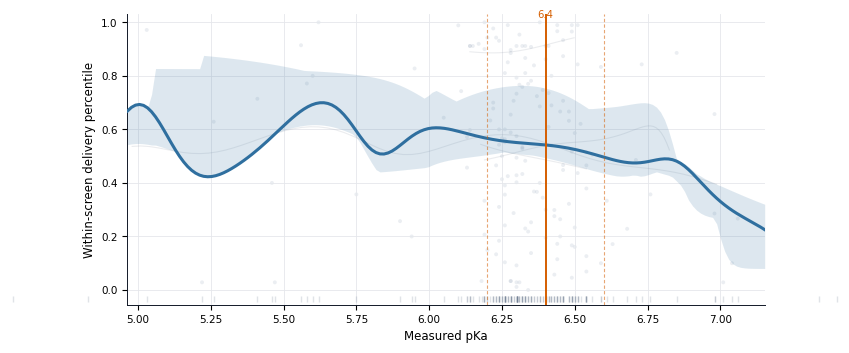

source data -> /content/cross_study_analysis/source_data/Supplementary_pKa_window_performance_screen_source.csv
source data -> /content/cross_study_analysis/source_data/Supplementary_pKa_window_performance_study_source.csv
source data -> /content/cross_study_analysis/source_data/Supplementary_pKa_window_performance_summary_source.csv
saved:
  /content/cross_study_analysis/supplementary_figures/Supplementary_pKa_window_performance.pdf
  /content/cross_study_analysis/supplementary_figures/Supplementary_pKa_window_performance.svg
  /content/cross_study_analysis/supplementary_figures/Supplementary_pKa_window_performance.png


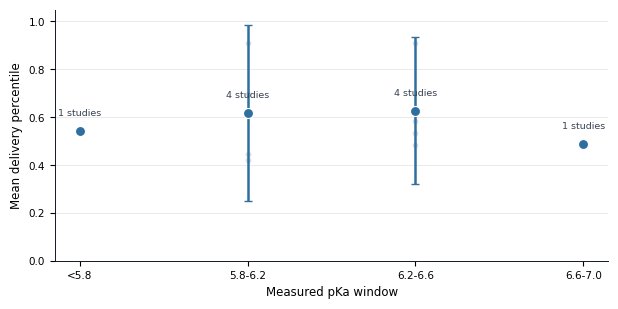

source data -> /content/cross_study_analysis/source_data/Fig3h_physicochemical_in_vitro_meta_analysis_coverage_qc.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_physicochemical_in_vitro_meta_analysis_screen_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_physicochemical_in_vitro_meta_analysis_study_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_physicochemical_in_vitro_meta_analysis_meta_analysis_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_physicochemical_in_vivo_meta_analysis_coverage_qc.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_physicochemical_in_vivo_meta_analysis_screen_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_physicochemical_in_vivo_meta_analysis_study_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3h_physicochemical_in_vivo_meta_analysis_meta_analysis_source.csv
sour

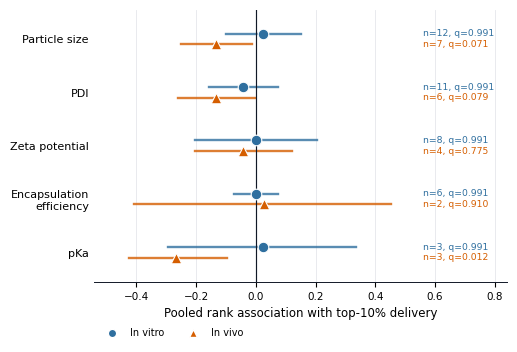

In [ ]:
# ============================================================
# Cell 16 — Extended physicochemical-property cross-study analysis
# One-cell analysis of measured LNP physicochemical properties:
# monotonic top10 meta-analysis, pKa nonlinear analyses, setting/cargo
# stratification, continuous-delivery sensitivity, and multivariable signature.
# Does not modify screen_lnp_table or the original LNPHub dataframe.
# ============================================================

from collections import OrderedDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patheffects as pe
import seaborn as sns
from scipy import stats
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import Normalize

# ------------------------------------------------------------
# 1. Measured physicochemical variables
# ------------------------------------------------------------

PHYSCHEM_CANDIDATES_CELL16 = [
    "particle_size_nm",
    "pdi",
    "zeta_potential_mv",
    "encapsulation_efficiency_percent",
    "measured_pka",
]

physchem_label_map_cell16 = {
    "particle_size_nm": "Particle size",
    "pdi": "PDI",
    "zeta_potential_mv": "Zeta potential",
    "encapsulation_efficiency_percent": "Encapsulation\nefficiency",
    "measured_pka": "pKa",
    "pka_distance_6_2": "Distance from pKa 6.2",
    "pka_distance_6_4": "Distance from pKa 6.4",
    "pka_distance_6_6": "Distance from pKa 6.6",
}

physchem_units_map_cell16 = {
    "particle_size_nm": "nm",
    "pdi": "",
    "zeta_potential_mv": "mV",
    "encapsulation_efficiency_percent": "%",
    "measured_pka": "",
    "pka_distance_6_2": "pKa units",
    "pka_distance_6_4": "pKa units",
    "pka_distance_6_6": "pKa units",
}

analysis_table_cell16 = screen_lnp_table.copy(deep=True)
physchem_features_cell16 = present_cols(analysis_table_cell16, PHYSCHEM_CANDIDATES_CELL16)

# Include any other clearly measured continuous LNP physicochemical fields already present.
for col in analysis_table_cell16.columns:
    low = str(col).lower()
    looks_physchem = any(
        key in low for key in [
            "particle_size", "diameter", "hydrodynamic", "pdi", "polydispersity",
            "zeta", "encapsulation", "entrapment", "measured_pka",
        ]
    )
    looks_metadata = any(key in low for key in ["method", "metric", "unit", "name", "smiles"])
    if looks_physchem and not looks_metadata and col not in physchem_features_cell16:
        s = pd.to_numeric(analysis_table_cell16[col], errors="coerce")
        if s.notna().sum() >= 6 and s.nunique(dropna=True) >= 2:
            physchem_features_cell16.append(col)

if not physchem_features_cell16:
    raise ValueError("No measured physicochemical features detected in screen_lnp_table.")

# ------------------------------------------------------------
# 2. Local helpers
# ------------------------------------------------------------

def _cell16_label(feature):
    return physchem_label_map_cell16.get(
        feature,
        pretty_feature_name(feature) if "pretty_feature_name" in globals() else clean_label(feature),
    )


def _cell16_format_q(q):
    if pd.isna(q):
        return "NA"
    return "<0.001" if q < 0.001 else f"{q:.3f}"


def _cell16_bh_fdr(p_values):
    p = np.asarray(p_values, dtype=float)
    q = np.full_like(p, np.nan, dtype=float)
    valid = np.isfinite(p)
    if valid.sum() == 0:
        return q
    pv = p[valid]
    order = np.argsort(pv)
    ranks = np.arange(1, len(pv) + 1)
    q_sorted = pv[order] * len(pv) / ranks
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]
    q_valid = np.empty_like(pv)
    q_valid[order] = np.minimum(q_sorted, 1.0)
    q[valid] = q_valid
    return q


def _cell16_fisher_z_from_r(r):
    r = np.clip(float(r), -0.999999, 0.999999)
    return np.arctanh(r)


def _cell16_r_from_fisher_z(z):
    return np.tanh(z)


def _cell16_screen_effect(data, feature, outcome_col="top10_flag", min_each=2):
    d = data[[feature, outcome_col]].copy()
    d[feature] = pd.to_numeric(d[feature], errors="coerce")
    d[outcome_col] = pd.to_numeric(d[outcome_col], errors="coerce")
    d = d.replace([np.inf, -np.inf], np.nan).dropna()

    if len(d) < 6 or d[feature].nunique() < 2 or d[outcome_col].nunique() < 2:
        return None

    if outcome_col == "top10_flag":
        n_top = int(d[outcome_col].sum())
        n_non = int(len(d) - n_top)
        if n_top < min_each or n_non < min_each:
            return None
    else:
        n_top = np.nan
        n_non = np.nan

    rho, p = stats.spearmanr(d[feature], d[outcome_col])
    if not np.isfinite(rho):
        return None

    variance = 1.0 / max(len(d) - 3, 1)
    return {
        "effect_r": float(rho),
        "effect_z": float(_cell16_fisher_z_from_r(rho)),
        "variance_z": float(variance),
        "p_screen": float(p) if np.isfinite(p) else np.nan,
        "n": int(len(d)),
        "n_top": int(d[outcome_col].sum()) if outcome_col == "top10_flag" else np.nan,
        "n_non_top": int(len(d) - d[outcome_col].sum()) if outcome_col == "top10_flag" else np.nan,
    }


def _cell16_random_effects_meta(effect, variance):
    effect = np.asarray(effect, dtype=float)
    variance = np.asarray(variance, dtype=float)
    keep = np.isfinite(effect) & np.isfinite(variance) & (variance > 0)
    effect = effect[keep]
    variance = variance[keep]
    k = len(effect)

    if k == 0:
        return {
            "k": 0, "pooled": np.nan, "ci_low": np.nan, "ci_high": np.nan,
            "se": np.nan, "p": np.nan, "tau2": np.nan, "i2": np.nan,
        }

    if k == 1:
        se = float(np.sqrt(variance[0]))
        z = float(effect[0] / se) if se > 0 else np.nan
        p = float(2 * stats.norm.sf(abs(z))) if np.isfinite(z) else np.nan
        return {
            "k": 1,
            "pooled": float(effect[0]),
            "ci_low": float(effect[0] - 1.96 * se),
            "ci_high": float(effect[0] + 1.96 * se),
            "se": se,
            "p": p,
            "tau2": 0.0,
            "i2": 0.0,
        }

    w = 1.0 / variance
    fixed = np.sum(w * effect) / np.sum(w)
    q_stat = np.sum(w * (effect - fixed) ** 2)
    df_q = k - 1
    c_val = np.sum(w) - np.sum(w ** 2) / np.sum(w)
    tau2 = max(0.0, (q_stat - df_q) / c_val) if c_val > 0 else 0.0

    wr = 1.0 / (variance + tau2)
    pooled = float(np.sum(wr * effect) / np.sum(wr))
    se = float(np.sqrt(1.0 / np.sum(wr)))
    ci_low = float(pooled - 1.96 * se)
    ci_high = float(pooled + 1.96 * se)
    z = pooled / se if se > 0 else np.nan
    p = float(2 * stats.norm.sf(abs(z))) if np.isfinite(z) else np.nan
    i2 = float(max(0.0, (q_stat - df_q) / q_stat) * 100) if q_stat > 0 else 0.0

    return {
        "k": int(k),
        "pooled": pooled,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "se": se,
        "p": p,
        "tau2": float(tau2),
        "i2": i2,
    }


def _cell16_combine_screen_effects_within_study(screen_effects):
    study_rows = []
    if screen_effects.empty:
        return pd.DataFrame(study_rows)

    for (feature, study_id), sdf in screen_effects.groupby(["feature", "study_id"], dropna=False):
        sdf = sdf.replace([np.inf, -np.inf], np.nan).dropna(subset=["effect_z", "variance_z"]).copy()
        sdf = sdf[sdf["variance_z"] > 0].copy()
        if sdf.empty:
            continue

        weights = 1.0 / sdf["variance_z"].astype(float)
        pooled_z = float(np.sum(weights * sdf["effect_z"].astype(float)) / np.sum(weights))
        pooled_var = float(1.0 / np.sum(weights))

        study_rows.append({
            "feature": feature,
            "study_id": study_id,
            "study_effect_z": pooled_z,
            "study_variance_z": pooled_var,
            "study_effect_r": float(_cell16_r_from_fisher_z(pooled_z)),
            "study_weight_fixed": float(np.sum(weights)),
            "n_screens": int(sdf["screen_id"].nunique()),
            "n_screen_lnp_rows": int(sdf["n"].sum()),
            "n_top_rows": int(sdf["n_top"].sum()) if "n_top" in sdf.columns else np.nan,
            "screen_ids": "; ".join(sorted(sdf["screen_id"].astype(str).unique())),
            "experimental_setting": "; ".join(sorted(sdf["experimental_setting"].dropna().astype(str).unique())) if "experimental_setting" in sdf.columns else "",
            "cargo_type": "; ".join(sorted(sdf["cargo_type"].dropna().astype(str).unique())) if "cargo_type" in sdf.columns else "",
        })

    return pd.DataFrame(study_rows)


def _cell16_analyze_feature_set(data, features, analysis_name, outcome_col="top10_flag"):
    coverage_rows = []
    screen_rows = []

    for feature in present_cols(data, features):
        s = pd.to_numeric(data[feature], errors="coerce").replace([np.inf, -np.inf], np.nan)
        valid = s.notna()
        screens_with_variation = 0
        analyzable_screen_ids = []

        for screen_id, sdf in data.groupby("screen_id", dropna=False):
            values = pd.to_numeric(sdf[feature], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
            if len(values) >= 2 and values.nunique() >= 2:
                screens_with_variation += 1

            eff = _cell16_screen_effect(sdf, feature, outcome_col=outcome_col)
            if eff is None:
                continue

            analyzable_screen_ids.append(screen_id)
            screen_rows.append({
                "analysis_name": analysis_name,
                "outcome_col": outcome_col,
                "feature": feature,
                "label": _cell16_label(feature),
                "screen_id": screen_id,
                "study_id": sdf["study_id"].iloc[0],
                "experimental_setting": sdf["experimental_setting"].iloc[0] if "experimental_setting" in sdf.columns else np.nan,
                "cargo_type": sdf["cargo_type"].iloc[0] if "cargo_type" in sdf.columns else np.nan,
                **eff,
            })

        analyzable_studies = data.loc[data["screen_id"].isin(analyzable_screen_ids), "study_id"].nunique()
        coverage_rows.append({
            "analysis_name": analysis_name,
            "outcome_col": outcome_col,
            "feature": feature,
            "label": _cell16_label(feature),
            "unit": physchem_units_map_cell16.get(feature, ""),
            "non_missing_screen_lnp_rows": int(valid.sum()),
            "screens_with_values": int(data.loc[valid, "screen_id"].nunique()),
            "studies_with_values": int(data.loc[valid, "study_id"].nunique()),
            "screens_with_within_screen_variation": int(screens_with_variation),
            "analyzable_screens": int(len(set(analyzable_screen_ids))),
            "analyzable_studies": int(analyzable_studies),
            "unique_numeric_values": int(s[valid].nunique()),
        })

    coverage = pd.DataFrame(coverage_rows)
    screen_effects = pd.DataFrame(screen_rows)
    study_effects = _cell16_combine_screen_effects_within_study(screen_effects)

    meta_rows = []
    if not study_effects.empty:
        for feature, fdf in study_effects.groupby("feature"):
            meta = _cell16_random_effects_meta(fdf["study_effect_z"], fdf["study_variance_z"])
            n_studies = int(meta.get("k", len(fdf)))
            n_screens = int(screen_effects.loc[screen_effects["feature"] == feature, "screen_id"].nunique())

            if np.isfinite(meta["pooled"]):
                pooled_effect = float(_cell16_r_from_fisher_z(meta["pooled"]))
                ci_low = float(_cell16_r_from_fisher_z(meta["ci_low"])) if np.isfinite(meta["ci_low"]) else np.nan
                ci_high = float(_cell16_r_from_fisher_z(meta["ci_high"])) if np.isfinite(meta["ci_high"]) else np.nan

                if n_studies > 1:
                    pi_crit = stats.t.ppf(0.975, max(n_studies - 2, 1)) if n_studies > 2 else 1.96
                    pi_half_width_z = float(pi_crit * np.sqrt(meta["tau2"] + meta["se"] ** 2))
                    prediction_low = float(_cell16_r_from_fisher_z(meta["pooled"] - pi_half_width_z))
                    prediction_high = float(_cell16_r_from_fisher_z(meta["pooled"] + pi_half_width_z))
                else:
                    prediction_low = np.nan
                    prediction_high = np.nan
            else:
                pooled_effect = ci_low = ci_high = prediction_low = prediction_high = np.nan

            pooled_sign = np.sign(pooled_effect) if np.isfinite(pooled_effect) else np.nan
            if np.isfinite(pooled_sign) and pooled_sign != 0:
                directional_consistency = float((np.sign(fdf["study_effect_r"]) == pooled_sign).mean())
            else:
                directional_consistency = np.nan

            meta_rows.append({
                "analysis_name": analysis_name,
                "outcome_col": outcome_col,
                "feature": feature,
                "label": _cell16_label(feature),
                "unit": physchem_units_map_cell16.get(feature, ""),
                "pooled_z": meta["pooled"],
                "pooled_effect": pooled_effect,
                "ci_low": ci_low,
                "ci_high": ci_high,
                "prediction_low": prediction_low,
                "prediction_high": prediction_high,
                "n_screens": n_screens,
                "n_studies": n_studies,
                "directional_consistency": directional_consistency,
                "tau2": meta["tau2"],
                "i2": meta["i2"],
                "p_value": meta["p"],
            })

    meta = pd.DataFrame(meta_rows)
    if not meta.empty:
        meta["q_value"] = _cell16_bh_fdr(meta["p_value"])
        meta["passes_robustness_rule"] = (
            (meta["n_screens"] >= 5)
            & (meta["n_studies"] >= 5)
            & (meta["q_value"] < 0.05)
            & (meta["directional_consistency"] >= 0.70)
        )
        meta["association_direction"] = np.select(
            [
                meta["passes_robustness_rule"] & (meta["pooled_effect"] > 0),
                meta["passes_robustness_rule"] & (meta["pooled_effect"] < 0),
            ],
            ["robust_positive", "robust_negative"],
            default="not_robust_or_inconsistent",
        )
        meta = meta.sort_values("pooled_effect", ascending=False).reset_index(drop=True)
    else:
        meta = pd.DataFrame(columns=[
            "analysis_name", "outcome_col", "feature", "label", "unit", "pooled_z", "pooled_effect",
            "ci_low", "ci_high", "prediction_low", "prediction_high", "n_screens", "n_studies",
            "directional_consistency", "tau2", "i2", "p_value", "q_value",
            "passes_robustness_rule", "association_direction",
        ])

    return coverage, screen_effects, study_effects, meta


def _cell16_save_meta_outputs(prefix, coverage, screen_effects, study_effects, meta):
    save_source(coverage, f"{prefix}_coverage_qc")
    save_source(screen_effects, f"{prefix}_screen_effects_source")
    save_source(study_effects, f"{prefix}_study_effects_source")
    save_source(meta, f"{prefix}_meta_analysis_source")

# ------------------------------------------------------------
# 3. Overall monotonic top10 analysis
# ------------------------------------------------------------

physchem_coverage_qc, physchem_screen_effects, physchem_study_effects, physchem_meta = _cell16_analyze_feature_set(
    analysis_table_cell16,
    physchem_features_cell16,
    analysis_name="overall_top10",
    outcome_col="top10_flag",
)
_cell16_save_meta_outputs(
    "Cell16_physicochemical_overall_top10",
    physchem_coverage_qc,
    physchem_screen_effects,
    physchem_study_effects,
    physchem_meta,
)

# ------------------------------------------------------------
# 4. pKa distance-from-optimum sensitivity analysis
# ------------------------------------------------------------

pka_distance_features = []
if "measured_pka" in analysis_table_cell16.columns:
    for optimum in [6.2, 6.4, 6.6]:
        col = f"pka_distance_{str(optimum).replace('.', '_')}"
        analysis_table_cell16[col] = (pd.to_numeric(analysis_table_cell16["measured_pka"], errors="coerce") - optimum).abs()
        pka_distance_features.append(col)

pka_distance_coverage, pka_distance_screen_effects, pka_distance_study_effects, pka_distance_meta = _cell16_analyze_feature_set(
    analysis_table_cell16,
    pka_distance_features,
    analysis_name="pka_distance_top10",
    outcome_col="top10_flag",
)
_cell16_save_meta_outputs(
    "Fig3h_pka_distance_optimum_sensitivity",
    pka_distance_coverage,
    pka_distance_screen_effects,
    pka_distance_study_effects,
    pka_distance_meta,
)

# ------------------------------------------------------------
# 5. pKa nonlinear performance landscape
# ------------------------------------------------------------

def _cell16_kernel_smooth(x, y, grid, bandwidth=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    ok = np.isfinite(x) & np.isfinite(y)
    x = x[ok]
    y = y[ok]
    if len(x) < 8 or np.unique(x).size < 4:
        return np.full_like(grid, np.nan, dtype=float)
    if bandwidth is None:
        bandwidth = max(0.12, 0.30 * np.nanstd(x))
    out = []
    for g in grid:
        w = np.exp(-0.5 * ((x - g) / bandwidth) ** 2)
        if np.sum(w) <= 1e-12:
            out.append(np.nan)
        else:
            out.append(float(np.sum(w * y) / np.sum(w)))
    return np.asarray(out, dtype=float)

pka_landscape_source = pd.DataFrame()
if "measured_pka" in analysis_table_cell16.columns:
    pka_work = analysis_table_cell16[["study_id", "screen_id", "measured_pka", "delivery_percentile", "top10_flag"]].copy()
    pka_work["measured_pka"] = pd.to_numeric(pka_work["measured_pka"], errors="coerce")
    pka_work["delivery_percentile"] = pd.to_numeric(pka_work["delivery_percentile"], errors="coerce")
    pka_work = pka_work.replace([np.inf, -np.inf], np.nan).dropna(subset=["measured_pka", "delivery_percentile"])

    eligible_pka_screens = []
    for screen_id, sdf in pka_work.groupby("screen_id", dropna=False):
        if len(sdf) >= 10 and sdf["measured_pka"].nunique() >= 4:
            eligible_pka_screens.append(screen_id)
    pka_landscape_source = pka_work[pka_work["screen_id"].isin(eligible_pka_screens)].copy()

save_source(pka_landscape_source, "Fig3h_pKa_delivery_landscape_source")

if not pka_landscape_source.empty:
    x_min = max(4.5, float(pka_landscape_source["measured_pka"].quantile(0.01)))
    x_max = min(8.8, float(pka_landscape_source["measured_pka"].quantile(0.99)))
    pka_grid = np.linspace(x_min, x_max, 160)
    pooled_trend = _cell16_kernel_smooth(
        pka_landscape_source["measured_pka"],
        pka_landscape_source["delivery_percentile"],
        pka_grid,
    )

    rng = np.random.default_rng(RANDOM_SEED)
    boot = []
    studies = pka_landscape_source["study_id"].dropna().astype(str).unique()
    for _ in range(200):
        sampled = rng.choice(studies, size=len(studies), replace=True)
        bdf = pd.concat([
            pka_landscape_source[pka_landscape_source["study_id"].astype(str) == s]
            for s in sampled
        ], ignore_index=True)
        boot.append(_cell16_kernel_smooth(bdf["measured_pka"], bdf["delivery_percentile"], pka_grid))
    boot = np.vstack(boot)
    trend_low = np.nanpercentile(boot, 2.5, axis=0)
    trend_high = np.nanpercentile(boot, 97.5, axis=0)
else:
    pka_grid = pooled_trend = trend_low = trend_high = np.array([])

pka_trend_source = pd.DataFrame({
    "measured_pka": pka_grid,
    "pooled_delivery_percentile": pooled_trend,
    "ci_low": trend_low,
    "ci_high": trend_high,
}) if len(pka_grid) else pd.DataFrame(columns=["measured_pka", "pooled_delivery_percentile", "ci_low", "ci_high"])
save_source(pka_trend_source, "Fig3h_pKa_delivery_landscape_trend_source")

fig, ax = plt.subplots(figsize=(7.2, 3.7))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

if pka_landscape_source.empty:
    ax.axis("off")
    ax.text(0.5, 0.5, "No screens with sufficient measured pKa variation", ha="center", va="center", fontsize=9)
else:
    for _, sdf in pka_landscape_source.groupby("screen_id", dropna=False):
        if len(sdf) < 10 or sdf["measured_pka"].nunique() < 4:
            continue
        grid = np.linspace(sdf["measured_pka"].quantile(0.05), sdf["measured_pka"].quantile(0.95), 70)
        trend = _cell16_kernel_smooth(sdf["measured_pka"], sdf["delivery_percentile"], grid)
        ax.plot(grid, trend, color="#9CA3AF", lw=0.8, alpha=0.20, zorder=1)

    ax.scatter(
        pka_landscape_source["measured_pka"],
        pka_landscape_source["delivery_percentile"],
        s=8,
        color="#94A3B8",
        alpha=0.18,
        edgecolor="none",
        zorder=0,
    )
    ax.fill_between(pka_grid, trend_low, trend_high, color="#2F6F9F", alpha=0.16, linewidth=0, zorder=2)
    ax.plot(pka_grid, pooled_trend, color="#2F6F9F", lw=2.2, zorder=3)
    ax.axvline(6.4, color="#D55E00", lw=1.4, zorder=4)
    for ref in [6.2, 6.6]:
        ax.axvline(ref, color="#D55E00", lw=0.8, ls=(0, (3, 2)), alpha=0.55, zorder=4)
    ax.plot(
        pka_landscape_source["measured_pka"],
        np.full(len(pka_landscape_source), -0.035),
        "|",
        color="#64748B",
        alpha=0.20,
        markersize=4,
        clip_on=False,
    )
    ax.set_xlabel("Measured pKa")
    ax.set_ylabel("Within-screen delivery percentile")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(-0.055, 1.03)
    ax.grid(color="#E5E7EB", lw=0.6)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.text(6.4, 1.01, "6.4", ha="center", va="bottom", fontsize=7.2, color="#D55E00")

fig.subplots_adjust(left=0.10, right=0.985, top=0.965, bottom=0.18)
save_figure(fig, "Fig3h_pKa_delivery_landscape", DIRS["panels"])
plt.show()

# ------------------------------------------------------------
# 6. pKa bin/window analysis
# ------------------------------------------------------------

pka_window_source = pd.DataFrame()
pka_window_study = pd.DataFrame()
pka_window_summary = pd.DataFrame()
if not pka_landscape_source.empty:
    bins = [-np.inf, 5.8, 6.2, 6.6, 7.0, np.inf]
    labels = ["<5.8", "5.8-6.2", "6.2-6.6", "6.6-7.0", ">7.0"]
    wdf = pka_landscape_source.copy()
    wdf["pka_window"] = pd.cut(wdf["measured_pka"], bins=bins, labels=labels, include_lowest=True)
    screen_bin_rows = []
    for (screen_id, pka_window), sdf in wdf.dropna(subset=["pka_window"]).groupby(["screen_id", "pka_window"], observed=True):
        if len(sdf) < 3:
            continue
        screen_bin_rows.append({
            "screen_id": screen_id,
            "study_id": sdf["study_id"].iloc[0],
            "pka_window": str(pka_window),
            "n_formulations": int(len(sdf)),
            "top10_fraction": float(pd.to_numeric(sdf["top10_flag"], errors="coerce").mean()),
            "mean_delivery_percentile": float(sdf["delivery_percentile"].mean()),
        })
    pka_window_source = pd.DataFrame(screen_bin_rows)

    study_rows = []
    for (study_id, pka_window), sdf in pka_window_source.groupby(["study_id", "pka_window"], dropna=False):
        weights = sdf["n_formulations"].astype(float)
        study_rows.append({
            "study_id": study_id,
            "pka_window": pka_window,
            "n_screens": int(sdf["screen_id"].nunique()),
            "n_formulations": int(sdf["n_formulations"].sum()),
            "top10_fraction": float(np.average(sdf["top10_fraction"], weights=weights)),
            "mean_delivery_percentile": float(np.average(sdf["mean_delivery_percentile"], weights=weights)),
        })
    pka_window_study = pd.DataFrame(study_rows)

    summary_rows = []
    for pka_window, sdf in pka_window_study.groupby("pka_window", dropna=False):
        vals = sdf["mean_delivery_percentile"].dropna().astype(float)
        if len(vals) == 0:
            continue
        se = vals.std(ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else np.nan
        tcrit = stats.t.ppf(0.975, len(vals) - 1) if len(vals) > 1 else np.nan
        summary_rows.append({
            "pka_window": pka_window,
            "n_studies": int(sdf["study_id"].nunique()),
            "n_screens": int(sdf["n_screens"].sum()),
            "n_formulations": int(sdf["n_formulations"].sum()),
            "mean_delivery_percentile": float(vals.mean()),
            "ci_low": float(vals.mean() - tcrit * se) if np.isfinite(se) else np.nan,
            "ci_high": float(vals.mean() + tcrit * se) if np.isfinite(se) else np.nan,
            "top10_fraction": float(sdf["top10_fraction"].mean()),
        })
    pka_window_summary = pd.DataFrame(summary_rows)
    pka_window_summary["pka_window"] = pd.Categorical(pka_window_summary["pka_window"], categories=labels, ordered=True)
    pka_window_summary = pka_window_summary.sort_values("pka_window").reset_index(drop=True)

save_source(pka_window_source, "Supplementary_pKa_window_performance_screen_source")
save_source(pka_window_study, "Supplementary_pKa_window_performance_study_source")
save_source(pka_window_summary, "Supplementary_pKa_window_performance_summary_source")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
if pka_window_summary.empty:
    ax.axis("off")
    ax.text(0.5, 0.5, "No pKa windows with sufficient data", ha="center", va="center", fontsize=9)
else:
    order = pka_window_summary["pka_window"].astype(str).tolist()
    xpos = np.arange(len(order))
    for _, row in pka_window_study.iterrows():
        if row["pka_window"] in order:
            ax.scatter(order.index(row["pka_window"]), row["mean_delivery_percentile"], s=18, color="#94A3B8", alpha=0.35, edgecolor="white", linewidth=0.3)
    ax.errorbar(
        xpos,
        pka_window_summary["mean_delivery_percentile"],
        yerr=[
            pka_window_summary["mean_delivery_percentile"] - pka_window_summary["ci_low"],
            pka_window_summary["ci_high"] - pka_window_summary["mean_delivery_percentile"],
        ],
        fmt="none",
        ecolor="#2F6F9F",
        elinewidth=1.8,
        capsize=3,
        zorder=3,
    )
    ax.scatter(xpos, pka_window_summary["mean_delivery_percentile"], s=52, color="#2F6F9F", edgecolor="white", linewidth=0.8, zorder=4)
    for x, (_, row) in zip(xpos, pka_window_summary.iterrows()):
        ax.text(x, row["mean_delivery_percentile"] + 0.055, f"{int(row['n_studies'])} studies", ha="center", va="bottom", fontsize=6.8, color="#374151")
    ax.set_xticks(xpos)
    ax.set_xticklabels(order)
    ax.set_ylabel("Mean delivery percentile")
    ax.set_xlabel("Measured pKa window")
    ax.set_ylim(0, min(1.05, max(0.62, float(pka_window_summary["ci_high"].max()) + 0.12)))
    ax.grid(axis="y", color="#E5E7EB", lw=0.6)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
fig.subplots_adjust(left=0.12, right=0.985, top=0.965, bottom=0.18)
save_figure(fig, "Supplementary_pKa_window_performance", DIRS["supplementary_figures"])
plt.show()

# ------------------------------------------------------------
# 7. In vitro vs in vivo physicochemical meta-analysis
# ------------------------------------------------------------

setting_results_cell16 = OrderedDict()
for setting in ["in_vitro", "in_vivo"]:
    sub = analysis_table_cell16[analysis_table_cell16["experimental_setting"].astype(str).str.lower().eq(setting)].copy()
    cov, scr, stu, meta = _cell16_analyze_feature_set(sub, physchem_features_cell16, analysis_name=f"{setting}_top10", outcome_col="top10_flag")
    setting_results_cell16[setting] = {"coverage": cov, "screen_effects": scr, "study_effects": stu, "meta": meta}
    _cell16_save_meta_outputs(f"Fig3h_physicochemical_{setting}_meta_analysis", cov, scr, stu, meta)

comparison_source = pd.concat([
    setting_results_cell16["in_vitro"]["meta"].assign(setting="in_vitro"),
    setting_results_cell16["in_vivo"]["meta"].assign(setting="in_vivo"),
], ignore_index=True)
save_source(comparison_source, "Fig3h_physicochemical_invitro_invivo_comparison_source")

fig, ax = plt.subplots(figsize=(7.8, max(3.2, 0.48 * len(physchem_features_cell16) + 1.25)))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
feature_order = [f for f in physchem_features_cell16 if f in comparison_source["feature"].unique()]
y_map = {f: i for i, f in enumerate(feature_order)}
markers = {"in_vitro": "o", "in_vivo": "^"}
colors = {"in_vitro": "#2F6F9F", "in_vivo": "#D55E00"}
offsets = {"in_vitro": -0.10, "in_vivo": 0.10}
if comparison_source.empty:
    ax.axis("off")
    ax.text(0.5, 0.5, "No setting-specific physicochemical associations", ha="center", va="center", fontsize=9)
else:
    x_candidates = comparison_source[["ci_low", "ci_high", "pooled_effect"]].stack().replace([np.inf, -np.inf], np.nan).dropna()
    x_abs = max(0.15, float(np.nanmax(np.abs(x_candidates))) if len(x_candidates) else 0.15)
    x_lim = min(0.99, x_abs * 1.20)
    for setting, sdf in comparison_source.groupby("setting"):
        for _, row in sdf.iterrows():
            if row["feature"] not in y_map or not np.isfinite(row["pooled_effect"]):
                continue
            y = y_map[row["feature"]] + offsets[setting]
            ax.plot([row["ci_low"], row["ci_high"]], [y, y], color=colors[setting], lw=1.7, alpha=0.80)
            ax.scatter(row["pooled_effect"], y, marker=markers[setting], s=58, color=colors[setting], edgecolor="white", linewidth=0.8, zorder=3)
            ax.text(x_lim * 1.03, y, f"n={int(row['n_studies'])}, q={_cell16_format_q(row['q_value'])}", ha="left", va="center", fontsize=6.7, color=colors[setting], clip_on=False)
    ax.axvline(0, color="#111827", lw=0.85)
    ax.set_xlim(-x_lim, x_lim * 1.55)
    ax.set_ylim(-0.55, len(feature_order) - 0.45)
    ax.invert_yaxis()
    ax.set_yticks(range(len(feature_order)))
    ax.set_yticklabels([_cell16_label(f) for f in feature_order], fontsize=8.0)
    ax.set_xlabel("Pooled rank association with top-10% delivery")
    ax.grid(axis="x", color="#E5E7EB", lw=0.6)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.legend(
        handles=[
            Line2D([0], [0], marker="o", linestyle="none", color="none", markerfacecolor=colors["in_vitro"], markeredgecolor="white", markersize=6, label="In vitro"),
            Line2D([0], [0], marker="^", linestyle="none", color="none", markerfacecolor=colors["in_vivo"], markeredgecolor="white", markersize=6, label="In vivo"),
        ],
        frameon=False,
        loc="lower left",
        bbox_to_anchor=(0.0, -0.24),
        ncol=2,
        fontsize=7.0,
    )
fig.subplots_adjust(left=0.25, right=0.78, top=0.965, bottom=0.22)
save_figure(fig, "Fig3h_physicochemical_invitro_invivo_comparison", DIRS["panels"])
plt.show()


In [ ]:
# Print significant physicochemical associations under the cell
# Run after Cell 16

from IPython.display import display
import pandas as pd
import numpy as np

comparison_source = pd.concat([
    setting_results_cell16["in_vitro"]["meta"].assign(setting="in_vitro"),
    setting_results_cell16["in_vivo"]["meta"].assign(setting="in_vivo"),
], ignore_index=True)

def fmt_q(q):
    if pd.isna(q):
        return "NA"
    return "<0.001" if q < 0.001 else f"{q:.3f}"

def fmt_ci(row):
    return f"{row['pooled_effect']:.3f} [{row['ci_low']:.3f}, {row['ci_high']:.3f}]"

table = comparison_source[
    comparison_source["q_value"].notna()
    & (comparison_source["q_value"] < 0.05)
].copy()

table["setting"] = table["setting"].replace({
    "in_vitro": "In vitro",
    "in_vivo": "In vivo",
})

table["feature"] = table["feature"].replace({
    "particle_size_nm": "Particle size",
    "pdi": "PDI",
    "zeta_potential_mv": "Zeta potential",
    "encapsulation_efficiency_percent": "Encapsulation efficiency",
    "measured_pka": "pKa",
})

table["effect_95CI"] = table.apply(fmt_ci, axis=1)
table["directional_consistency"] = (table["directional_consistency"] * 100).round(1).astype(str) + "%"
table["i2"] = table["i2"].round(1)
table["q_value"] = table["q_value"].map(fmt_q)

display(
    table[
        [
            "setting",
            "feature",
            "effect_95CI",
            "n_studies",
            "n_screens",
            "directional_consistency",
            "i2",
            "q_value",
            "passes_robustness_rule",
        ]
    ].reset_index(drop=True)
)

,setting,feature,effect_95CI,n_studies,n_screens,directional_consistency,i2,q_value,passes_robustness_rule
0,In vivo,pKa,"-0.268 [-0.425, -0.097]",3,3,66.7%,0.0,0.012,False


source data -> /content/cross_study_analysis/source_data/Supplementary_physicochemical_continuous_delivery_meta_analysis_coverage_qc.csv
source data -> /content/cross_study_analysis/source_data/Supplementary_physicochemical_continuous_delivery_meta_analysis_screen_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Supplementary_physicochemical_continuous_delivery_meta_analysis_study_effects_source.csv
source data -> /content/cross_study_analysis/source_data/Supplementary_physicochemical_continuous_delivery_meta_analysis_meta_analysis_source.csv
saved:
  /content/cross_study_analysis/supplementary_figures/Supplementary_physicochemical_continuous_delivery_meta_analysis.pdf
  /content/cross_study_analysis/supplementary_figures/Supplementary_physicochemical_continuous_delivery_meta_analysis.svg
  /content/cross_study_analysis/supplementary_figures/Supplementary_physicochemical_continuous_delivery_meta_analysis.png


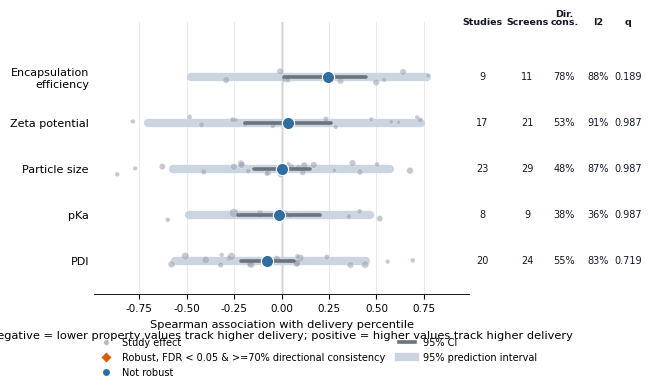

Physicochemical coverage/QC table


,feature,label,unit,non_missing_screen_lnp_rows,screens_with_values,studies_with_values,screens_with_within_screen_variation,analyzable_screens,analyzable_studies,unique_numeric_values
0,particle_size_nm,Particle size,nm,2856,44,35,39,23,18,936
1,pdi,PDI,,2250,38,30,30,20,16,250
2,zeta_potential_mv,Zeta potential,mV,1761,34,26,30,15,11,320
3,encapsulation_efficiency_percent,Encapsulation\nefficiency,%,1008,26,20,21,9,7,380
4,measured_pka,pKa,,729,22,20,14,6,6,110



Overall top10 physicochemical meta-analysis table


,feature,pooled_effect,ci_low,ci_high,prediction_low,prediction_high,n_screens,n_studies,directional_consistency,tau2,i2,p_value,q_value,passes_robustness_rule
0,zeta_potential_mv,0.008076,-0.145020,0.160795,-0.465311,0.477871,15,11,0.272727,0.045072,81.024126,0.918198,0.969948,False
1,encapsulation_efficiency_percent,-0.001839,-0.097182,0.093539,-0.233845,0.230366,9,7,0.571429,0.006077,39.647159,0.969948,0.969948,False
2,particle_size_nm,-0.034477,-0.132085,0.063793,-0.374121,0.313322,23,18,0.611111,0.026114,70.042150,0.491951,0.819919,False
3,pdi,-0.072448,-0.161090,0.017354,-0.355485,0.222760,20,16,0.625000,0.017347,62.418375,0.113710,0.284275,False
4,measured_pka,-0.203839,-0.347994,-0.050267,-0.403916,0.014849,6,6,0.500000,0.000000,0.000000,0.009587,0.047935,False



pKa distance-from-optimum sensitivity table


,feature,pooled_effect,ci_low,ci_high,prediction_low,prediction_high,n_screens,n_studies,directional_consistency,tau2,i2,p_value,q_value,passes_robustness_rule
0,pka_distance_6_6,0.180918,0.026500,0.326903,-0.038634,0.383806,6,6,0.500000,0.000000,0.000000,0.021898,0.065695,False
1,pka_distance_6_4,0.139025,-0.025610,0.296318,-0.126535,0.385991,6,6,0.500000,0.002124,4.027617,0.097575,0.110027,False
2,pka_distance_6_2,-0.126853,-0.276571,0.028877,-0.335599,0.093768,6,6,0.333333,0.000000,0.000000,0.110027,0.110027,False



Continuous delivery-percentile sensitivity table


,feature,pooled_effect,ci_low,ci_high,prediction_low,prediction_high,n_screens,n_studies,directional_consistency,tau2,i2,p_value,q_value,passes_robustness_rule
0,encapsulation_efficiency_percent,0.242505,0.013952,0.446976,-0.478027,0.767942,11,9,0.777778,0.091257,88.268487,0.037790,0.188948,False
1,zeta_potential_mv,0.035813,-0.194689,0.262567,-0.701777,0.736346,21,17,0.529412,0.166790,91.154517,0.763151,0.987372,False
2,particle_size_nm,0.001209,-0.147449,0.149814,-0.570890,0.572518,29,23,0.478261,0.091871,86.717964,0.987372,0.987372,False
3,measured_pka,-0.013425,-0.230533,0.204957,-0.485936,0.465159,9,8,0.375000,0.031943,35.975462,0.905362,0.987372,False
4,pdi,-0.075661,-0.212286,0.063866,-0.559978,0.447196,24,20,0.550000,0.065204,83.356501,0.287732,0.719329,False



Final robustness rule: n_screens >= 5 AND n_studies >= 5 AND q_value < 0.05 AND directional_consistency >= 0.70
Robust positive physicochemical properties: None
Robust negative physicochemical properties: None
Not robust or inconsistent physicochemical properties: Zeta potential, Encapsulation
efficiency, Particle size, PDI, pKa
pKa 6.4 distance interpretation: no robust evidence for a 6.4 optimum (effect=0.139, q=0.110).


In [ ]:

# ------------------------------------------------------------
# 9. Continuous delivery-percentile sensitivity analysis
# ------------------------------------------------------------

continuous_coverage, continuous_screen_effects, continuous_study_effects, continuous_meta = _cell16_analyze_feature_set(
    analysis_table_cell16,
    physchem_features_cell16,
    analysis_name="overall_delivery_percentile",
    outcome_col="delivery_percentile",
)
_cell16_save_meta_outputs(
    "Supplementary_physicochemical_continuous_delivery_meta_analysis",
    continuous_coverage,
    continuous_screen_effects,
    continuous_study_effects,
    continuous_meta,
)

# Use the same orchard style for continuous-delivery sensitivity.
plot_meta = continuous_meta.copy()
plot_meta = plot_meta[np.isfinite(plot_meta["pooled_effect"])].copy().sort_values("pooled_effect", ascending=False).reset_index(drop=True)
fig_h = max(3.2, 0.48 * len(plot_meta) + 1.35)
fig = plt.figure(figsize=(8.0, fig_h))
gs = gridspec.GridSpec(1, 2, width_ratios=[5.25, 2.35], wspace=0.015)
ax = fig.add_subplot(gs[0, 0])
ax_tab = fig.add_subplot(gs[0, 1], sharey=ax)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax_tab.set_facecolor("white")
robust_color = "#D55E00"
neutral_color = "#2F6F9F"
study_point_color = "#9CA3AF"
pi_color = "#CBD5E1"
ci_neutral = "#6B7280"
if plot_meta.empty:
    ax.axis("off")
    ax_tab.axis("off")
    ax.text(0.5, 0.5, "No continuous-delivery physicochemical associations", ha="center", va="center", fontsize=9)
else:
    y_positions = np.arange(len(plot_meta))
    feature_to_y = dict(zip(plot_meta["feature"], y_positions))
    study_plot = continuous_study_effects.merge(plot_meta[["feature", "tau2"]], on="feature", how="inner").copy()
    study_plot["y"] = study_plot["feature"].map(feature_to_y)
    study_plot["random_weight"] = 1.0 / (study_plot["study_variance_z"] + study_plot["tau2"].fillna(0.0))
    rng = np.random.default_rng(RANDOM_SEED)
    study_plot["y_jitter"] = study_plot["y"] + rng.uniform(-0.13, 0.13, size=len(study_plot))
    if len(study_plot):
        w = study_plot["random_weight"].replace([np.inf, -np.inf], np.nan)
        study_sizes = 10 + 34 * (w - w.min()) / (w.max() - w.min()) if w.notna().any() and w.max() > w.min() else pd.Series(18, index=study_plot.index)
        ax.scatter(study_plot["study_effect_r"], study_plot["y_jitter"], s=study_sizes, color=study_point_color, alpha=0.58, edgecolor="white", linewidth=0.35, zorder=2)
    for _, row in plot_meta.iterrows():
        y = feature_to_y[row["feature"]]
        robust = bool(row["passes_robustness_rule"])
        color = robust_color if robust else neutral_color
        ci_color = robust_color if robust else ci_neutral
        if np.isfinite(row["prediction_low"]) and np.isfinite(row["prediction_high"]):
            ax.plot([row["prediction_low"], row["prediction_high"]], [y, y], color=pi_color, lw=6.0, solid_capstyle="round", zorder=1)
        ax.plot([row["ci_low"], row["ci_high"]], [y, y], color=ci_color, lw=2.6, solid_capstyle="round", zorder=3)
        ax.scatter(row["pooled_effect"], y, s=78, marker="D" if robust else "o", color=color, edgecolor="white", linewidth=0.85, zorder=4)
    x_candidates = pd.concat([plot_meta["ci_low"], plot_meta["ci_high"], plot_meta["prediction_low"], plot_meta["prediction_high"], continuous_study_effects["study_effect_r"] if "study_effect_r" in continuous_study_effects else pd.Series(dtype=float)]).replace([np.inf, -np.inf], np.nan).dropna()
    x_abs = max(0.15, float(np.nanmax(np.abs(x_candidates))) if len(x_candidates) else 0.15)
    x_lim = min(0.99, x_abs * 1.16)
    ax.axvline(0, color="#111827", lw=0.85, zorder=0)
    ax.set_xlim(-x_lim, x_lim)
    ax.set_ylim(-1.18, len(plot_meta) - 0.28)
    ax.invert_yaxis()
    ax.set_yticks(y_positions)
    ax.set_yticklabels(plot_meta["label"], fontsize=8.0)
    ax.set_xlabel("Spearman association with delivery percentile\nnegative = lower property values track higher delivery; positive = higher values track higher delivery", fontsize=8.2)
    ax.grid(axis="x", color="#E5E7EB", lw=0.65)
    ax.set_axisbelow(True)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.2f}"))
    ax_tab.set_xlim(0, 1)
    ax_tab.set_ylim(ax.get_ylim())
    ax_tab.axis("off")
    table_x = {"studies": 0.05, "screens": 0.32, "consistency": 0.54, "i2": 0.74, "q": 0.92}
    header_y = -1.08
    ax_tab.text(table_x["studies"], header_y, "Studies", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"])
    ax_tab.text(table_x["screens"], header_y, "Screens", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"])
    ax_tab.text(table_x["consistency"], header_y, "Dir.\ncons.", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"], linespacing=0.90)
    ax_tab.text(table_x["i2"], header_y, "I2", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"])
    ax_tab.text(table_x["q"], header_y, "q", ha="center", va="bottom", fontsize=6.8, fontweight="bold", color=COLORS["ink"])
    for _, row in plot_meta.iterrows():
        y = feature_to_y[row["feature"]]
        robust = bool(row["passes_robustness_rule"])
        row_color = robust_color if robust else COLORS["ink"]
        weight = "bold" if robust else "normal"
        ax_tab.text(table_x["studies"], y, f"{int(row['n_studies']):,}", ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
        ax_tab.text(table_x["screens"], y, f"{int(row['n_screens']):,}", ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
        ax_tab.text(table_x["consistency"], y, f"{row['directional_consistency'] * 100:.0f}%" if pd.notna(row["directional_consistency"]) else "NA", ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
        ax_tab.text(table_x["i2"], y, f"{row['i2']:.0f}%" if pd.notna(row["i2"]) else "NA", ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
        ax_tab.text(table_x["q"], y, _cell16_format_q(row["q_value"]), ha="center", va="center", fontsize=7.0, color=row_color, fontweight=weight)
    ax.legend(
        handles=[
            Line2D([0], [0], marker="o", linestyle="none", color="none", markerfacecolor=study_point_color, markeredgecolor="white", markersize=4.5, alpha=0.75, label="Study effect"),
            Line2D([0], [0], marker="D", linestyle="none", color="none", markerfacecolor=robust_color, markeredgecolor="white", markersize=6.0, label="Robust, FDR < 0.05 & >=70% directional consistency"),
            Line2D([0], [0], marker="o", linestyle="none", color="none", markerfacecolor=neutral_color, markeredgecolor="white", markersize=6.0, label="Not robust"),
            Line2D([0], [0], color=ci_neutral, lw=2.6, label="95% CI"),
            Line2D([0], [0], color=pi_color, lw=6.0, label="95% prediction interval"),
        ],
        loc="lower left", bbox_to_anchor=(0.0, -0.32), frameon=False, ncol=2,
        handlelength=1.7, columnspacing=1.4, borderaxespad=0, fontsize=7.0,
    )
fig.subplots_adjust(left=0.30, right=0.985, top=0.965, bottom=0.24)
save_figure(fig, "Supplementary_physicochemical_continuous_delivery_meta_analysis", DIRS["supplementary_figures"])
plt.show()

# ------------------------------------------------------------
# 10. Print complete result tables and concise interpretation
# ------------------------------------------------------------

coverage_cols_cell16 = [
    "feature", "label", "unit", "non_missing_screen_lnp_rows", "screens_with_values",
    "studies_with_values", "screens_with_within_screen_variation", "analyzable_screens",
    "analyzable_studies", "unique_numeric_values",
]

result_cols_cell16 = [
    "feature", "pooled_effect", "ci_low", "ci_high", "prediction_low", "prediction_high",
    "n_screens", "n_studies", "directional_consistency", "tau2", "i2", "p_value",
    "q_value", "passes_robustness_rule",
]

print("Physicochemical coverage/QC table")
display(physchem_coverage_qc[coverage_cols_cell16])

print("\nOverall top10 physicochemical meta-analysis table")
display(physchem_meta[result_cols_cell16])

print("\npKa distance-from-optimum sensitivity table")
display(pka_distance_meta[result_cols_cell16] if not pka_distance_meta.empty else pka_distance_meta)

print("\nContinuous delivery-percentile sensitivity table")
display(continuous_meta[result_cols_cell16] if not continuous_meta.empty else continuous_meta)

robust_pos = physchem_meta[(physchem_meta["passes_robustness_rule"]) & (physchem_meta["pooled_effect"] > 0)]
robust_neg = physchem_meta[(physchem_meta["passes_robustness_rule"]) & (physchem_meta["pooled_effect"] < 0)]
inconsistent = physchem_meta[~physchem_meta["passes_robustness_rule"]]

print("\nFinal robustness rule: n_screens >= 5 AND n_studies >= 5 AND q_value < 0.05 AND directional_consistency >= 0.70")
print("Robust positive physicochemical properties:", ", ".join(robust_pos["label"].tolist()) if len(robust_pos) else "None")
print("Robust negative physicochemical properties:", ", ".join(robust_neg["label"].tolist()) if len(robust_neg) else "None")
print("Not robust or inconsistent physicochemical properties:", ", ".join(inconsistent["label"].tolist()) if len(inconsistent) else "None")

pka64 = pka_distance_meta[pka_distance_meta["feature"] == "pka_distance_6_4"] if not pka_distance_meta.empty else pd.DataFrame()
if len(pka64):
    row = pka64.iloc[0]
    print(
        "pKa 6.4 distance interpretation:",
        "closer-to-6.4 trend supported" if (row["pooled_effect"] < 0 and row["passes_robustness_rule"]) else "no robust evidence for a 6.4 optimum",
        f"(effect={row['pooled_effect']:.3f}, q={_cell16_format_q(row['q_value'])}).",
    )





source data -> /content/cross_study_analysis/source_data/Fig3i_pka_top10_range_by_setting_source.csv
source data -> /content/cross_study_analysis/source_data/Fig3i_pka_top10_range_by_setting_summary.csv
saved:
  /content/cross_study_analysis/panels/Fig3i_pka_top10_range_by_setting.pdf
  /content/cross_study_analysis/panels/Fig3i_pka_top10_range_by_setting.svg
  /content/cross_study_analysis/panels/Fig3i_pka_top10_range_by_setting.png


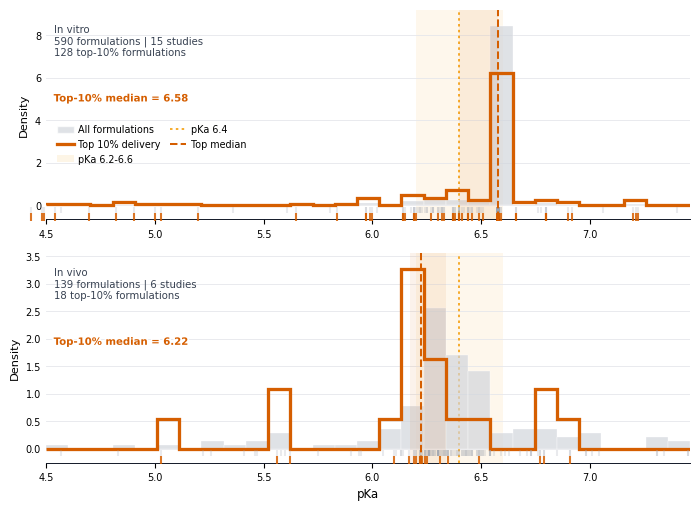

,experimental_setting,setting_label,group,n_formulations,n_studies,n_screens,median_pka,q1_pka,q3_pka,pka_6_2_to_6_6_fraction
0,in_vitro,In vitro,all_formulations,590,15,15,6.580,6.580,6.580,0.923729
1,in_vitro,In vitro,top10_formulations,128,14,14,6.580,6.400,6.580,0.742188
2,in_vivo,In vivo,all_formulations,139,6,7,6.340,6.240,6.505,0.640288
3,in_vivo,In vivo,top10_formulations,18,5,6,6.225,6.175,6.340,0.500000


In [ ]:
# ============================================================
# Cell 17 — pKa range of top-10% delivery formulations
# Discrete histogram comparison of measured pKa distributions
# for all formulations versus top-10% delivery formulations.
# ============================================================

from collections import OrderedDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

required_cols = [
    "study_id",
    "screen_id",
    "lnp_id",
    "experimental_setting",
    "measured_pka",
    "delivery_percentile",
    "top10_flag",
]
missing_cols = [c for c in required_cols if c not in screen_lnp_table.columns]
if missing_cols:
    raise ValueError(f"Missing required column(s): {missing_cols}")

pka_plot = screen_lnp_table[required_cols].copy()
pka_plot["measured_pka"] = pd.to_numeric(pka_plot["measured_pka"], errors="coerce")
pka_plot["delivery_percentile"] = pd.to_numeric(pka_plot["delivery_percentile"], errors="coerce")
pka_plot = pka_plot.replace([np.inf, -np.inf], np.nan)
pka_plot = pka_plot.dropna(subset=["measured_pka", "delivery_percentile", "top10_flag", "experimental_setting"]).copy()
pka_plot["top10_flag"] = pka_plot["top10_flag"].astype(bool)
pka_plot["experimental_setting"] = pka_plot["experimental_setting"].astype(str).str.strip()

settings = OrderedDict([
    ("in_vitro", "In vitro"),
    ("in_vivo", "In vivo"),
])
pka_plot = pka_plot[pka_plot["experimental_setting"].isin(settings.keys())].copy()

if pka_plot.empty:
    raise ValueError("No in vitro/in vivo rows with measured pKa and top10_flag were available.")

# Fixed bin edges preserve the original discrete histogram style.
bins = np.linspace(
    max(4.5, float(pka_plot["measured_pka"].quantile(0.005)) - 0.10),
    min(9.0, float(pka_plot["measured_pka"].quantile(0.995)) + 0.10),
    30,
)

summary_rows = []
for setting, label in settings.items():
    sdf = pka_plot[pka_plot["experimental_setting"] == setting].copy()
    top = sdf[sdf["top10_flag"]].copy()
    for group_name, gdf in [("all_formulations", sdf), ("top10_formulations", top)]:
        vals = gdf["measured_pka"].dropna()
        summary_rows.append({
            "experimental_setting": setting,
            "setting_label": label,
            "group": group_name,
            "n_formulations": int(len(gdf)),
            "n_studies": int(gdf["study_id"].nunique()) if len(gdf) else 0,
            "n_screens": int(gdf["screen_id"].nunique()) if len(gdf) else 0,
            "median_pka": float(vals.median()) if len(vals) else np.nan,
            "q1_pka": float(vals.quantile(0.25)) if len(vals) else np.nan,
            "q3_pka": float(vals.quantile(0.75)) if len(vals) else np.nan,
            "pka_6_2_to_6_6_fraction": float(vals.between(6.2, 6.6).mean()) if len(vals) else np.nan,
        })

pka_summary = pd.DataFrame(summary_rows)
save_source(pka_plot, "Fig3i_pka_top10_range_by_setting_source")
save_source(pka_summary, "Fig3i_pka_top10_range_by_setting_summary")

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(7.2, 5.15),
    sharex=True,
    gridspec_kw={"hspace": 0.16},
)
fig.patch.set_facecolor("white")

COL_ALL = "#D1D5DB"
COL_ALL_RUG = "#9CA3AF"
COL_TOP = "#D55E00"
COL_REF = "#F59E0B"
COL_INK = "#111827"
COL_MUTED = "#6B7280"
COL_GRID = "#E5E7EB"

for ax, (setting, label) in zip(axes, settings.items()):
    ax.set_facecolor("white")

    sdf = pka_plot[pka_plot["experimental_setting"] == setting].copy()
    top = sdf[sdf["top10_flag"]].copy()
    all_pka = sdf["measured_pka"]
    top_pka = top["measured_pka"]

    # Literature reference region behind the distributions.
    ax.axvspan(6.2, 6.6, color=COL_REF, alpha=0.075, linewidth=0, zorder=0)
    ax.axvline(6.4, color=COL_REF, linestyle=(0, (1.5, 2.0)), linewidth=1.2, zorder=1)

    # Background distribution: all measured LNPs.
    ax.hist(
        all_pka,
        bins=bins,
        density=True,
        color=COL_ALL,
        alpha=0.68,
        edgecolor="white",
        linewidth=0.35,
        label="All formulations",
        zorder=2,
    )

    # Top-10% distribution.
    ax.hist(
        top_pka,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2.35,
        color=COL_TOP,
        label="Top 10% delivery",
        zorder=4,
    )

    ymax = ax.get_ylim()[1]

    # Rug marks below baseline.
    ax.scatter(
        all_pka,
        np.full(len(all_pka), -0.025 * ymax),
        marker="|",
        s=18,
        color=COL_ALL_RUG,
        alpha=0.22,
        clip_on=False,
        zorder=5,
    )
    ax.scatter(
        top_pka,
        np.full(len(top_pka), -0.060 * ymax),
        marker="|",
        s=28,
        color=COL_TOP,
        alpha=0.85,
        clip_on=False,
        zorder=6,
    )

    # Median + IQR for top performers.
    top_summary = pka_summary[
        (pka_summary["experimental_setting"] == setting) &
        (pka_summary["group"] == "top10_formulations")
    ]
    if not top_summary.empty:
        top_row = top_summary.iloc[0]
        q1 = top_row["q1_pka"]
        median = top_row["median_pka"]
        q3 = top_row["q3_pka"]

        if pd.notna(q1) and pd.notna(q3):
            ax.axvspan(q1, q3, color=COL_TOP, alpha=0.080, linewidth=0, zorder=3)
        if pd.notna(median):
            ax.axvline(median, color=COL_TOP, lw=1.45, linestyle="--", zorder=7)

    # Left-side setting annotation.
    ax.text(
        0.012,
        0.93,
        (
            f"{label}\n"
            f"{len(sdf):,} formulations | {sdf['study_id'].nunique()} studies\n"
            f"{len(top_pka):,} top-10% formulations"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=7.3,
        color="#374151",
        linespacing=1.18,
    )

    # Top-10% median label shifted left below the setting statement.
    if not top_summary.empty and pd.notna(top_summary.iloc[0]["median_pka"]):
        median = top_summary.iloc[0]["median_pka"]
        txt = ax.text(
            0.012,
            0.60,
            f"Top-10% median = {median:.2f}",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=7.3,
            color=COL_TOP,
            fontweight="bold",
            zorder=10,
        )
        txt.set_path_effects([pe.withStroke(linewidth=2.4, foreground="white")])

    # Gentle in-panel pKa reference annotation replaces the bottom note.
    ref_txt = ax.text(
        6.4,
        ymax * 0.965,
        "",
        ha="center",
        va="top",
        fontsize=6.8,
        color="#B45309",
        linespacing=0.92,
        zorder=8,
    )
    ref_txt.set_path_effects([pe.withStroke(linewidth=2.2, foreground="white")])

    ax.set_ylabel("Density", fontsize=8.2)
    ax.grid(axis="y", color=COL_GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.set_ylim(-0.075 * ymax, ymax * 1.04)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=7.0)

axes[-1].set_xlabel("pKa", fontsize=8.5)
axes[-1].set_xlim(bins.min(), bins.max())

# sharex=True hides top-panel x tick labels by default; show them for readability.
axes[0].tick_params(axis="x", which="both", bottom=True, labelbottom=True, labelsize=7.0)
axes[1].tick_params(axis="x", which="both", labelsize=7.0)

legend_handles = [
    Patch(facecolor=COL_ALL, edgecolor="white", alpha=0.68, label="All formulations"),
    Line2D([0], [0], color=COL_TOP, lw=2.35, label="Top 10% delivery"),
    Patch(facecolor=COL_REF, edgecolor="none", alpha=0.10, label="pKa 6.2-6.6"),
    Line2D([0], [0], color=COL_REF, lw=1.2, linestyle=(0, (1.5, 2.0)), label="pKa 6.4"),
    Line2D([0], [0], color=COL_TOP, lw=1.45, linestyle="--", label="Top median"),
]
axes[0].legend(
    handles=legend_handles,
    frameon=False,
    fontsize=6.9,
    loc="upper left",
    bbox_to_anchor=(0.012, 0.47),
    ncol=2,
    handlelength=1.7,
    columnspacing=1.0,
    handletextpad=0.45,
    borderaxespad=0,
)

fig.subplots_adjust(left=0.09, right=0.985, top=0.985, bottom=0.105)
save_figure(fig, "Fig3i_pka_top10_range_by_setting", DIRS["panels"])
plt.show()

display(pka_summary)




In [ ]:
from google.colab import files
import shutil

folder_path = "/content/cross_study_analysis"
zip_path = "/content/cross_study_analysis"

shutil.make_archive(zip_path, "zip", folder_path)

files.download("/content/cross_study_analysis.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Supplementary Figs. 12-13 — In vitro/in vivo and cargo-specific comparisons

source data -> /content/cross_study_analysis/source_data/SuppFig12_in_vitro_in_vivo_descriptor_meta_source.csv
saved:
  /content/cross_study_analysis/supplementary_figures/Supplementary_Fig12_in_vitro_vs_in_vivo_descriptor_comparison.pdf
  /content/cross_study_analysis/supplementary_figures/Supplementary_Fig12_in_vitro_vs_in_vivo_descriptor_comparison.svg
  /content/cross_study_analysis/supplementary_figures/Supplementary_Fig12_in_vitro_vs_in_vivo_descriptor_comparison.png


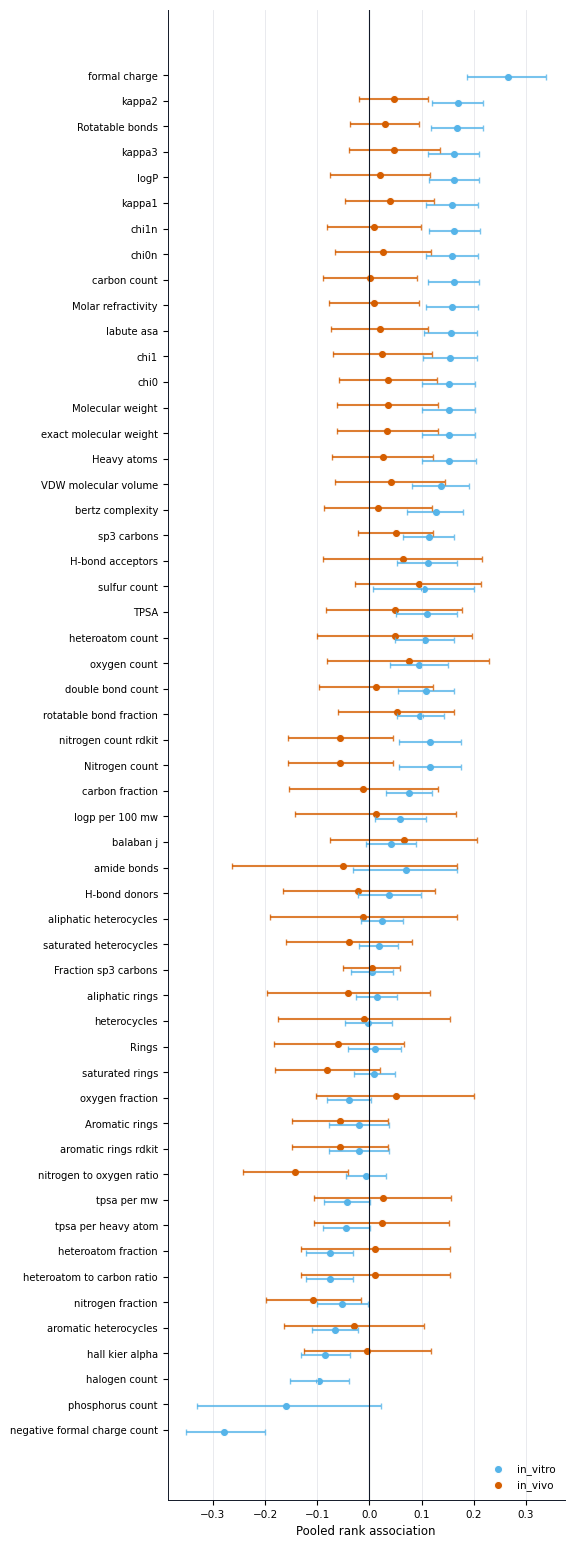

source data -> /content/cross_study_analysis/source_data/SuppFig13_mRNA_siRNA_descriptor_meta_source.csv
saved:
  /content/cross_study_analysis/supplementary_figures/Supplementary_Fig13_mRNA_vs_siRNA_descriptor_comparison.pdf
  /content/cross_study_analysis/supplementary_figures/Supplementary_Fig13_mRNA_vs_siRNA_descriptor_comparison.svg
  /content/cross_study_analysis/supplementary_figures/Supplementary_Fig13_mRNA_vs_siRNA_descriptor_comparison.png


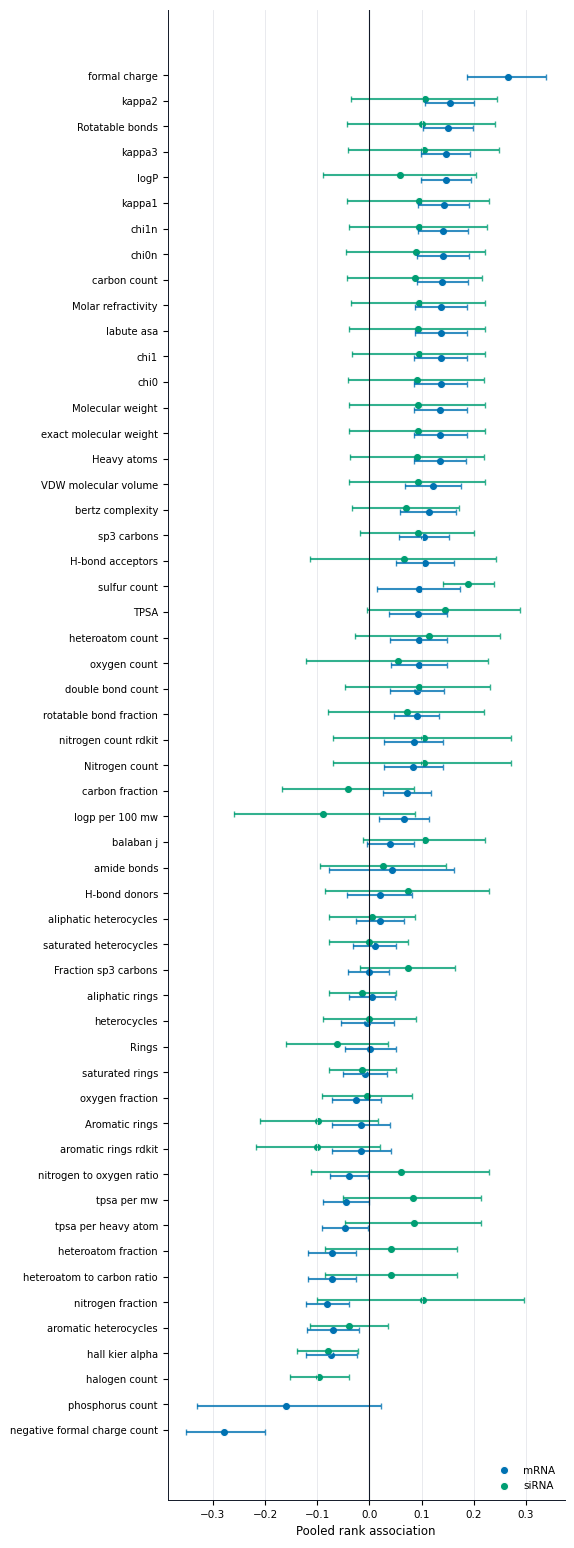

In [ ]:
def subgroup_meta_table(group_col, allowed_values, features):
    rows = []
    for value in allowed_values:
        sub = screen_lnp_table[screen_lnp_table[group_col] == value].copy()
        if sub["screen_id"].nunique() < 3:
            continue
        _, meta = meta_analyze_continuous_effects(sub, features, flag_col="top10_flag")
        if meta.empty:
            continue
        tmp = meta[["feature", "pooled_effect", "ci_low", "ci_high", "n_screens", "q_value"]].copy()
        tmp[group_col] = value
        rows.append(tmp)
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

setting_meta = subgroup_meta_table("experimental_setting", ["in_vitro", "in_vivo"], molecular_descriptors)
save_source(setting_meta, "SuppFig12_in_vitro_in_vivo_descriptor_meta_source")

if not setting_meta.empty:
    factors = descriptor_meta.sort_values("pooled_effect")["feature"].tolist()
    fig, ax = plt.subplots(figsize=(6.2, max(3.7, 0.31 * len(factors) + 1.0)))
    offsets = {"in_vitro": -0.08, "in_vivo": 0.08}
    colors = {"in_vitro": "#56B4E9", "in_vivo": "#D55E00"}
    ybase = {f: i for i, f in enumerate(factors)}
    for setting, sdf in setting_meta.groupby("experimental_setting"):
        y = [ybase[f] + offsets.get(setting, 0) for f in sdf["feature"]]
        ax.errorbar(sdf["pooled_effect"], y, xerr=[sdf["pooled_effect"] - sdf["ci_low"], sdf["ci_high"] - sdf["pooled_effect"]], fmt="none", ecolor=colors[setting], alpha=0.8, capsize=2)
        ax.scatter(sdf["pooled_effect"], y, s=34, color=colors[setting], edgecolor="white", linewidth=0.7, label=setting)
    ax.axvline(0, color=COLORS["ink"], lw=0.8)
    ax.set_yticks(range(len(factors)))
    ax.set_yticklabels([pretty_feature_name(f) for f in factors], fontsize=7.2)
    ax.set_xlabel("Pooled rank association")
    ax.legend(frameon=False, loc="lower right")
    ax.grid(axis="x", color="#E5E7EB", lw=0.6)
    fig.subplots_adjust(left=0.34, right=0.98, top=0.96, bottom=0.12)
    save_figure(fig, "Supplementary_Fig12_in_vitro_vs_in_vivo_descriptor_comparison", DIRS["supplementary_figures"])
    plt.show()

cargo_meta = subgroup_meta_table("cargo_type", ["mRNA", "siRNA"], molecular_descriptors)
save_source(cargo_meta, "SuppFig13_mRNA_siRNA_descriptor_meta_source")

if not cargo_meta.empty:
    factors = descriptor_meta.sort_values("pooled_effect")["feature"].tolist()
    fig, ax = plt.subplots(figsize=(6.2, max(3.7, 0.31 * len(factors) + 1.0)))
    offsets = {"mRNA": -0.08, "siRNA": 0.08}
    colors = {"mRNA": "#0072B2", "siRNA": "#009E73"}
    ybase = {f: i for i, f in enumerate(factors)}
    for cargo, sdf in cargo_meta.groupby("cargo_type"):
        y = [ybase[f] + offsets.get(cargo, 0) for f in sdf["feature"]]
        ax.errorbar(sdf["pooled_effect"], y, xerr=[sdf["pooled_effect"] - sdf["ci_low"], sdf["ci_high"] - sdf["pooled_effect"]], fmt="none", ecolor=colors[cargo], alpha=0.8, capsize=2)
        ax.scatter(sdf["pooled_effect"], y, s=34, color=colors[cargo], edgecolor="white", linewidth=0.7, label=cargo)
    ax.axvline(0, color=COLORS["ink"], lw=0.8)
    ax.set_yticks(range(len(factors)))
    ax.set_yticklabels([pretty_feature_name(f) for f in factors], fontsize=7.2)
    ax.set_xlabel("Pooled rank association")
    ax.legend(frameon=False, loc="lower right")
    ax.grid(axis="x", color="#E5E7EB", lw=0.6)
    fig.subplots_adjust(left=0.34, right=0.98, top=0.96, bottom=0.12)
    save_figure(fig, "Supplementary_Fig13_mRNA_vs_siRNA_descriptor_comparison", DIRS["supplementary_figures"])
    plt.show()

# Supplementary Fig. 17 — Cross-study recurrence score

In [ ]:
cat_features = ["il_class_group", "reaction_type", "il_head_class", "has_ester", "has_carbonate", "has_disulfide"]
categorical_screen_effects, categorical_meta = meta_analyze_categorical(screen_lnp_table, cat_features, flag_col="top10_flag", min_total=MIN_CLASS_SUPPORT_PER_SCREEN)
save_source(categorical_screen_effects, "categorical_screen_odds_ratio_source")
save_source(categorical_meta, "categorical_meta_analysis_source")

recurrence = categorical_meta[categorical_meta["n_screens"] >= 5].copy()
recurrence = recurrence.sort_values(["passes_robustness_rule", "directional_consistency", "pooled_log_or"], ascending=[False, False, False]).head(14)
save_source(recurrence, "SuppFig17_cross_study_recurrence_score_source")

fig, ax = plt.subplots(figsize=(7.0, max(3.5, 0.34 * len(recurrence) + 1.0)))
ax.axis("off")
if len(recurrence):
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.5, len(recurrence) - 0.5)
    max_screens = int(recurrence["n_screens"].max())
    for i, (_, row) in enumerate(recurrence.iloc[::-1].iterrows()):
        y = i
        label = row["level"] if row["feature"] in ["il_class_group", "reaction_type", "il_head_class"] else f"{row['feature']}={row['level']}"
        ax.text(0.00, y, clean_label(label), ha="left", va="center", fontsize=7.6, color=COLORS["ink"])
        n = int(row["n_screens"])
        support = int(round(row["directional_consistency"] * n))
        for j in range(max_screens):
            x0 = 0.43 + j * 0.026
            if j < n:
                face = COLORS["orange"] if j < support else "white"
                edge = COLORS["orange"]
                ax.scatter(x0, y, s=28, facecolor=face, edgecolor=edge, linewidth=0.8)
        ax.text(0.80, y, f"{row['directional_consistency']*100:.0f}%", ha="left", va="center", fontsize=7.4)
        ax.text(0.91, y, f"OR {row['pooled_or']:.2f}", ha="left", va="center", fontsize=7.4)
    ax.text(0.43, len(recurrence) - 0.05, "supporting screens", fontsize=7, color=COLORS["muted"], fontweight="bold")
    ax.text(0.80, len(recurrence) - 0.05, "recurrence", fontsize=7, color=COLORS["muted"], fontweight="bold")
save_figure(fig, "Supplementary_Fig17_cross_study_recurrence_score", DIRS["supplementary_figures"])
plt.show()

AttributeError: 'Normalize' object has no attribute 'sf'

#Top formulations and top ionizable lipids tables

In [ ]:
top_cols = present_cols(screen_lnp_table, [
    "study_id", "screen_id", "lnp_id", "il_id", "il_smiles", "delivery", "delivery_percentile",
    "experimental_setting", "cargo_type", "biological_model", "biological_target", "route_of_administration",
    "delivery_metric", "il_class", "il_class_group", "reaction_type", "il_head_class",
    "il_mol_ratio", "helper_lipid_mol_ratio", "cholesterol_mol_ratio", "peg_lipid_mol_ratio",
    "particle_size_nm", "pdi", "zeta_potential_mv", "encapsulation_efficiency_percent", "measured_pka",
])

top_formulations = (
    screen_lnp_table.sort_values(["screen_id", "delivery_percentile", "delivery"], ascending=[True, False, False])
    .groupby("screen_id")
    .head(5)[top_cols]
    .reset_index(drop=True)
)
save_table(top_formulations, "top_formulations_by_study")

lipid_screen = (
    screen_lnp_table.dropna(subset=["il_smiles"])
    .groupby(["screen_id", "il_smiles"], dropna=False)
    .agg(
        study_id=("study_id", "first"),
        il_id=("il_id", lambda s: s.dropna().iloc[0] if len(s.dropna()) else np.nan),
        il_class=("il_class", lambda s: s.dropna().iloc[0] if len(s.dropna()) else np.nan),
        il_class_group=("il_class_group", lambda s: s.dropna().iloc[0] if len(s.dropna()) else np.nan),
        reaction_type=("reaction_type", lambda s: s.dropna().iloc[0] if len(s.dropna()) else np.nan),
        il_head_class=("il_head_class", lambda s: s.dropna().iloc[0] if len(s.dropna()) else np.nan),
        median_delivery_percentile=("delivery_percentile", "median"),
        max_delivery_percentile=("delivery_percentile", "max"),
        n_formulations=("lnp_id", "nunique"),
    )
    .reset_index()
)
top_ionizable_lipids = (
    lipid_screen.sort_values(["screen_id", "median_delivery_percentile"], ascending=[True, False])
    .groupby("screen_id")
    .head(5)
    .reset_index(drop=True)
)
save_table(top_ionizable_lipids, "top_ionizable_lipids_by_study")

# Cross-study findings and draft Results subsection

In [ ]:
signif_descriptors = descriptor_meta[
    (descriptor_meta["n_screens"] >= MIN_META_SCREENS)
    & (descriptor_meta["q_value"] < 0.05)
    & (descriptor_meta["directional_consistency"] >= 0.70)
].sort_values("q_value")

signif_categorical = categorical_meta[
    (categorical_meta["n_screens"] >= MIN_META_SCREENS)
    & (categorical_meta["q_value"] < 0.05)
    & (categorical_meta["directional_consistency"] >= 0.70)
].sort_values("q_value")

signif_formulation = formulation_meta[
    (formulation_meta["n_screens"] >= MIN_META_SCREENS)
    & (formulation_meta["q_value"] < 0.05)
    & (formulation_meta["directional_consistency"] >= 0.70)
].sort_values("q_value") if not formulation_meta.empty else pd.DataFrame()

signif_physchem = physchem_meta[
    (physchem_meta["n_screens"] >= MIN_META_SCREENS)
    & (physchem_meta["q_value"] < 0.05)
    & (physchem_meta["directional_consistency"] >= 0.70)
].sort_values("q_value") if not physchem_meta.empty else pd.DataFrame()

summary_rows = [
    ("eligible_studies", eligible_summary["eligible_studies"]),
    ("eligible_screens", eligible_summary["eligible_screens"]),
    ("screen_lnp_rows", eligible_summary["screen_lnp_rows"]),
    ("unique_lnps", eligible_summary["unique_lnps"]),
    ("unique_il_smiles", eligible_summary["unique_il_smiles"]),
    ("top10_formulations", eligible_summary["top10_formulations"]),
    ("robust_molecular_descriptors", len(signif_descriptors)),
    ("robust_categorical_factors_total", len(signif_categorical)),
    ("robust_categorical_enrichments_or_gt_1", int((signif_categorical["pooled_or"] > 1).sum()) if len(signif_categorical) else 0),
    ("robust_categorical_depletions_or_lt_1", int((signif_categorical["pooled_or"] < 1).sum()) if len(signif_categorical) else 0),
    ("robust_formulation_ratios", len(signif_formulation)),
    ("robust_physicochemical_properties", len(signif_physchem)),
]
summary_df = pd.DataFrame(summary_rows, columns=["item", "value"])
summary_df.to_csv(DIRS["statistics"] / "cross_study_results_summary.csv", index=False)

def format_descriptor_sentence(row):
    return (
        f"{pretty_feature_name(row['feature'])} was associated with top delivery "
        f"(pooled rank effect={row['pooled_effect']:.2f}, 95% CI {row['ci_low']:.2f} to {row['ci_high']:.2f}, "
        f"q={row['q_value']:.3g}, {int(row['n_screens'])} screens, I2={row['i2']:.0f}%)."
    )

def format_cat_sentence(row):
    direction = "enriched among" if row["pooled_or"] > 1 else "depleted among"
    if row["feature"] in ["has_ester", "has_carbonate", "has_disulfide"]:
        try:
            level_label = f"{pretty_feature_name(row['feature'])} = {'present' if float(row['level']) == 1.0 else 'absent'}"
        except Exception:
            level_label = f"{pretty_feature_name(row['feature'])} = {clean_label(row['level'])}"
    else:
        level_label = clean_label(row["level"])
    return (
        f"{level_label} was {direction} top performers "
        f"(pooled OR={row['pooled_or']:.2f}, 95% CI {row['ci_low_or']:.2f} to {row['ci_high_or']:.2f}, "
        f"q={row['q_value']:.3g}, {int(row['n_screens'])} screens, I2={row['i2']:.0f}%)."
    )

lines = []
lines.append("Cross-study findings")
lines.append("====================")
for item, value in summary_rows:
    lines.append(f"{item}: {value}")
lines.append("")
lines.append("Robust molecular descriptors:")
if len(signif_descriptors):
    for _, row in signif_descriptors.iterrows():
        lines.append("- " + format_descriptor_sentence(row))
else:
    lines.append("- None satisfied all pre-specified robustness criteria.")
lines.append("")
lines.append("Robust categorical factors:")
if len(signif_categorical):
    for _, row in signif_categorical.iterrows():
        lines.append("- " + format_cat_sentence(row))
else:
    lines.append("- None satisfied all pre-specified robustness criteria.")
lines.append("")
lines.append("Robust formulation-ratio associations:")
if len(signif_formulation):
    for _, row in signif_formulation.iterrows():
        lines.append("- " + format_descriptor_sentence(row))
else:
    lines.append("- None satisfied all pre-specified robustness criteria.")
lines.append("")
lines.append("Robust physicochemical associations:")
if len(signif_physchem):
    for _, row in signif_physchem.iterrows():
        lines.append("- " + format_descriptor_sentence(row))
else:
    lines.append("- None satisfied all pre-specified robustness criteria; these measured properties are treated as associations, not causal determinants.")

summary_text = "\n".join(lines)
(DIRS["statistics"] / "cross_study_results_summary.txt").write_text(summary_text)
print(summary_text)

draft_lines = []
draft_lines.append(r"\subsection{Cross-study screening identifies chemical design factors associated with delivery}")
draft_lines.append("")
draft_lines.append(
    f"To compare delivery performance across heterogeneous LNPHub studies without pooling raw assay values, "
    f"we defined {eligible_summary['eligible_screens']:,} screening contexts from {eligible_summary['eligible_studies']:,} studies and ranked formulations only within each context. "
    f"Repeated measurements of the same LNP within a context were collapsed by median delivery, yielding {eligible_summary['screen_lnp_rows']:,} screen--formulation observations, "
    f"{eligible_summary['unique_lnps']:,} unique LNP identifiers, and {eligible_summary['unique_il_smiles']:,} unique ionizable-lipid structures. "
    f"Top-performing formulations were defined as the top 10\\% within each context with ties preserved, resulting in {eligible_summary['top10_formulations']:,} top-performing screen--formulation observations."
)
if len(signif_descriptors):
    desc_text = " ".join(format_descriptor_sentence(row) for _, row in signif_descriptors.head(4).iterrows())
    draft_lines.append(desc_text)
else:
    draft_lines.append(
        "No molecular descriptor satisfied all pre-specified robustness criteria after random-effects meta-analysis, FDR correction, and directional-consistency filtering, indicating that descriptor-level trends were heterogeneous across screens."
    )
if len(signif_categorical):
    cat_text = " ".join(format_cat_sentence(row) for _, row in signif_categorical.head(4).iterrows())
    draft_lines.append(cat_text)
    if not (signif_categorical["pooled_or"] > 1).any():
        draft_lines.append(
            "Notably, no categorical lipid annotation showed a robust positive enrichment among top-performing formulations under the pre-specified criteria; the robust categorical signals were depletions, underscoring screen-level heterogeneity."
        )
else:
    draft_lines.append(
        "Categorical lipid annotations showed screen-specific enrichments, but no category met all robustness criteria for a cross-study claim after accounting for screen-level replication and multiple testing."
    )
if len(signif_formulation):
    draft_lines.append("Formulation-ratio analysis identified recurrent associations among the following variables: " + "; ".join(format_descriptor_sentence(row) for _, row in signif_formulation.head(3).iterrows()))
else:
    draft_lines.append("Formulation-ratio effects did not meet the full robustness criteria, so these results are reported as exploratory screen-level associations.")
if len(signif_physchem):
    draft_lines.append("Measured physicochemical properties associated with delivery included: " + "; ".join(format_descriptor_sentence(row) for _, row in signif_physchem.head(3).iterrows()) + " Because these measurements may lie downstream of formulation design, they are interpreted as associations rather than causal determinants.")
else:
    draft_lines.append("Measured physicochemical properties were analyzed separately and did not satisfy the full robustness criteria; these properties should therefore be interpreted cautiously as downstream correlates of delivery.")
draft_lines.append(
    "Together, this cross-study framework prioritizes factors that recur across independent screens while making heterogeneity and underpowered comparisons explicit."
)

draft_text = "\n\n".join(draft_lines)
(DIRS["statistics"] / "results_subsection_draft.tex").write_text(draft_text)
print("\nDraft Results subsection written to:", DIRS["statistics"] / "results_subsection_draft.tex")

In [ ]:
# ============================================================
# Assemble final Figure 3
#
# Independent column layout with per-panel scaling.
# Labels are attached to each panel but can sit above the panel,
# so spacing changes do not make labels overlap the content.
# ============================================================

import fitz  # PyMuPDF
import numpy as np
from pathlib import Path

BASE = Path("/content")

panel_files = {
    "a": BASE / "Fig3_1.pdf",
    "b": BASE / "Fig3_2.pdf",
    "c": BASE / "Fig3_3.pdf",
    "d": BASE / "Fig3_6.pdf",
    "e": BASE / "Fig3_4.pdf",
    "f": BASE / "Fig3_7.pdf",
    "g": BASE / "Fig3_5.pdf",
}

OUT_PDF = BASE / "Figure3_final_custom_layout.pdf"
OUT_PNG = BASE / "Figure3_final_custom_layout_600dpi.png"

for lab, f in panel_files.items():
    if not f.exists():
        raise FileNotFoundError(f"Missing file for panel {lab}: {f}")

def detect_content_clip(pdf_path, dpi=240, white_threshold=252, padding_pt=0.4):
    doc = fitz.open(pdf_path)
    page = doc[0]

    scale = dpi / 72.0
    pix = page.get_pixmap(
        matrix=fitz.Matrix(scale, scale),
        alpha=False,
        annots=True,
    )

    arr = np.frombuffer(pix.samples, dtype=np.uint8).reshape(
        pix.height,
        pix.width,
        pix.n,
    )
    rgb = arr[:, :, :3]

    mask = np.any(rgb < white_threshold, axis=2)
    ys, xs = np.where(mask)

    if len(xs) == 0:
        clip = page.rect
    else:
        x0 = max(0, xs.min() / scale - padding_pt)
        x1 = min(page.rect.width, (xs.max() + 1) / scale + padding_pt)
        y0 = max(0, ys.min() / scale - padding_pt)
        y1 = min(page.rect.height, (ys.max() + 1) / scale + padding_pt)
        clip = fitz.Rect(x0, y0, x1, y1)

    doc.close()
    return clip

clips = {
    lab: detect_content_clip(path)
    for lab, path in panel_files.items()
}

aspects = {
    lab: clips[lab].width / clips[lab].height
    for lab in panel_files
}

def natural_height(label, width):
    return width / aspects[label]

MM_TO_PT = 72 / 25.4
PAGE_WIDTH = 180 * MM_TO_PT

OUTER_MARGIN = 0.0
H_GAP = 2.0

# Controls spacing between panels.
V_GAP_LEFT = 15.0
V_GAP_RIGHT = 2.5

# Controls how far the first panel in each column starts from the top.
LEFT_COL_TOP_OFFSET = 18.0
RIGHT_COL_TOP_OFFSET = 0.0

INNER_W = PAGE_WIDTH - 2 * OUTER_MARGIN
COL_W = (INNER_W - H_GAP) / 2

# Per-panel scale factors.
PANEL_SCALE = {
    "a": 1.00,  # Fig3_1
    "b": 1.00,  # Fig3_2
    "c": 0.90,  # Fig3_3
    "d": 0.90,  # Fig3_6
    "e": 0.94,  # Fig3_4
    "f": 0.90,  # Fig3_7
    "g": 0.88,  # Fig3_5
}

left_col = ["a", "c", "d", "f"]
right_col = ["b", "e", "g"]

def panel_width(label):
    return COL_W * PANEL_SCALE.get(label, 1.0)

def panel_height(label):
    return natural_height(label, panel_width(label))

def column_height(labels, v_gap):
    return (
        sum(panel_height(lab) for lab in labels)
        + v_gap * (len(labels) - 1)
    )

left_height = LEFT_COL_TOP_OFFSET + column_height(left_col, V_GAP_LEFT)
right_height = RIGHT_COL_TOP_OFFSET + column_height(right_col, V_GAP_RIGHT)

PAGE_HEIGHT = OUTER_MARGIN + max(left_height, right_height) + OUTER_MARGIN

print(
    "Figure size:",
    f"{PAGE_WIDTH / MM_TO_PT:.1f} mm x {PAGE_HEIGHT / MM_TO_PT:.1f} mm",
)

out = fitz.open()
page = out.new_page(width=PAGE_WIDTH, height=PAGE_HEIGHT)

DRAW_PANEL_LABELS = True

# Label offset relative to each panel.
# Negative y places label above the panel content.
LABEL_X_OFFSET = 2.0
LABEL_Y_OFFSET = -2.0

# Optional per-label fine control.
# More negative y = higher label.
# More positive y = lower label.
LABEL_OFFSET_OVERRIDE = {
    "a": (2.0, -2.0),
    "b": (2.0, -2.0),
    "c": (2.0, -2.0),
    "d": (2.0, -2.0),
    "e": (2.0, -2.0),
    "f": (2.0, -2.0),
    "g": (2.0, -2.0),
}

def draw_panel_label(label, rect):
    if not DRAW_PANEL_LABELS:
        return

    dx, dy = LABEL_OFFSET_OVERRIDE.get(
        label,
        (LABEL_X_OFFSET, LABEL_Y_OFFSET),
    )

    page.insert_text(
        (rect.x0 + dx, rect.y0 + dy),
        label,
        fontsize=12,
        fontname="hebo",
        color=(0, 0, 0),
        overlay=True,
    )

def place_panel(label, rect):
    src = fitz.open(panel_files[label])

    page.show_pdf_page(
        rect,
        src,
        0,
        clip=clips[label],
        keep_proportion=True,
        overlay=True,
    )
    src.close()

    draw_panel_label(label, rect)

def place_column(labels, x0, v_gap, align="left", top_offset=0.0):
    y = OUTER_MARGIN + top_offset

    for lab in labels:
        w = panel_width(lab)
        h = panel_height(lab)

        if align == "left":
            x = x0
        elif align == "right":
            x = x0 + COL_W - w
        else:
            x = x0 + (COL_W - w) / 2

        rect = fitz.Rect(
            x,
            y,
            x + w,
            y + h,
        )

        place_panel(lab, rect)
        y += h + v_gap

x_left = OUTER_MARGIN
x_right = OUTER_MARGIN + COL_W + H_GAP

place_column(
    left_col,
    x_left,
    V_GAP_LEFT,
    align="left",
    top_offset=LEFT_COL_TOP_OFFSET,
)

place_column(
    right_col,
    x_right,
    V_GAP_RIGHT,
    align="left",
    top_offset=RIGHT_COL_TOP_OFFSET,
)

out.save(OUT_PDF, garbage=4, deflate=True)
out.close()

print(f"Saved PDF: {OUT_PDF}")

doc = fitz.open(OUT_PDF)
page0 = doc[0]

dpi = 600
zoom = dpi / 72.0
pix = page0.get_pixmap(
    matrix=fitz.Matrix(zoom, zoom),
    alpha=False,
)
pix.save(OUT_PNG)

doc.close()

print(f"Saved PNG: {OUT_PNG}")

Figure size: 180.0 mm x 224.7 mm
Saved PDF: /content/Figure3_final_custom_layout.pdf
Saved PNG: /content/Figure3_final_custom_layout_600dpi.png
